# PPC Encoding Analysis

Comprehensive analysis of how PPC encodes decision variables and how this is modulated by sensory context (visual / audio / congruent multisensory).

**Models analysed:**
- **Model 1 (base):** 9 behavioural predictor groups — position, audio context/stim, visual context/stim, velocity, choice spatial, turn onset, outcome
- **Coupling model:** Model 1 + functional coupling (top-5 population PCs × temporal lag bases)

**Structure:**
- Section 0 — Setup & Data Loading
- Section 1 — Model 1: Population composition & behavioural encoding
- Section 2 — Model 1: Context modulation
- Section 3 — Coupling model: Population dynamics
- Section 4 — Coupling × Context
- Section 5 — Cross-model comparison & summary


## Section 0 — Setup & Data Loading

In [1]:
import os, sys, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib import rcParams
from scipy import stats
from sklearn.decomposition import PCA

GLM_DIR = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model'
if GLM_DIR not in sys.path:
    sys.path.insert(0, GLM_DIR)
from core.session_pipeline import BASE_DATA_PATH, MODEL_1_DIR

# ── Plot style ─────────────────────────────────────────────────────────────────
rcParams['font.family']       = 'Arial'
rcParams['axes.spines.right'] = False
rcParams['axes.spines.top']   = False
rcParams['axes.labelsize']    = 7
rcParams['xtick.labelsize']   = 7
rcParams['ytick.labelsize']   = 7
rcParams['figure.dpi']        = 200

# ── Constants ──────────────────────────────────────────────────────────────────
CONTEXT_NAMES  = {0: 'CG', 1: 'Visual', 2: 'Audio'}
CTX_COLORS     = {0: '#9B59B6', 1: '#EC008C', 2: '#27AAE1'}
CTX_COLORS_STR = {'cg': '#9B59B6', 'visual': '#EC008C', 'audio': '#27AAE1'}

M1_GROUPS = [
    'position_only',
    'audio_context', 'audio_stim',
    'visual_context', 'visual_stim',
    'velocity',
    'choice_spatial', 'turn_onset',
    'outcome',
]
COUPLING_GROUPS = M1_GROUPS + [f'network_pc{i+1}' for i in range(5)]

GROUP_LABELS = {
    'position_only':  'Position',
    'audio_context':  'Audio Ctx',
    'audio_stim':     'Audio Stim',
    'visual_context': 'Visual Ctx',
    'visual_stim':    'Visual Stim',
    'velocity':       'Velocity',
    'choice_spatial': 'Choice',
    'turn_onset':     'Turn Onset',
    'outcome':        'Outcome',
    **{f'network_pc{i+1}': f'Net PC{i+1}' for i in range(5)},
}
GROUP_COLORS = {
    'position_only':  '#9B59B6',
    'audio_context':  '#27AAE1',
    'audio_stim':     '#1A7AAF',
    'visual_context': '#EC008C',
    'visual_stim':    '#A8005E',
    'velocity':       '#2ECC71',
    'choice_spatial': '#E67E22',
    'turn_onset':     '#E74C3C',
    'outcome':        '#F39C12',
    **{f'network_pc{i+1}': plt.cm.Greys(0.4 + 0.1*i) for i in range(5)},
}
CLASS_COLORS = {
    'velocity':       '#2ECC71',
    'choice_spatial': '#E67E22',
    'turn_onset':     '#E74C3C',
    'outcome':        '#F39C12',
    'audio_context':  '#27AAE1',
    'audio_stim':     '#1A7AAF',
    'visual_context': '#EC008C',
    'visual_stim':    '#A8005E',
    'position_only':  '#9B59B6',
    'mixed':          '#95A5A6',
    'unclassified':   '#BDC3C7',
}

print('✓ Setup complete')

✓ Setup complete


In [3]:
# ── Session registry ───────────────────────────────────────────────────────────
PPC_AVC = {
    'IS-2-1L': ['2025-03-10', '2025-03-11', '2025-03-12', '2025-03-13',
                '2025-03-20', '2025-03-26', '2025-04-02', '2025-04-04',
                '2025-04-08', '2025-04-09', '2025-05-05',
                '2025-05-28', '2025-05-30', '2025-11-20'],
    'IS-3-1R': ['2024-12-23', '2024-12-24'],
    'JP-2-1L': ['2025-08-19', '2025-08-26', '2025-09-16', '2025-09-17',
                '2025-09-19', '2025-09-22'],
    'KA-1-00': ['2025-12-16', '2026-01-08'],
    'KA-2-00': ['2026-01-08', '2026-01-13', '2026-01-14'],
    'KO-5-1L': ['2026-03-05', '2026-03-06', '2026-03-12', '2026-03-13', '2026-03-24'],
    'KO-6-00': ['2026-03-12', '2026-03-23', '2026-03-25'],
}
total = sum(len(v) for v in PPC_AVC.values())
print(f'Registry: {len(PPC_AVC)} mice | {total} sessions')

Registry: 7 mice | 35 sessions


In [4]:
# ── Generic session loader ─────────────────────────────────────────────────────
def load_sessions(sessions_dict, model_dir, prefix):
    """
    Load full + lesion results for a given model.
    model_dir : e.g. 'Model_1_results' or 'coupling_results'
    prefix    : e.g. 'glm_M1' or 'glm_coupling'
    """
    sessions = []
    for mouse_ID, dates in sessions_dict.items():
        for date in dates:
            res_dir     = os.path.join(BASE_DATA_PATH, mouse_ID, date, model_dir)
            full_path   = os.path.join(res_dir, f'{prefix}_full.pkl')
            lesion_path = os.path.join(res_dir, f'{prefix}_lesion_all.pkl')
            if not os.path.exists(full_path):
                continue
            with open(full_path, 'rb') as f:
                full_res = pickle.load(f)
            lesion_res = None
            if os.path.exists(lesion_path):
                with open(lesion_path, 'rb') as f:
                    lesion_res = pickle.load(f)
            n = full_res['test_frac_dev'].shape[0]
            sessions.append(dict(mouse_ID=mouse_ID, date=date,
                                 full_res=full_res, lesion_res=lesion_res))
            lesion_tag = '✓ lesion' if lesion_res else '— no lesion'
            print(f'  [OK] {mouse_ID}/{date}  n={n}  {lesion_tag}')
    print(f'Loaded {len(sessions)} sessions')
    return sessions


def build_neuron_df(sessions, resp_threshold=0.1, mixed_margin=0.5):
    """Build per-neuron DataFrame from loaded sessions."""
    rows = []
    for s in sessions:
        mouse_ID, date = s['mouse_ID'], s['date']
        full_res, lesion_res = s['full_res'], s['lesion_res']
        n = len(full_res['test_frac_dev'])

        base = {
            'mouse_ID':         [mouse_ID]*n,
            'date':             [date]*n,
            'neuron_idx':       np.arange(n),
            'n_neurons':        n,
            'test_frac_dev':    full_res['test_frac_dev'],
            'cv_frac_dev':      full_res.get('cv_frac_dev', np.full(n, np.nan)),
            'test_r2':          full_res.get('test_trial_avg_r2', np.full(n, np.nan)),
            'frac_dev_cg':      full_res['test_frac_dev_per_ctx'].get(0, np.zeros(n)),
            'frac_dev_visual':  full_res['test_frac_dev_per_ctx'].get(1, np.zeros(n)),
            'frac_dev_audio':   full_res['test_frac_dev_per_ctx'].get(2, np.zeros(n)),
        }
        r2_per_ctx = full_res.get('test_trial_avg_r2_per_ctx', {})
        base['test_r2_cg']     = r2_per_ctx.get(0, np.full(n, np.nan))
        base['test_r2_visual'] = r2_per_ctx.get(1, np.full(n, np.nan))
        base['test_r2_audio']  = r2_per_ctx.get(2, np.full(n, np.nan))

        df_s = pd.DataFrame(base)

        # Lesion columns
        if lesion_res is not None:
            for grp in lesion_res['groups']:
                df_s[f'delta_fd_{grp}'] = lesion_res['delta_frac_dev'].get(grp, np.full(n, np.nan))
                df_s[f'delta_r2_{grp}'] = lesion_res['delta_r2'].get(grp, np.full(n, np.nan))

        rows.append(df_s)

    df = pd.concat(rows, ignore_index=True)
    df['neuron_uid'] = df['mouse_ID'] + '_' + df['date'] + '_n' + df['neuron_idx'].astype(str)
    df = df.set_index('neuron_uid')

    # Responsiveness
    df['is_responsive'] = df['test_frac_dev'] > resp_threshold
    df['session_median_fde'] = df.groupby(['mouse_ID','date'])['test_frac_dev'].transform('median')

    # Classification
    delta_cols = [c for c in df.columns if c.startswith('delta_fd_')]
    if delta_cols:
        dc = df[delta_cols].clip(lower=0)
        df['dominant_group'] = dc.idxmax(axis=1).str.replace('delta_fd_','',regex=False)
        df['dominant_delta'] = dc.max(axis=1)
        _dc = dc.to_numpy().copy()
        _dc[np.arange(len(_dc)), dc.values.argmax(axis=1)] = 0.0
        df['runner_up_group'] = pd.Series(
            np.array(delta_cols)[_dc.argmax(axis=1)], index=df.index
        ).str.replace('delta_fd_','',regex=False)
        df['runner_up_delta'] = _dc.max(axis=1)
        with np.errstate(divide='ignore', invalid='ignore'):
            df['mixedness'] = np.where(df['dominant_delta']>0,
                                       df['runner_up_delta']/df['dominant_delta'], 0.0)
        df['is_mixed'] = df['mixedness'] >= mixed_margin
        df['neuron_class'] = np.where(
            ~df['is_responsive'] | (df['dominant_delta']<=0), 'unclassified',
            np.where(df['is_mixed'], 'mixed', df['dominant_group'])
        )

    # Context preference
    ctx_cols = ['frac_dev_cg','frac_dev_visual','frac_dev_audio']
    ctx_map  = {'frac_dev_cg':'cg','frac_dev_visual':'visual','frac_dev_audio':'audio'}
    df['dominant_context'] = df[ctx_cols].idxmax(axis=1).map(ctx_map)
    ctx_vals = np.sort(df[ctx_cols].values, axis=1)
    best, second = ctx_vals[:,-1], ctx_vals[:,-2]
    df['context_pref_idx'] = np.where(best>0, (best-second)/best, 0.0)
    df['ctx_pref_vis_aud'] = df['frac_dev_visual'] - df['frac_dev_audio']

    n_resp = df['is_responsive'].sum()
    print(f'{len(df):,} neurons total | {n_resp:,} responsive ({n_resp/len(df)*100:.1f}%)')
    return df


print('✓ Loaders defined')

✓ Loaders defined


In [5]:
# ── Load both models ────────────────────────────────────────────────────────────
print('Loading Model 1...')
sessions_m1 = load_sessions(PPC_AVC, model_dir='Model_1_results', prefix='glm_M1')
df_m1 = build_neuron_df(sessions_m1)

print('\nLoading Coupling model...')
sessions_coup = load_sessions(PPC_AVC, model_dir='coupling_results', prefix='glm_coupling')
df_coup = build_neuron_df(sessions_coup)

# Responsive masks
resp_m1   = df_m1['is_responsive']
resp_coup = df_coup['is_responsive']

print(f'\nModel 1  : {resp_m1.sum():,} responsive')
print(f'Coupling : {resp_coup.sum():,} responsive')

Loading Model 1...
  [OK] IS-2-1L/2025-03-10  n=2115  ✓ lesion
  [OK] IS-2-1L/2025-03-11  n=1958  ✓ lesion
  [OK] IS-2-1L/2025-03-12  n=1783  ✓ lesion
  [OK] IS-2-1L/2025-03-13  n=1143  — no lesion
  [OK] IS-2-1L/2025-03-20  n=1800  ✓ lesion
  [OK] IS-2-1L/2025-03-26  n=1757  ✓ lesion
  [OK] IS-2-1L/2025-04-02  n=1884  ✓ lesion
  [OK] IS-2-1L/2025-04-04  n=2019  ✓ lesion
  [OK] IS-2-1L/2025-04-08  n=2049  ✓ lesion
  [OK] IS-2-1L/2025-04-09  n=1598  ✓ lesion
  [OK] IS-2-1L/2025-05-05  n=2147  ✓ lesion
  [OK] IS-2-1L/2025-05-28  n=1451  ✓ lesion
  [OK] IS-2-1L/2025-05-30  n=1122  ✓ lesion
  [OK] IS-2-1L/2025-11-20  n=1874  ✓ lesion
  [OK] IS-3-1R/2024-12-23  n=1855  ✓ lesion
  [OK] IS-3-1R/2024-12-24  n=2139  ✓ lesion
  [OK] JP-2-1L/2025-08-19  n=2325  ✓ lesion
  [OK] JP-2-1L/2025-08-26  n=1830  ✓ lesion
  [OK] JP-2-1L/2025-09-16  n=1654  ✓ lesion
  [OK] JP-2-1L/2025-09-17  n=1135  ✓ lesion
  [OK] JP-2-1L/2025-09-19  n=1566  ✓ lesion
  [OK] JP-2-1L/2025-09-22  n=1835  ✓ lesion
  [OK] KA-

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_68713/3620316767.py:78: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  df['dominant_group'] = dc.idxmax(axis=1).str.replace('delta_fd_','',regex=False)
/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_68713/3620316767.py:101: RuntimeWarning: invalid value encountered in divide
  df['context_pref_idx'] = np.where(best>0, (best-second)/best, 0.0)


  [OK] IS-2-1L/2025-03-10  n=2115  ✓ lesion
  [OK] IS-2-1L/2025-03-11  n=1958  ✓ lesion
  [OK] IS-2-1L/2025-03-12  n=1783  ✓ lesion
  [OK] IS-2-1L/2025-03-13  n=1143  ✓ lesion
  [OK] IS-2-1L/2025-03-20  n=1800  ✓ lesion
  [OK] IS-2-1L/2025-03-26  n=1757  ✓ lesion
  [OK] IS-2-1L/2025-04-02  n=1884  ✓ lesion
  [OK] IS-2-1L/2025-04-04  n=2019  ✓ lesion
  [OK] IS-2-1L/2025-04-08  n=2049  ✓ lesion
  [OK] IS-2-1L/2025-04-09  n=1598  ✓ lesion
  [OK] IS-2-1L/2025-05-05  n=2147  ✓ lesion
  [OK] IS-2-1L/2025-05-28  n=1451  ✓ lesion
  [OK] IS-2-1L/2025-05-30  n=1122  ✓ lesion
  [OK] IS-2-1L/2025-11-20  n=1874  ✓ lesion
  [OK] IS-3-1R/2024-12-23  n=1855  ✓ lesion
  [OK] IS-3-1R/2024-12-24  n=2139  ✓ lesion
  [OK] JP-2-1L/2025-08-19  n=2325  ✓ lesion
  [OK] JP-2-1L/2025-08-26  n=1830  ✓ lesion
  [OK] JP-2-1L/2025-09-16  n=1654  ✓ lesion
  [OK] JP-2-1L/2025-09-17  n=1135  ✓ lesion
  [OK] JP-2-1L/2025-09-19  n=1566  ✓ lesion
  [OK] JP-2-1L/2025-09-22  n=1835  ✓ lesion
  [OK] KA-1-00/2025-12-16  n=127

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_68713/3620316767.py:101: RuntimeWarning: invalid value encountered in divide
  df['context_pref_idx'] = np.where(best>0, (best-second)/best, 0.0)


In [153]:
df_m1.keys()

Index(['mouse_ID', 'date', 'neuron_idx', 'n_neurons', 'test_frac_dev',
       'cv_frac_dev', 'test_r2', 'frac_dev_cg', 'frac_dev_visual',
       'frac_dev_audio', 'test_r2_cg', 'test_r2_visual', 'test_r2_audio',
       'delta_fd_position_only', 'delta_r2_position_only',
       'delta_fd_audio_context', 'delta_r2_audio_context',
       'delta_fd_audio_stim', 'delta_r2_audio_stim', 'delta_fd_visual_context',
       'delta_r2_visual_context', 'delta_fd_visual_stim',
       'delta_r2_visual_stim', 'delta_fd_velocity', 'delta_r2_velocity',
       'delta_fd_choice_spatial', 'delta_r2_choice_spatial',
       'delta_fd_turn_onset', 'delta_r2_turn_onset', 'delta_fd_outcome',
       'delta_r2_outcome', 'delta_fd_network_pc1', 'delta_r2_network_pc1',
       'delta_fd_network_pc2', 'delta_r2_network_pc2', 'delta_fd_network_pc3',
       'delta_r2_network_pc3', 'delta_fd_network_pc4', 'delta_r2_network_pc4',
       'delta_fd_network_pc5', 'delta_r2_network_pc5', 'is_responsive',
       'session_medi

## Basic Plots

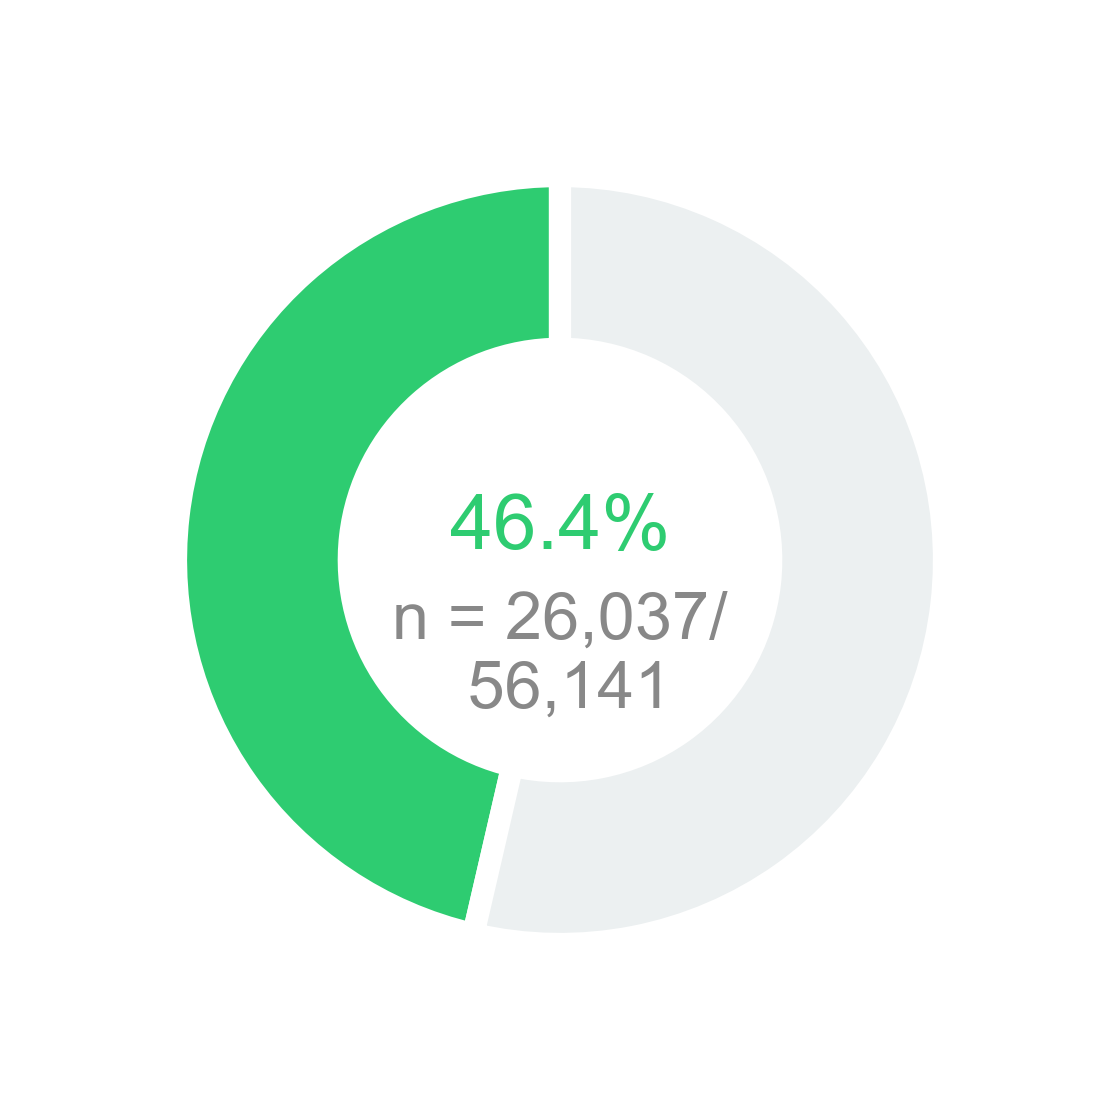

In [21]:
def plot_responsiveness_donut(df, threshold=0.05, figsize=(1.5, 1.5)):
    """
    Donut chart: % of neurons with test_frac_dev above threshold.
    """
    n_total = len(df)
    n_resp  = (df['test_frac_dev'] > threshold).sum()
    n_not   = n_total - n_resp
    pct     = n_resp / n_total * 100

    fig, ax = plt.subplots(figsize=figsize, dpi=800)
    wedges, _ = ax.pie(
        [n_resp, n_not],
        colors=['#2ECC71', '#ECF0F1'],
        startangle=90,
        wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    )
    # Centre text
    ax.text(0, 0.08, f'{pct:.1f}%',   ha='center', va='center',
            fontsize=7, color='#2ECC71')
#     ax.text(0, +1.2, f'frac dev > {threshold}', ha='center', va='center',
#             fontsize=6, color='#555555')
    ax.text(0, -0.25, f'n = {n_resp:,}/\n {n_total:,}', ha='center', va='center',
            fontsize=6, color='#888888')
    #ax.set_title('Neuron responsiveness', fontsize=10, pad=12)
    plt.tight_layout()
    #plt.show()
    return fig

figure = plot_responsiveness_donut(df_m1, threshold=0.1)
save_path='figures/perc_frac_dev_responsive.svg'
plt.savefig(save_path, bbox_inches='tight', facecolor='white', edgecolor='none')

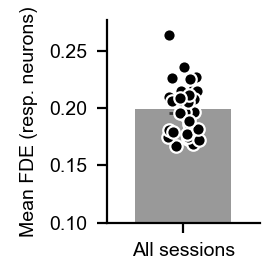

In [104]:
def plot_frac_dev_summary(df, resp_threshold=0.1, figsize=(1.5, 1.5)):
    """
    Single bar: mean of per-session median FDE across responsive neurons only.
    Error bar = SEM across sessions. Dots = individual session medians.
    """
    resp_df = df[df['test_frac_dev'] > resp_threshold].copy()

    sess_medians = (
        resp_df.groupby(['mouse_ID', 'date'])['test_frac_dev']
        .median()
        .reset_index()
        .rename(columns={'test_frac_dev': 'median_fd'})
    )

    grand_mean = sess_medians['median_fd'].mean()
    grand_sem  = sess_medians['median_fd'].sem()

    fig, ax = plt.subplots(figsize=figsize, dpi=200)

    ax.bar(0, grand_mean, yerr=grand_sem, width=0.5,
           color='grey', alpha=0.8,
           error_kw=dict(elinewidth=1.5, capsize=5, ecolor='#333333'),
           zorder=2)

    rng    = np.random.default_rng(seed=0)
    jitter = rng.uniform(-0.08, 0.08, size=len(sess_medians))
    for i, row in sess_medians.iterrows():
        ax.scatter(jitter[i], row['median_fd'],
                   color='black', s=20, zorder=4,
                   edgecolors='white', linewidths=0.8)

    ax.set_xticks([0])
    ax.set_xticklabels(['All sessions'], fontsize=7)
    ax.set_xlim(-0.4, 0.4)
    ax.set_ylim(bottom=resp_threshold)
    ax.set_ylabel('Mean FDE (resp. neurons)', fontsize=7)

    sns.despine()
    plt.tight_layout()
    return fig

figure = plot_frac_dev_summary(df_m1)
save_path='figures/perc_frac_dev_responsive_all_sessions.svg'
plt.savefig(save_path, bbox_inches='tight', facecolor='white', edgecolor='none')

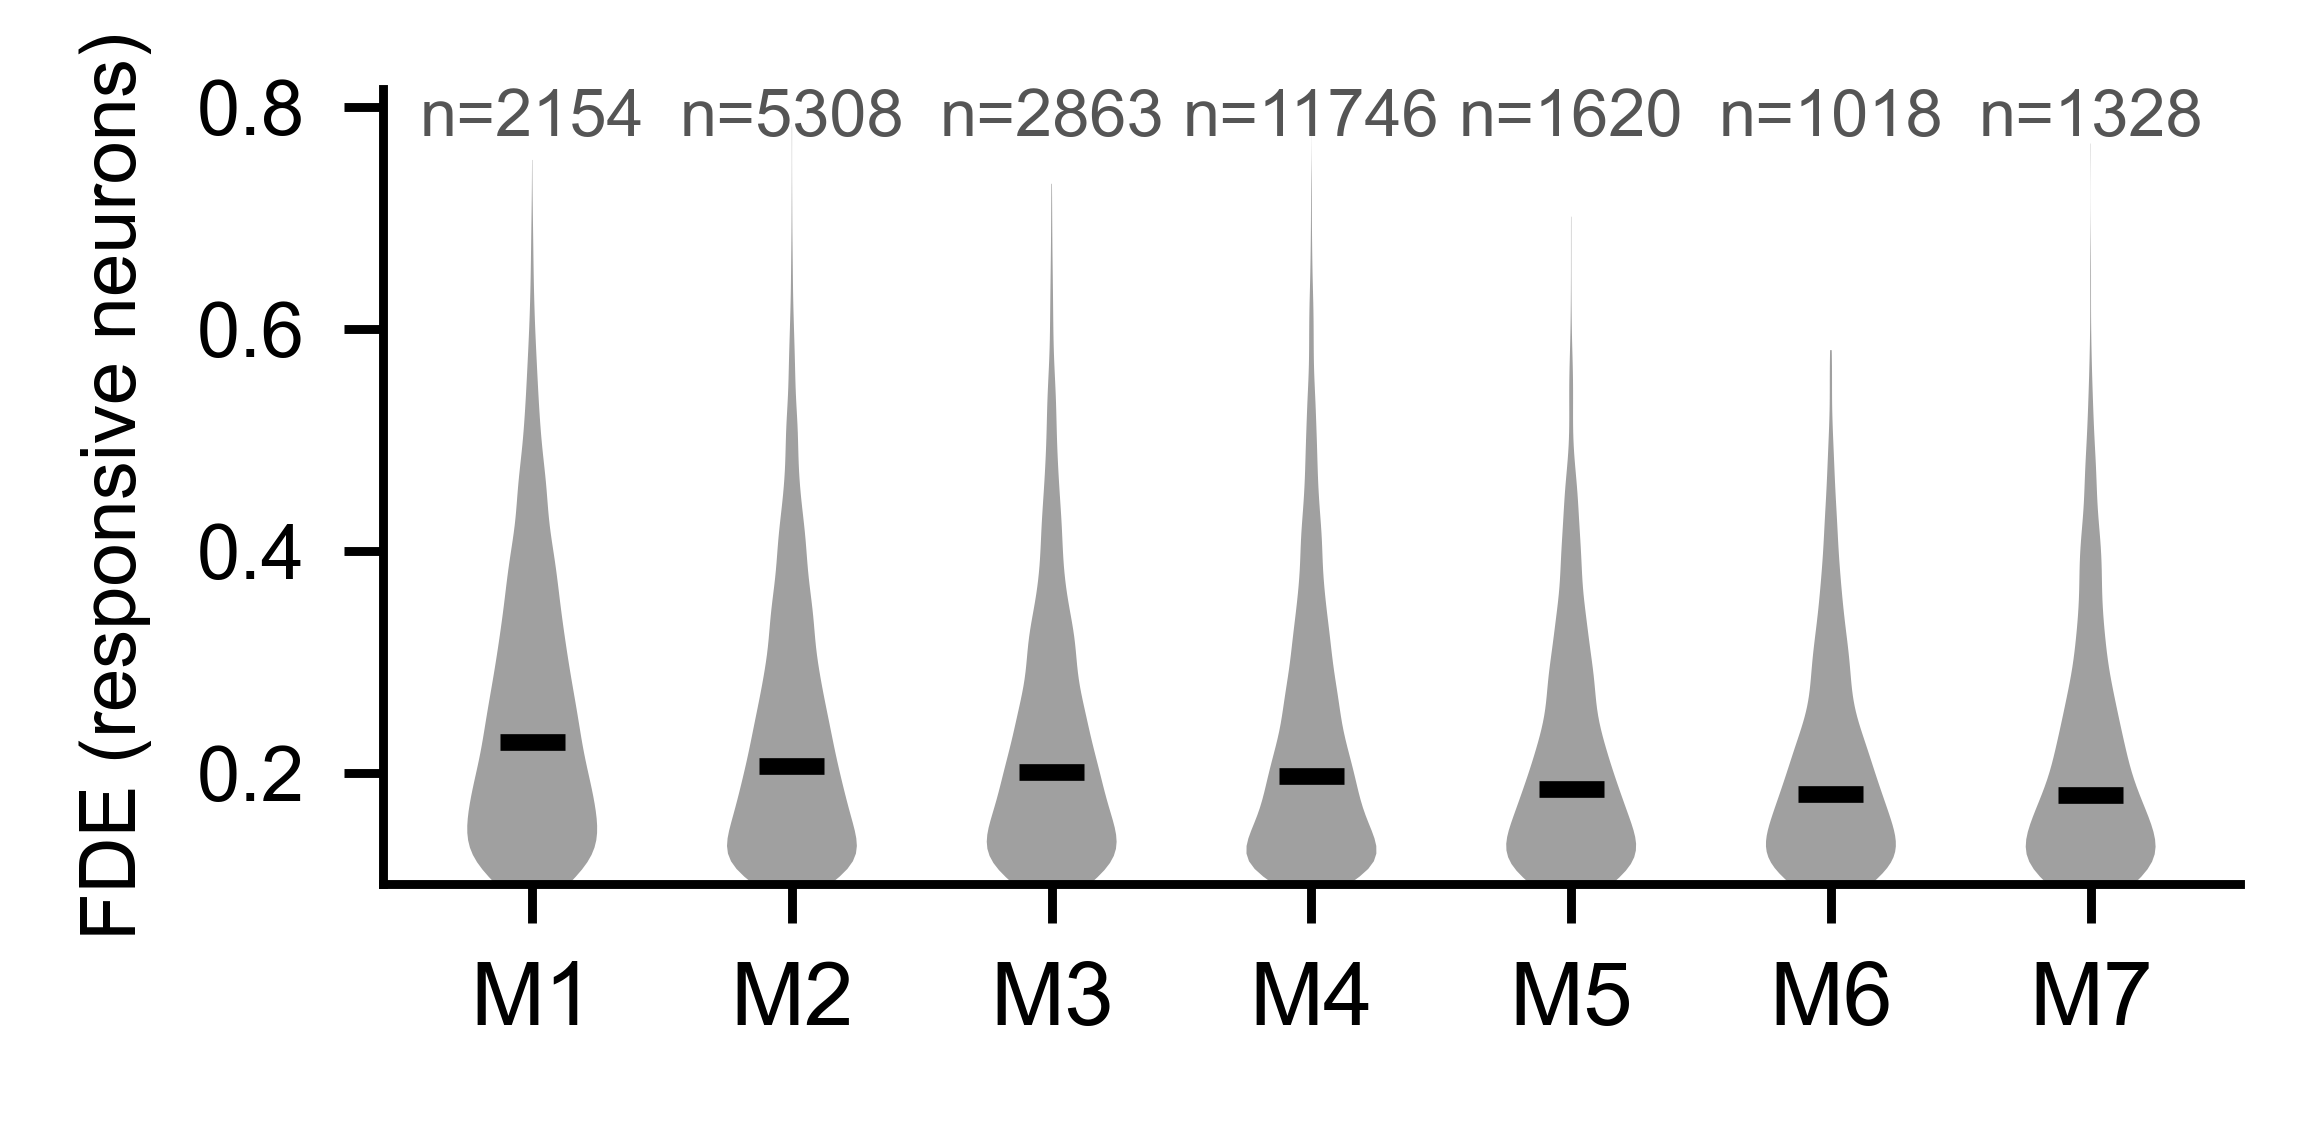

In [58]:
def plot_fde_per_mouse(df, resp_threshold=0.1, figsize=(3, 1.5)):
    """
    Violin plot: one violin per mouse showing distribution of FDE
    across responsive neurons. Mice labelled M1, M2, ... in
    descending order of median FDE.
    """
    resp_df = df[df['test_frac_dev'] > resp_threshold].copy()

    mouse_stats = (
        resp_df.groupby('mouse_ID')['test_frac_dev']
        .agg(median='median', n_neurons='count')
        .reset_index()
        .sort_values('median', ascending=False)
        .reset_index(drop=True)
    )
    mouse_stats['label'] = [f'M{i+1}' for i in range(len(mouse_stats))]

    # Build ordered list of neuron FDE arrays
    mouse_order  = mouse_stats['mouse_ID'].tolist()
    labels       = mouse_stats['label'].tolist()
    neuron_data  = [resp_df[resp_df['mouse_ID'] == m]['test_frac_dev'].values
                    for m in mouse_order]

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    parts = ax.violinplot(neuron_data,
                          positions=range(len(mouse_order)),
                          showmedians=True,
                          showextrema=False)

    # Style violins
    for pc in parts['bodies']:
        pc.set_facecolor('grey')
        pc.set_alpha(0.75)
    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(1.5)

    # Annotate n neurons below each violin
    for i, row in mouse_stats.iterrows():
        ax.text(i, 1, f'n={int(row["n_neurons"])}',
                ha='center', va='top', fontsize=6, color='#555555',
                transform=ax.get_xaxis_transform())

    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylabel('FDE (responsive neurons)', fontsize=7)
   #ax.set_xlabel('Mouse', fontsize=8)
    ax.set_ylim(bottom=resp_threshold)

    sns.despine()
    plt.tight_layout()
    #plt.show()
    return fig

fig_mouse = plot_fde_per_mouse(df_m1)
save_path='figures/perc_frac_dev_responsive_mouse.svg'
plt.savefig(save_path, bbox_inches='tight', facecolor='white', edgecolor='none')

Session: IS-2-1L / 2025-03-26
Neuron idx: 1090  |  FDE = 0.275
Window: frames 2500–3500  (166.7 s – 233.3 s)
Observed mean=0.061  Predicted mean=0.059


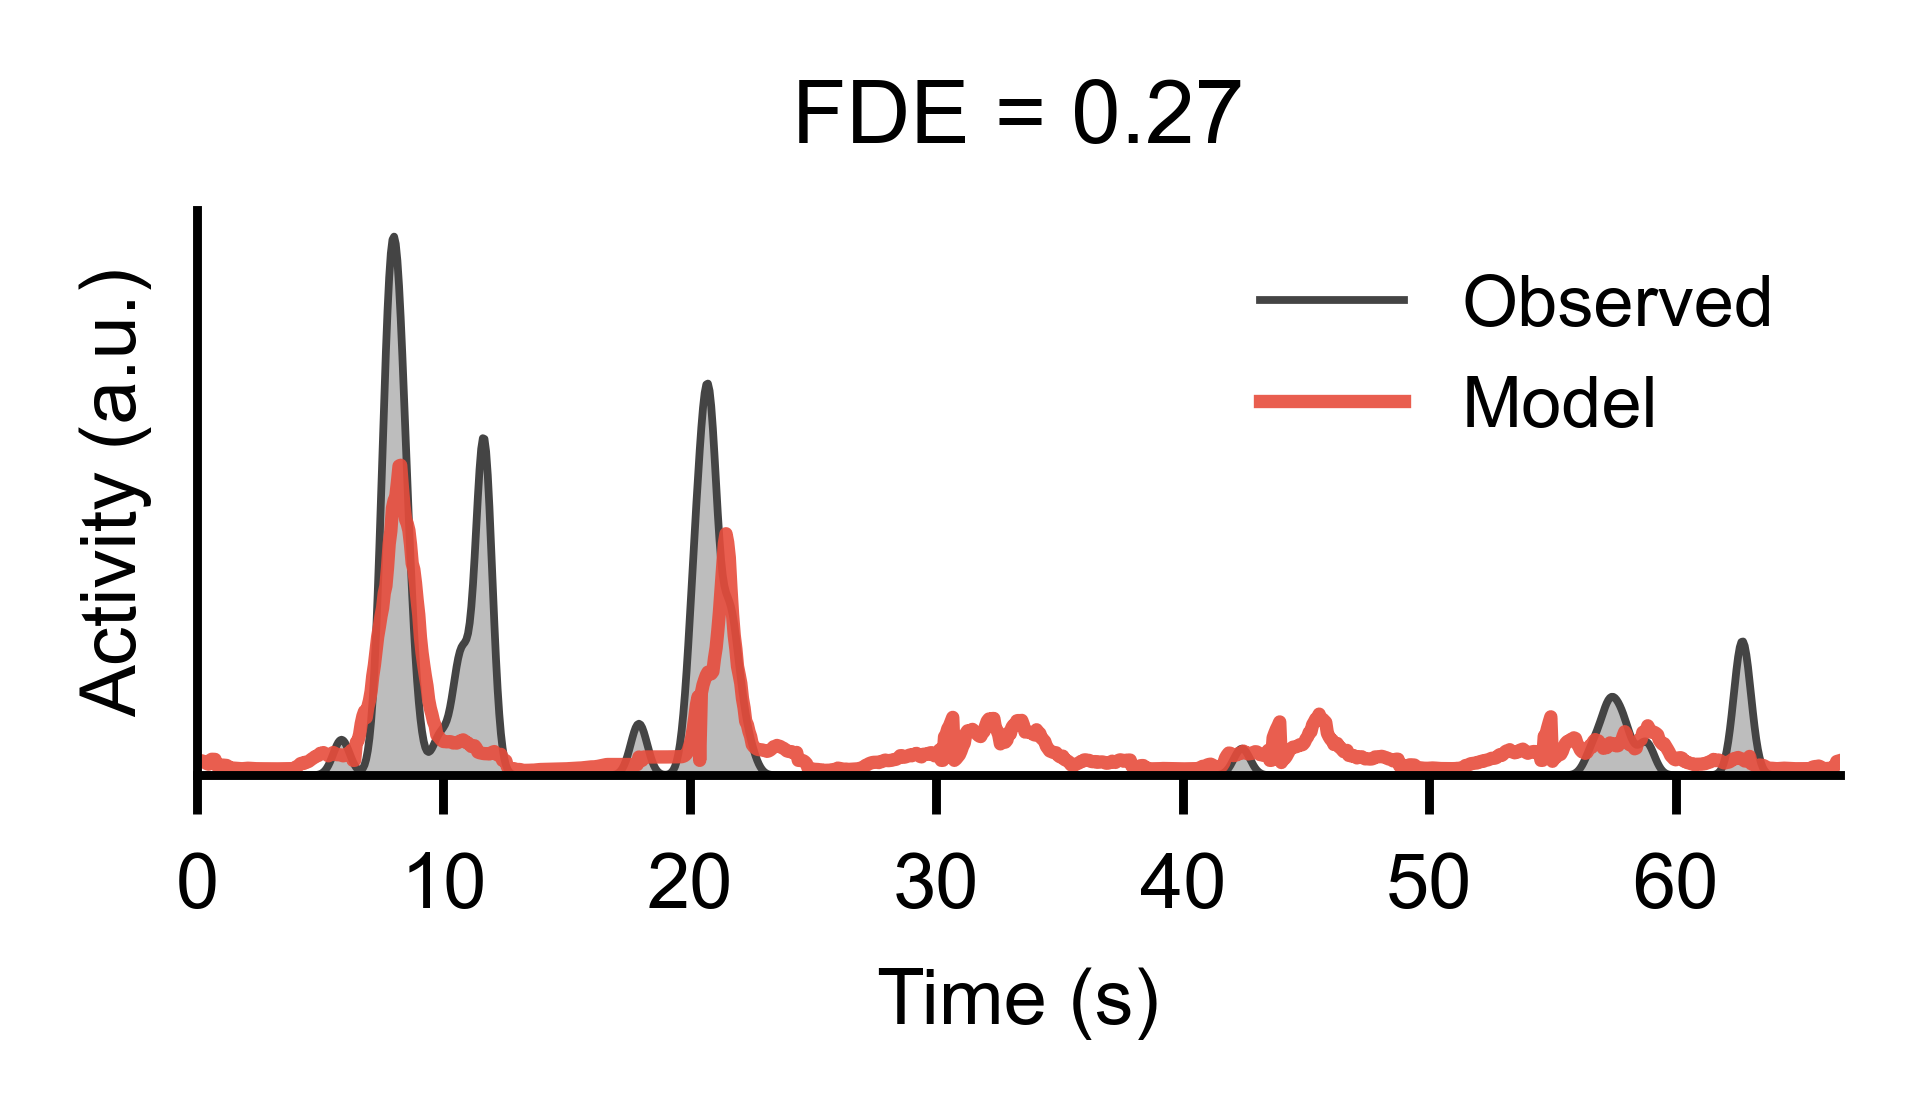

In [45]:
# ─────────────────────────────────────────────────────────────────────────────
# Example neuron figure: smoothed activity vs model prediction
# ─────────────────────────────────────────────────────────────────────────────
import pickle
from scipy.ndimage import gaussian_filter1d
from core.session_pipeline import BASE_DATA_PATH, Y_SCALE, Y_SMOOTH_SIGMA
from core.glm_class import make_prediction

FS       = 15.0
N_FRAMES = 1000

# ── Tweak this to scan for a good epoch ──────────────────────────────────────
T_START = 2500        # <-- change this frame offset to find a good window

# ── Step 1: pick session ──────────────────────────────────────────────────────
session_counts = (
    df_m1[df_m1['test_frac_dev'] > 0.25]
    .groupby(['mouse_ID', 'date'])
    .size()
    .sort_values(ascending=False)
)
ex_mouse, ex_date = session_counts.index[0]
print(f'Session: {ex_mouse} / {ex_date}')

ex_session = next(s for s in sessions_m1
                  if s['mouse_ID'] == ex_mouse and s['date'] == ex_date)
full_res = ex_session['full_res']

# ── Step 2: load X and Y (with same smoothing used during model fitting) ──────
stacked_path = f'{BASE_DATA_PATH}/{ex_mouse}/{ex_date}/glm_data_stacked.pkl'
with open(stacked_path, 'rb') as f:
    glm_data = pickle.load(f)

X = glm_data['X']                                    # (n_frames, n_features)
Y = glm_data['Y'] * Y_SCALE
if Y_SMOOTH_SIGMA > 0:
    Y = gaussian_filter1d(Y, sigma=Y_SMOOTH_SIGMA, axis=0)
    Y = np.clip(Y, 0.0, None)

# ── Step 3: pick neuron ───────────────────────────────────────────────────────
sess_df  = df_m1[(df_m1['mouse_ID'] == ex_mouse) & (df_m1['date'] == ex_date)]

# Options:
#   TARGET_FDE = None          → highest-FDE neuron in session
#   TARGET_FDE = (0.25, 0.50)  → neuron with FDE closest to midpoint of range
TARGET_FDE = (0.25, 0.3)           # <-- change this

if TARGET_FDE is None:
    best_row = sess_df.sort_values('test_frac_dev', ascending=False).iloc[0]
else:
    lo, hi   = TARGET_FDE
    mid      = (lo + hi) / 2
    in_range = sess_df[(sess_df['test_frac_dev'] >= lo) &
                       (sess_df['test_frac_dev'] <  hi)]
    if in_range.empty:
        raise ValueError(f'No neurons with FDE in [{lo}, {hi}) — try widening the range')
    best_row = in_range.iloc[(in_range['test_frac_dev'] - mid).abs().argsort()[:1].values[0]]

nidx = int(best_row['neuron_idx'])
fde  = float(best_row['test_frac_dev'])
print(f'Neuron idx: {nidx}  |  FDE = {fde:.3f}')

# ── Step 4: model prediction (full session) ───────────────────────────────────
W  = full_res['weights']
w0 = full_res['w0'].flatten()
Y_pred_full = make_prediction(X, W, w0, activation='exp')  # (n_frames, n_neurons)

# ── Step 5: slice the window ──────────────────────────────────────────────────
t_end  = T_START + N_FRAMES
t_axis = np.arange(N_FRAMES) / FS

y_obs  = Y[T_START:t_end, nidx]
y_pred = Y_pred_full[T_START:t_end, nidx]

print(f'Window: frames {T_START}–{t_end}  '
      f'({T_START/FS:.1f} s – {t_end/FS:.1f} s)')
print(f'Observed mean={y_obs.mean():.3f}  Predicted mean={y_pred.mean():.3f}')

# ── Step 6: figure ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(2.5, 1.5), dpi=800)

ax.fill_between(t_axis, y_obs, alpha=0.35, color='#444444', lw=0)
ax.plot(t_axis, y_obs,  color='#444444', lw=0.7, label='Observed')
ax.plot(t_axis, y_pred, color='#E74C3C', lw=1.2, alpha=0.9, label='Model')

ax.set_xlim(0, N_FRAMES / FS)
ax.set_ylim(bottom=0)
ax.set_yticks([])
ax.set_xlabel('Time (s)', fontsize=7)
ax.set_ylabel('Activity (a.u.)', fontsize=7)
ax.set_title(f'FDE = {fde:.2f}', fontsize=8)
ax.legend(fontsize=6.5, frameon=False, loc='upper right')

plt.tight_layout()

save_path='figures/example_neuron_3.svg'
plt.savefig(save_path, bbox_inches='tight', facecolor='white', edgecolor='none')

plt.show()

Friedman test (N=35 sessions):  χ²=16.63  p=2.45e-04
  Visual vs Audio: W=238.0  p=2.131e-01  p_bonf=6.392e-01
  Visual vs CG: W=156.0  p=8.235e-03  p_bonf=2.470e-02
  Audio vs CG: W=117.0  p=7.825e-04  p_bonf=2.348e-03


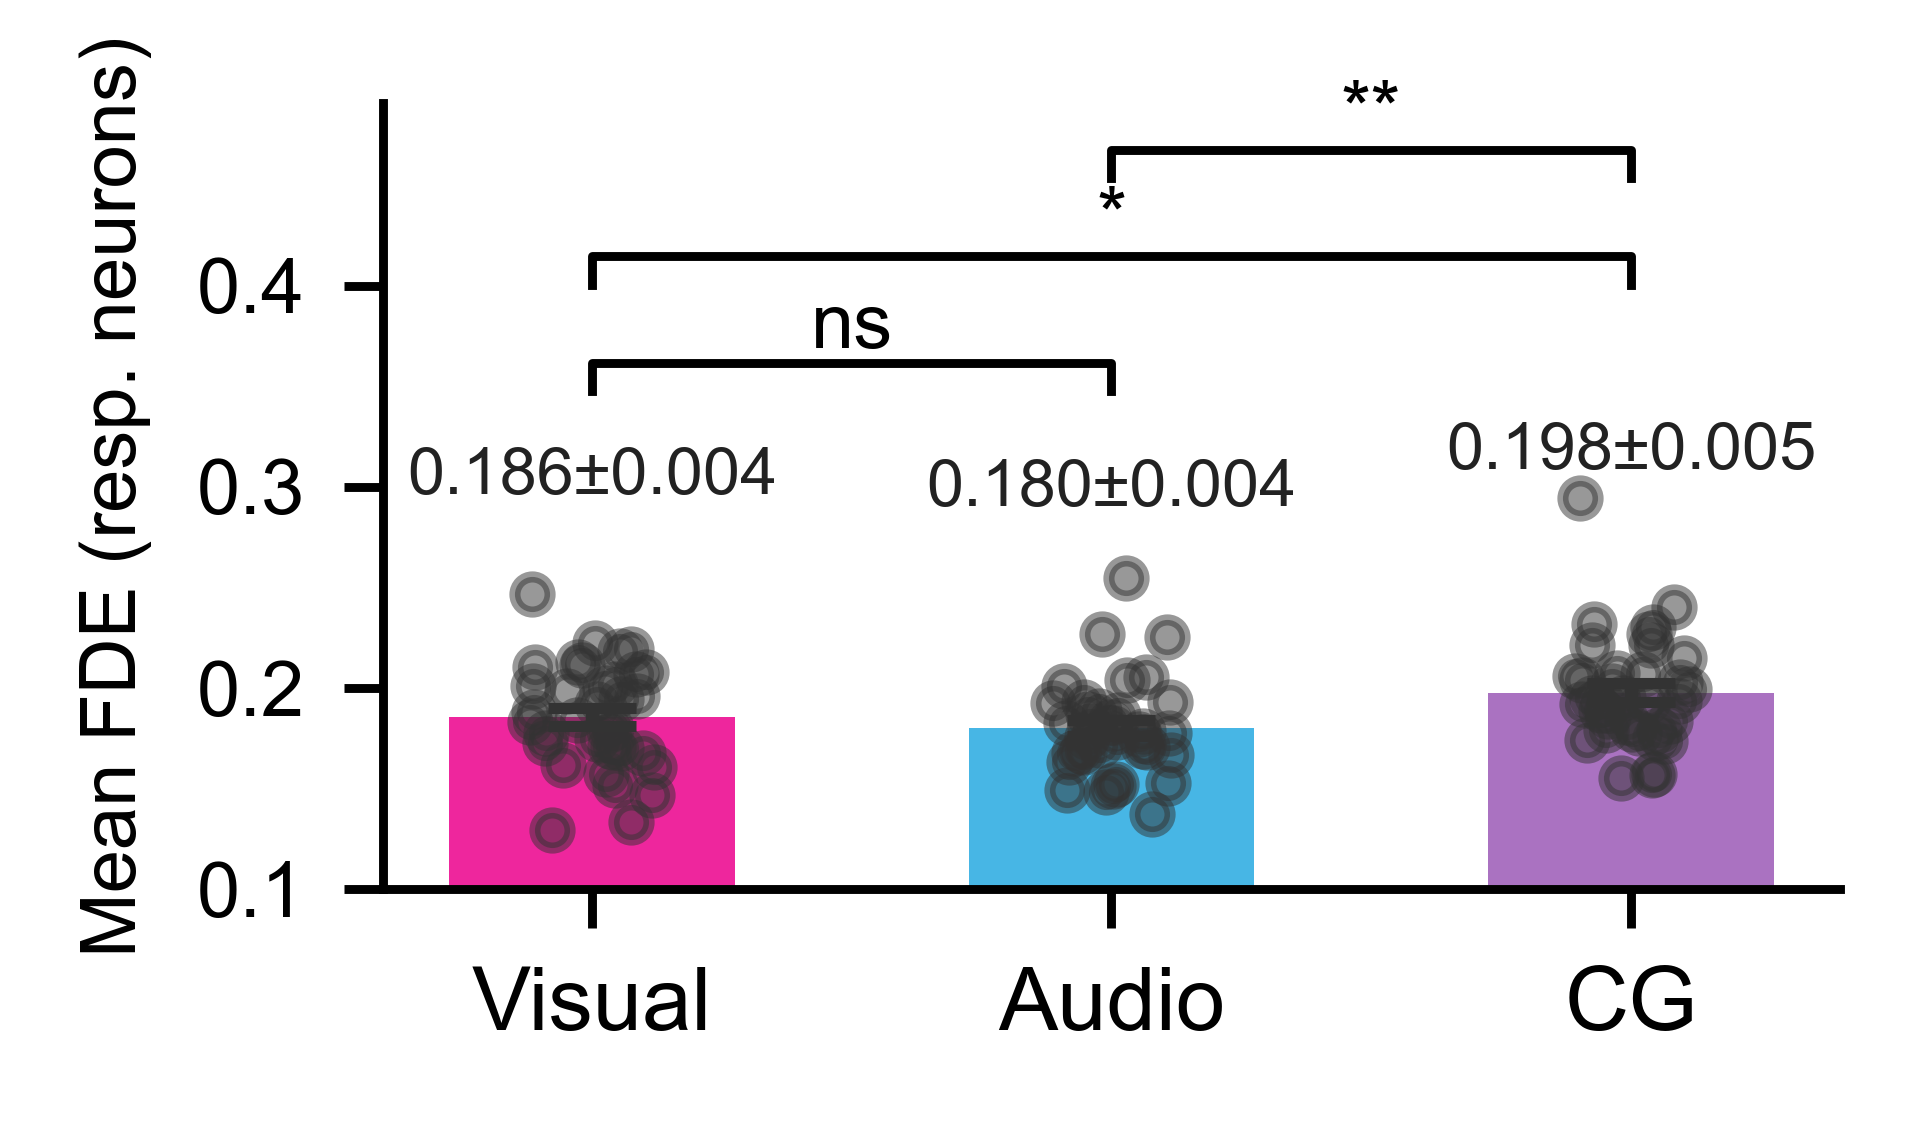

In [152]:
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations

def plot_fde_by_context(df, resp_threshold=0.1, figsize=(2.5, 1.5)):
    resp_df = df[df['test_frac_dev'] > resp_threshold].copy()

    ctx_cols   = ['frac_dev_visual', 'frac_dev_audio', 'frac_dev_cg']
    ctx_labels = ['Visual', 'Audio', 'CG']
    ctx_colors = [CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio'], CTX_COLORS_STR['cg']]

    sess_ctx = (
        resp_df.groupby(['mouse_ID', 'date'])[ctx_cols]
        .median()
        .reset_index()
    )
    n_sessions = len(sess_ctx)

    stat_data = [sess_ctx[c].values for c in ctx_cols]
    stat, p_friedman = friedmanchisquare(*stat_data)
    print(f'Friedman test (N={n_sessions} sessions):  χ²={stat:.2f}  p={p_friedman:.2e}')

    pairs   = list(combinations(range(3), 2))
    n_pairs = len(pairs)
    pairwise_results = []
    for i, j in pairs:
        w_stat, p_w = wilcoxon(stat_data[i], stat_data[j])
        p_corr = min(p_w * n_pairs, 1.0)
        pairwise_results.append((i, j, p_w, p_corr))
        print(f'  {ctx_labels[i]} vs {ctx_labels[j]}: '
              f'W={w_stat:.1f}  p={p_w:.3e}  p_bonf={p_corr:.3e}')

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    for i, (col, color) in enumerate(zip(ctx_cols, ctx_colors)):
        mean_val = sess_ctx[col].mean()
        sem_val  = sess_ctx[col].sem()

        ax.bar(i, mean_val, yerr=sem_val, width=0.55,
               color=color, alpha=0.85,
               error_kw=dict(elinewidth=1.2, capsize=4, ecolor='#333333'),
               zorder=2)

        rng    = np.random.default_rng(seed=i)
        jitter = rng.uniform(-0.12, 0.12, size=n_sessions)
        ax.scatter(i + jitter, sess_ctx[col].values,
                   color='#333333', s=10, alpha=0.5, zorder=3)

        # ── Mean ± SEM label above each bar ───────────────────────────────────
        ax.text(i, mean_val + sem_val + 0.1,
                f'{mean_val:.3f}±{sem_val:.3f}',
                ha='center', va='bottom', fontsize=6, color='#222222')

    # ── Significance brackets ─────────────────────────────────────────────────
    def sig_label(p):
        if p < 0.001: return '***'
        if p < 0.01:  return '**'
        if p < 0.05:  return '*'
        return 'ns'

    y_top     = max(sess_ctx[c].max() for c in ctx_cols)
    y_step    = y_top * 0.12          # increased from 0.07 → more breathing room
    bracket_y = y_top + y_step * 1.5  # start brackets higher above the dots

    for (i, j, p_raw, p_corr) in pairwise_results:
        bar_h = bracket_y + y_step * 0.4
        ax.plot([i, i, j, j], [bracket_y, bar_h, bar_h, bracket_y],
                lw=0.8, color='k')
        ax.text((i + j) / 2, bar_h ,
                sig_label(p_corr), ha='center', va='bottom', fontsize=7)
        bracket_y += y_step * 1.5     # increased from 1.1 → wider gap between brackets

    ax.set_xticks(range(3))
    ax.set_xticklabels(ctx_labels, fontsize=8)
    ax.set_ylabel('Mean FDE (resp. neurons)', fontsize=7)
    ax.set_ylim(bottom=resp_threshold)

    sns.despine()
    plt.tight_layout()
    #plt.show()
    return fig

fig_ctx = plot_fde_by_context(df_m1)
save_path='figures/mean_fde_by_context.svg'
plt.savefig(save_path, bbox_inches='tight', facecolor='white', edgecolor='none')

Session     : KO-5-1L / 2026-03-24
Neuron      : 1323
FDE overall : 0.330
FDE Visual  : 0.179
FDE Audio   : 0.173
FDE CG      : 0.574
CG advantage: 0.396
N candidates: 3690

  [Coupling] PCA on Y (1383 neurons):
    PC1: 2.8% variance explained
    PC2: 2.0% variance explained
    PC3: 1.8% variance explained
    PC4: 1.6% variance explained
    PC5: 1.5% variance explained
    Total: 9.7%
  [Coupling] Added 5 PCs × 4 lag bases = 20 columns  (X: 150 → 170)

X shape after coupling: (63211, 170)
W shape: (170, 1383)
  Visual  auto    start=23783  r=-inf
  Audio   auto    start=196  r=-inf
  CG      auto    start=12583  r=-inf


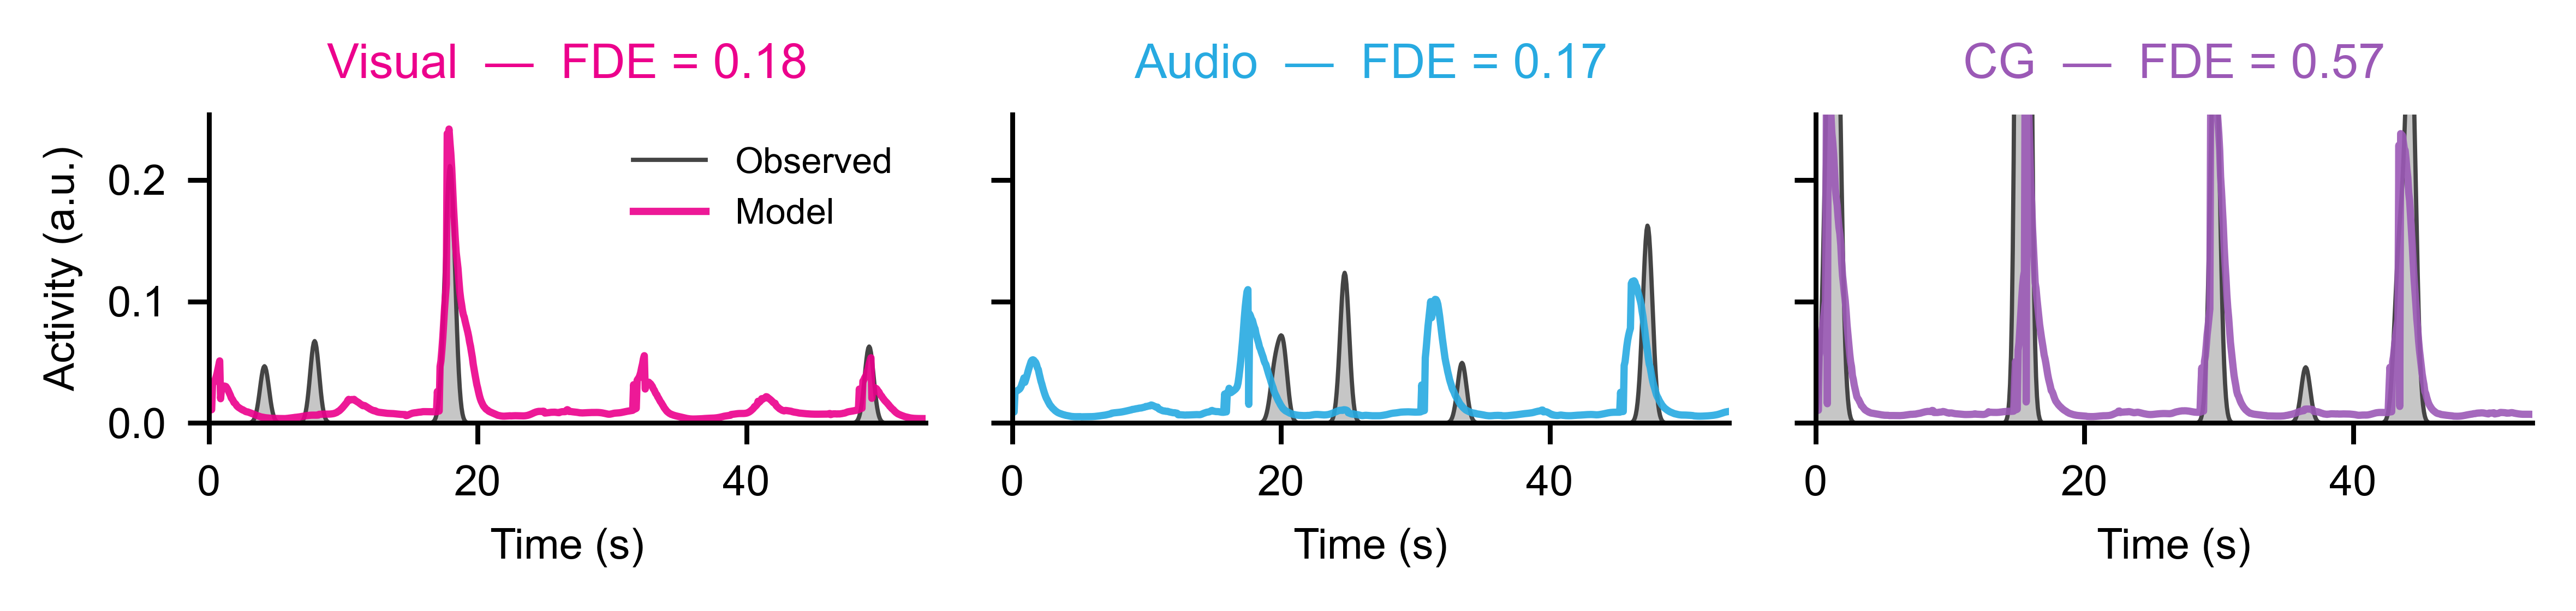

In [122]:
# ─────────────────────────────────────────────────────────────────────────────
# CG-enhanced example neuron: observed vs model, per context
# ─────────────────────────────────────────────────────────────────────────────
import pickle
from scipy.ndimage import gaussian_filter1d
from scipy.stats import pearsonr
from core.session_pipeline import BASE_DATA_PATH, Y_SCALE, Y_SMOOTH_SIGMA
from core.glm_class import make_prediction

CTX_MAP   = {0: 'CG', 1: 'Visual', 2: 'Audio'}
CTX_ORDER = [1, 2, 0]       # Visual | Audio | CG
WINDOW    = 800
STRIDE    = 20
FS        = 15.0

# ── Manual window overrides (set to None to auto-search) ─────────────────────
T_STARTS = {
    1: None,    # Visual
    2: None,    # Audio
    0: None,    # CG
}

# ── Step 1: find best CG-advantage neuron ────────────────────────────────────
MIN_UNI_FDE = 0.15
MIN_CG_FDE  = 0.35

cg_df = df_m1[df_m1['test_frac_dev'] > 0.2].copy()
cg_df = cg_df[
    (cg_df['frac_dev_visual'] >= MIN_UNI_FDE) &
    (cg_df['frac_dev_audio']  >= MIN_UNI_FDE) &
    (cg_df['frac_dev_cg']     >= MIN_CG_FDE)
].copy()

if cg_df.empty:
    raise ValueError('No neurons meet criteria — try lowering MIN_UNI_FDE or MIN_CG_FDE')

cg_df['cg_advantage'] = cg_df['frac_dev_cg'] - np.maximum(
    cg_df['frac_dev_visual'], cg_df['frac_dev_audio']
)
best = cg_df.sort_values('cg_advantage', ascending=False).iloc[0]

ex_mouse = best['mouse_ID']
ex_date  = best['date']
nidx     = int(best['neuron_idx'])

print(f'Session     : {ex_mouse} / {ex_date}')
print(f'Neuron      : {nidx}')
print(f'FDE overall : {best["test_frac_dev"]:.3f}')
print(f'FDE Visual  : {best["frac_dev_visual"]:.3f}')
print(f'FDE Audio   : {best["frac_dev_audio"]:.3f}')
print(f'FDE CG      : {best["frac_dev_cg"]:.3f}')
print(f'CG advantage: {best["cg_advantage"]:.3f}')
print(f'N candidates: {len(cg_df)}')

# ── Step 2: load data ─────────────────────────────────────────────────────────
from core.session_pipeline import add_coupling_predictor

ex_session = next(s for s in sessions_m1
                  if s['mouse_ID'] == ex_mouse and s['date'] == ex_date)
full_res = ex_session['full_res']

stacked_path = f'{BASE_DATA_PATH}/{ex_mouse}/{ex_date}/glm_data_stacked.pkl'
with open(stacked_path, 'rb') as f:
    glm_data = pickle.load(f)

X        = glm_data['X']
Y        = glm_data['Y'] * Y_SCALE
if Y_SMOOTH_SIGMA > 0:
    Y = gaussian_filter1d(Y, sigma=Y_SMOOTH_SIGMA, axis=0)
    Y = np.clip(Y, 0.0, None)

# Re-add coupling predictors to match the feature space the model was fit on
X, _, _ = add_coupling_predictor(
    X, Y, glm_data['predictor_info'],
    n_pcs=5, n_lag_bases=4, lag_frames=8
)
print(f'X shape after coupling: {X.shape}')   # should be (n_frames, 170)

metadata = glm_data['metadata']

W  = full_res['weights']
w0 = full_res['w0'].flatten()
print(f'W shape: {W.shape}')                  # should be (170, n_neurons)

Y_pred_full = make_prediction(X, W, w0, activation='exp')

test_mask = full_res['combined_test_mask']
# ── Step 3: auto-search helper ────────────────────────────────────────────────
def find_best_ctx_window(y_obs, y_pred, ctx_frames, window=WINDOW, stride=STRIDE,
                         min_mean=0.1):
    idx        = np.sort(ctx_frames)
    n          = len(idx)
    best_r     = -np.inf
    best_start = idx[0]
    for k in range(0, n - window, stride):
        win_idx = idx[k : k + window]
        if win_idx[-1] - win_idx[0] > window * 3:
            continue
        y_o = y_obs[win_idx]
        y_p = y_pred[win_idx]
        if y_o.mean() < min_mean or y_o.std() < 1e-6 or y_p.std() < 1e-6:
            continue
        r, _ = pearsonr(y_o, y_p)
        if r > best_r:
            best_r     = r
            best_start = win_idx[0]
    return best_start, best_r

# ── Step 4: resolve windows ───────────────────────────────────────────────────
ctx_windows = {}
for ctx_id in CTX_ORDER:
    if T_STARTS[ctx_id] is not None:
        ctx_windows[ctx_id] = (T_STARTS[ctx_id], None)
        print(f'  {CTX_MAP[ctx_id]:6s}  manual  start={T_STARTS[ctx_id]}')
    else:
        ctx_frames = np.where(test_mask & (metadata['context'] == ctx_id))[0]
        t_start, r = find_best_ctx_window(
            Y[:, nidx], Y_pred_full[:, nidx], ctx_frames
        )
        ctx_windows[ctx_id] = (t_start, r)
        print(f'  {CTX_MAP[ctx_id]:6s}  auto    start={t_start}  r={r:.3f}')

# ── Step 5: figure ────────────────────────────────────────────────────────────
fde_per_ctx = {
    0: best['frac_dev_cg'],
    1: best['frac_dev_visual'],
    2: best['frac_dev_audio'],
}
ctx_colors_line = {
    0: CTX_COLORS_STR['cg'],
    1: CTX_COLORS_STR['visual'],
    2: CTX_COLORS_STR['audio'],
}

t_axis = np.arange(WINDOW) / FS
fig, axes = plt.subplots(1, 3, figsize=(6, 1.5), dpi=800, sharey=True)

for col_i, ctx_id in enumerate(CTX_ORDER):
    ax      = axes[col_i]
    t_start = ctx_windows[ctx_id][0]
    color   = ctx_colors_line[ctx_id]
    fde     = fde_per_ctx[ctx_id]

    y_obs  = Y[t_start : t_start + WINDOW, nidx]
    y_pred = Y_pred_full[t_start : t_start + WINDOW, nidx]

    ax.fill_between(t_axis, y_obs, alpha=0.3, color='#444444', lw=0)
    ax.plot(t_axis, y_obs,  color='#444444', lw=0.7, label='Observed')
    ax.plot(t_axis, y_pred, color=color,     lw=1.2, alpha=0.9, label='Model')

    ax.set_xlim(0, WINDOW / FS)
    ax.set_ylim(bottom=0)
    ax.set_xlabel('Time (s)', fontsize=7)
    ax.set_title(f'{CTX_MAP[ctx_id]}  —  FDE = {fde:.2f}',
                 fontsize=8, color=color)

    if col_i == 0:
        ax.set_ylabel('Activity (a.u.)', fontsize=7)
        ax.legend(fontsize=6, frameon=False, loc='upper right')

plt.tight_layout()
save_path='figures/example_CG_enhanced_neuron.svg'
plt.savefig(save_path, bbox_inches='tight', facecolor='white', edgecolor='none')

Context preference counts:
ctx_pref
CG        9838
Audio     8161
Visual    8038
Name: count, dtype: int64

Context exclusivity counts:
ctx_exclusivity
All three       13403
CG+Visual        3838
Audio+CG         2662
Audio+Visual     2331
Audio only       1741
CG only          1066
Visual only       870
None              126
Name: count, dtype: int64

CG-enhanced (cg_advantage > 0): 9838 / 26037 (37.8%)


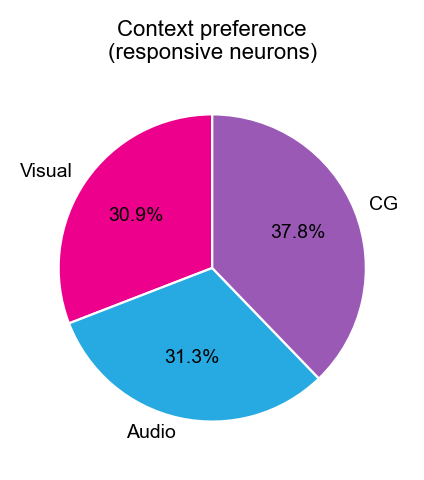

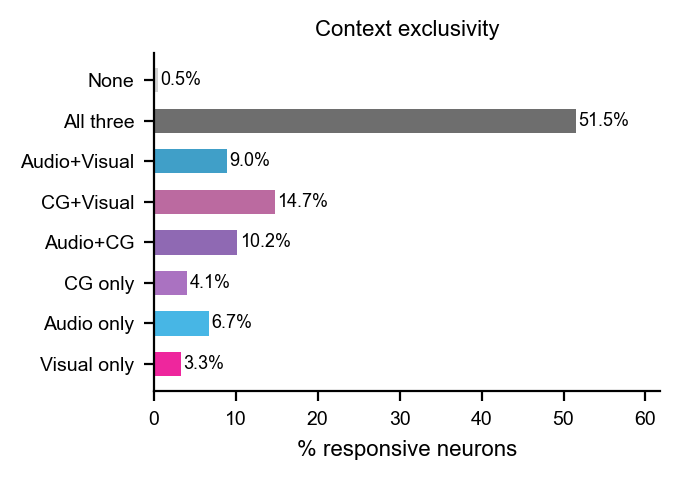

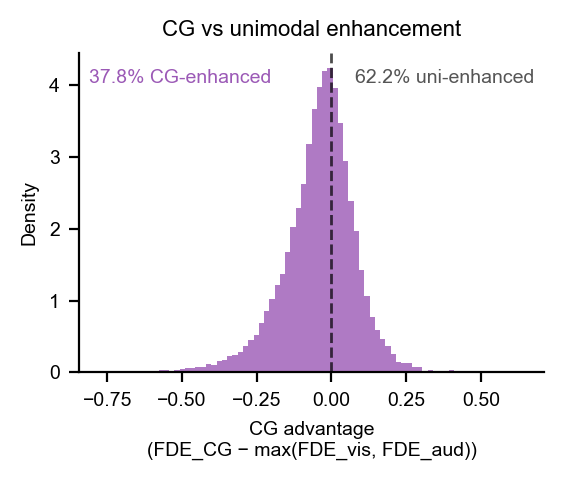

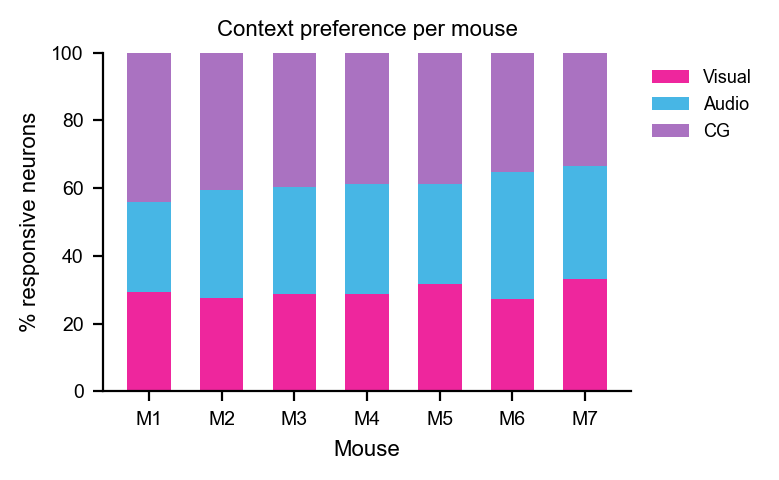

In [123]:
# ─────────────────────────────────────────────────────────────────────────────
# Context sensitivity analysis — Model 1
# ─────────────────────────────────────────────────────────────────────────────
CTX_THRESH   = 0.1    # per-context responsiveness threshold
RESP_THRESH  = 0.1    # overall responsiveness threshold

resp_df = df_m1[df_m1['test_frac_dev'] > RESP_THRESH].copy()

# Per-context responsiveness flags
resp_df['resp_visual'] = resp_df['frac_dev_visual'] > CTX_THRESH
resp_df['resp_audio']  = resp_df['frac_dev_audio']  > CTX_THRESH
resp_df['resp_cg']     = resp_df['frac_dev_cg']     > CTX_THRESH

# Context preference (best context)
resp_df['ctx_pref'] = resp_df[['frac_dev_visual','frac_dev_audio','frac_dev_cg']].idxmax(axis=1).map({
    'frac_dev_visual': 'Visual',
    'frac_dev_audio':  'Audio',
    'frac_dev_cg':     'CG',
})

# CG advantage
resp_df['cg_advantage'] = resp_df['frac_dev_cg'] - np.maximum(
    resp_df['frac_dev_visual'], resp_df['frac_dev_audio']
)

# Context exclusivity label
def ctx_label(row):
    flags = {'Visual': row['resp_visual'],
             'Audio':  row['resp_audio'],
             'CG':     row['resp_cg']}
    active = [k for k, v in flags.items() if v]
    n = len(active)
    if n == 0:  return 'None'
    if n == 3:  return 'All three'
    if n == 2:  return '+'.join(sorted(active))
    return active[0] + ' only'

resp_df['ctx_exclusivity'] = resp_df.apply(ctx_label, axis=1)

print('Context preference counts:')
print(resp_df['ctx_pref'].value_counts())
print('\nContext exclusivity counts:')
print(resp_df['ctx_exclusivity'].value_counts())
print(f'\nCG-enhanced (cg_advantage > 0): '
      f'{(resp_df["cg_advantage"] > 0).sum()} / {len(resp_df)} '
      f'({(resp_df["cg_advantage"] > 0).mean()*100:.1f}%)')


# ── Panel G: context preference pie ──────────────────────────────────────────
def plot_ctx_preference(df, figsize=(2.5, 2.5)):
    counts = df['ctx_pref'].value_counts()
    order  = ['Visual', 'Audio', 'CG']
    vals   = [counts.get(c, 0) for c in order]
    colors = [CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio'], CTX_COLORS_STR['cg']]

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    wedges, texts, autotexts = ax.pie(
        vals, labels=order, colors=colors,
        autopct='%1.1f%%', startangle=90,
        textprops={'fontsize': 7},
        wedgeprops={'linewidth': 0.8, 'edgecolor': 'white'}
    )
    for at in autotexts:
        at.set_fontsize(7)
    ax.set_title('Context preference\n(responsive neurons)', fontsize=8)
    plt.tight_layout()
    plt.show()
    return fig

fig_G = plot_ctx_preference(resp_df)


# ── Panel H: context exclusivity stacked bar ──────────────────────────────────
def plot_ctx_exclusivity(df, figsize=(3.5, 2.5)):
    order  = ['Visual only', 'Audio only', 'CG only',
              'Audio+CG', 'CG+Visual', 'Audio+Visual',
              'All three', 'None']
    colors_map = {
        'Visual only':   CTX_COLORS_STR['visual'],
        'Audio only':    CTX_COLORS_STR['audio'],
        'CG only':       CTX_COLORS_STR['cg'],
        'Audio+CG':      '#7B4FA6',
        'CG+Visual':     '#B05090',
        'Audio+Visual':  '#1E8EBF',
        'All three':     '#555555',
        'None':          '#CCCCCC',
    }

    counts = df['ctx_exclusivity'].value_counts()
    total  = len(df)

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    present = [o for o in order if o in counts.index]
    vals    = [counts[o] / total * 100 for o in present]
    clrs    = [colors_map[o] for o in present]

    bars = ax.barh(present, vals, color=clrs, alpha=0.85, height=0.6)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                f'{v:.1f}%', va='center', fontsize=6.5)

    ax.set_xlabel('% responsive neurons', fontsize=8)
    ax.set_title('Context exclusivity', fontsize=8)
    ax.set_xlim(0, max(vals) * 1.2)
    sns.despine()
    plt.tight_layout()
    plt.show()
    return fig

fig_H = plot_ctx_exclusivity(resp_df)


# ── Panel I: CG advantage distribution ───────────────────────────────────────
def plot_cg_advantage(df, figsize=(3, 2.5)):
    adv = df['cg_advantage'].values
    pct_enhanced = (adv > 0).mean() * 100

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    ax.hist(adv, bins=80, color=CTX_COLORS_STR['cg'], alpha=0.8,
            edgecolor='none', density=True)
    ax.axvline(0, color='k', lw=1.0, ls='--', alpha=0.7)

    ymax = ax.get_ylim()[1]
    ax.text(0.02, 0.95, f'{pct_enhanced:.1f}% CG-enhanced',
            transform=ax.transAxes, va='top', fontsize=7,
            color=CTX_COLORS_STR['cg'])
    ax.text(0.98, 0.95, f'{100-pct_enhanced:.1f}% uni-enhanced',
            transform=ax.transAxes, va='top', ha='right', fontsize=7,
            color='#555555')

    ax.set_xlabel('CG advantage\n(FDE_CG − max(FDE_vis, FDE_aud))', fontsize=7)
    ax.set_ylabel('Density', fontsize=7)
    ax.set_title('CG vs unimodal enhancement', fontsize=8)
    sns.despine()
    plt.tight_layout()
    plt.show()
    return fig

fig_I = plot_cg_advantage(resp_df)


# ── Panel J: context preference per mouse ─────────────────────────────────────
def plot_ctx_pref_per_mouse(df, figsize=(4, 2.5)):
    ctx_order  = ['Visual', 'Audio', 'CG']
    ctx_colors = [CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio'],
                  CTX_COLORS_STR['cg']]

    # Per-mouse proportions
    mouse_pref = (
        df.groupby('mouse_ID')['ctx_pref']
        .value_counts(normalize=True)
        .unstack(fill_value=0)
        [ctx_order]
        * 100
    )
    # Sort mice by descending CG proportion
    mouse_pref = mouse_pref.sort_values('CG', ascending=False)
    mouse_pref.index = [f'M{i+1}' for i in range(len(mouse_pref))]

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    bottom = np.zeros(len(mouse_pref))
    for ctx, color in zip(ctx_order, ctx_colors):
        vals = mouse_pref[ctx].values
        ax.bar(mouse_pref.index, vals, bottom=bottom,
               color=color, alpha=0.85, width=0.6, label=ctx)
        bottom += vals

    ax.set_ylabel('% responsive neurons', fontsize=8)
    ax.set_xlabel('Mouse', fontsize=8)
    ax.set_ylim(0, 100)
    ax.legend(fontsize=6.5, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
    ax.set_title('Context preference per mouse', fontsize=8)
    sns.despine()
    plt.tight_layout()
    plt.show()
    return fig

fig_J = plot_ctx_pref_per_mouse(resp_df)

In [124]:
def build_lesion_dataframe(df):
    """
    Extract a focused DataFrame with just the lesion delta columns per neuron.

    Columns
    -------
    Identity (from index + columns):
        neuron_uid  (index)
        mouse_ID, date, neuron_idx

    Model quality:
        test_frac_dev       — full model performance
        is_responsive

    Per-group deltas:
        delta_fd_{group}    — unique frac_dev contribution (full − lesion)
        delta_r2_{group}    — unique R² contribution

    Classification:
        dominant_group, dominant_delta
        runner_up_group, runner_up_delta
        mixedness, neuron_class
    """
    id_cols    = ['mouse_ID', 'date', 'neuron_idx',
                  'test_frac_dev', 'is_responsive']
    delta_fd   = [c for c in df.columns if c.startswith('delta_fd_')]
    delta_r2   = [c for c in df.columns if c.startswith('delta_r2_')]
    class_cols = ['dominant_group', 'dominant_delta',
                  'runner_up_group', 'runner_up_delta',
                  'mixedness', 'neuron_class']

    keep = id_cols + delta_fd + delta_r2 + class_cols
    keep = [c for c in keep if c in df.columns]   # guard against missing cols

    df_lesion = df[keep].copy()

    print(f'Lesion DataFrame: {df_lesion.shape[0]:,} neurons × {df_lesion.shape[1]} columns')
    print(f'  Groups: {[c.replace("delta_fd_","") for c in delta_fd]}')
    return df_lesion


df_lesion = build_lesion_dataframe(df_m1)
df_lesion.head()

Lesion DataFrame: 56,141 neurons × 39 columns
  Groups: ['position_only', 'audio_context', 'audio_stim', 'visual_context', 'visual_stim', 'velocity', 'choice_spatial', 'turn_onset', 'outcome', 'network_pc1', 'network_pc2', 'network_pc3', 'network_pc4', 'network_pc5']


,mouse_ID,date,neuron_idx,test_frac_dev,is_responsive,delta_fd_position_only,delta_fd_audio_context,delta_fd_audio_stim,delta_fd_visual_context,delta_fd_visual_stim,...,delta_r2_network_pc2,delta_r2_network_pc3,delta_r2_network_pc4,delta_r2_network_pc5,dominant_group,dominant_delta,runner_up_group,runner_up_delta,mixedness,neuron_class
neuron_uid,,,,,,,,,,,,,,,,,,,,,
IS-2-1L_2025-03-10_n0,IS-2-1L,2025-03-10,0,0.177405,True,0.002257,0.002787,0.002955,0.001456,0.002986,...,NaN,NaN,NaN,NaN,velocity,0.035986,network_pc2,NaN,NaN,velocity
IS-2-1L_2025-03-10_n1,IS-2-1L,2025-03-10,1,0.022238,False,0.000164,-0.000144,0.001720,0.001554,-0.000153,...,NaN,NaN,NaN,NaN,outcome,0.008243,network_pc2,NaN,NaN,unclassified
IS-2-1L_2025-03-10_n2,IS-2-1L,2025-03-10,2,0.042549,False,-0.001386,0.006036,-0.000906,-0.000340,0.005980,...,NaN,NaN,NaN,NaN,velocity,0.025312,network_pc2,NaN,NaN,unclassified
IS-2-1L_2025-03-10_n3,IS-2-1L,2025-03-10,3,0.192938,True,0.001456,0.000102,0.000865,-0.001949,0.000601,...,NaN,NaN,NaN,NaN,velocity,0.077809,network_pc2,NaN,NaN,velocity
IS-2-1L_2025-03-10_n4,IS-2-1L,2025-03-10,4,0.045501,False,0.004926,0.000465,0.001684,0.001221,0.001426,...,NaN,NaN,NaN,NaN,choice_spatial,0.006557,network_pc2,NaN,NaN,unclassified


In [126]:
# ── Neurons × groups delta matrix (responsive neurons only, clipped at 0) ─────
# Uses df_m1 and M1_GROUPS from this notebook's setup

delta_fd_cols = [f'delta_fd_{g}' for g in M1_GROUPS
                 if f'delta_fd_{g}' in df_m1.columns]

df_delta_resp = (
    df_m1
    .loc[df_m1['is_responsive'], delta_fd_cols]
    .clip(lower=0)                                          # negative delta → 0
    .rename(columns=lambda c: c.replace('delta_fd_', ''))  # clean column names
)

# Numpy matrix for numerical work
X_delta = df_delta_resp.to_numpy()   # shape: (n_responsive_neurons, n_groups)

print(f'Matrix shape: {X_delta.shape}  '
      f'— {X_delta.shape[0]:,} neurons × {X_delta.shape[1]} groups')
print(f'Groups: {df_delta_resp.columns.tolist()}')

# Sanity check — how many neurons have at least one nonzero delta
n_nonzero = (X_delta.sum(axis=1) > 0).sum()
print(f'Neurons with ≥1 nonzero delta: {n_nonzero:,} '
      f'({n_nonzero/X_delta.shape[0]*100:.1f}%)')

df_delta_resp.head()

Matrix shape: (26037, 9)  — 26,037 neurons × 9 groups
Groups: ['position_only', 'audio_context', 'audio_stim', 'visual_context', 'visual_stim', 'velocity', 'choice_spatial', 'turn_onset', 'outcome']
Neurons with ≥1 nonzero delta: 25,252 (97.0%)


,position_only,audio_context,audio_stim,visual_context,visual_stim,velocity,choice_spatial,turn_onset,outcome
neuron_uid,,,,,,,,,
IS-2-1L_2025-03-10_n0,0.002257,0.002787,0.002955,0.001456,0.002986,0.035986,0.007010,0.002798,0.022883
IS-2-1L_2025-03-10_n3,0.001456,0.000102,0.000865,0.000000,0.000601,0.077809,0.011299,0.012316,0.019272
IS-2-1L_2025-03-10_n6,0.002831,0.003179,0.003597,0.001182,0.003471,0.010696,0.016974,0.020644,0.033449
IS-2-1L_2025-03-10_n9,0.000939,0.002854,0.001130,0.000000,0.001786,0.122985,0.024602,0.000290,0.010037
IS-2-1L_2025-03-10_n10,0.000524,0.002076,0.002422,0.000838,0.000000,0.069615,0.006831,0.007265,0.010783


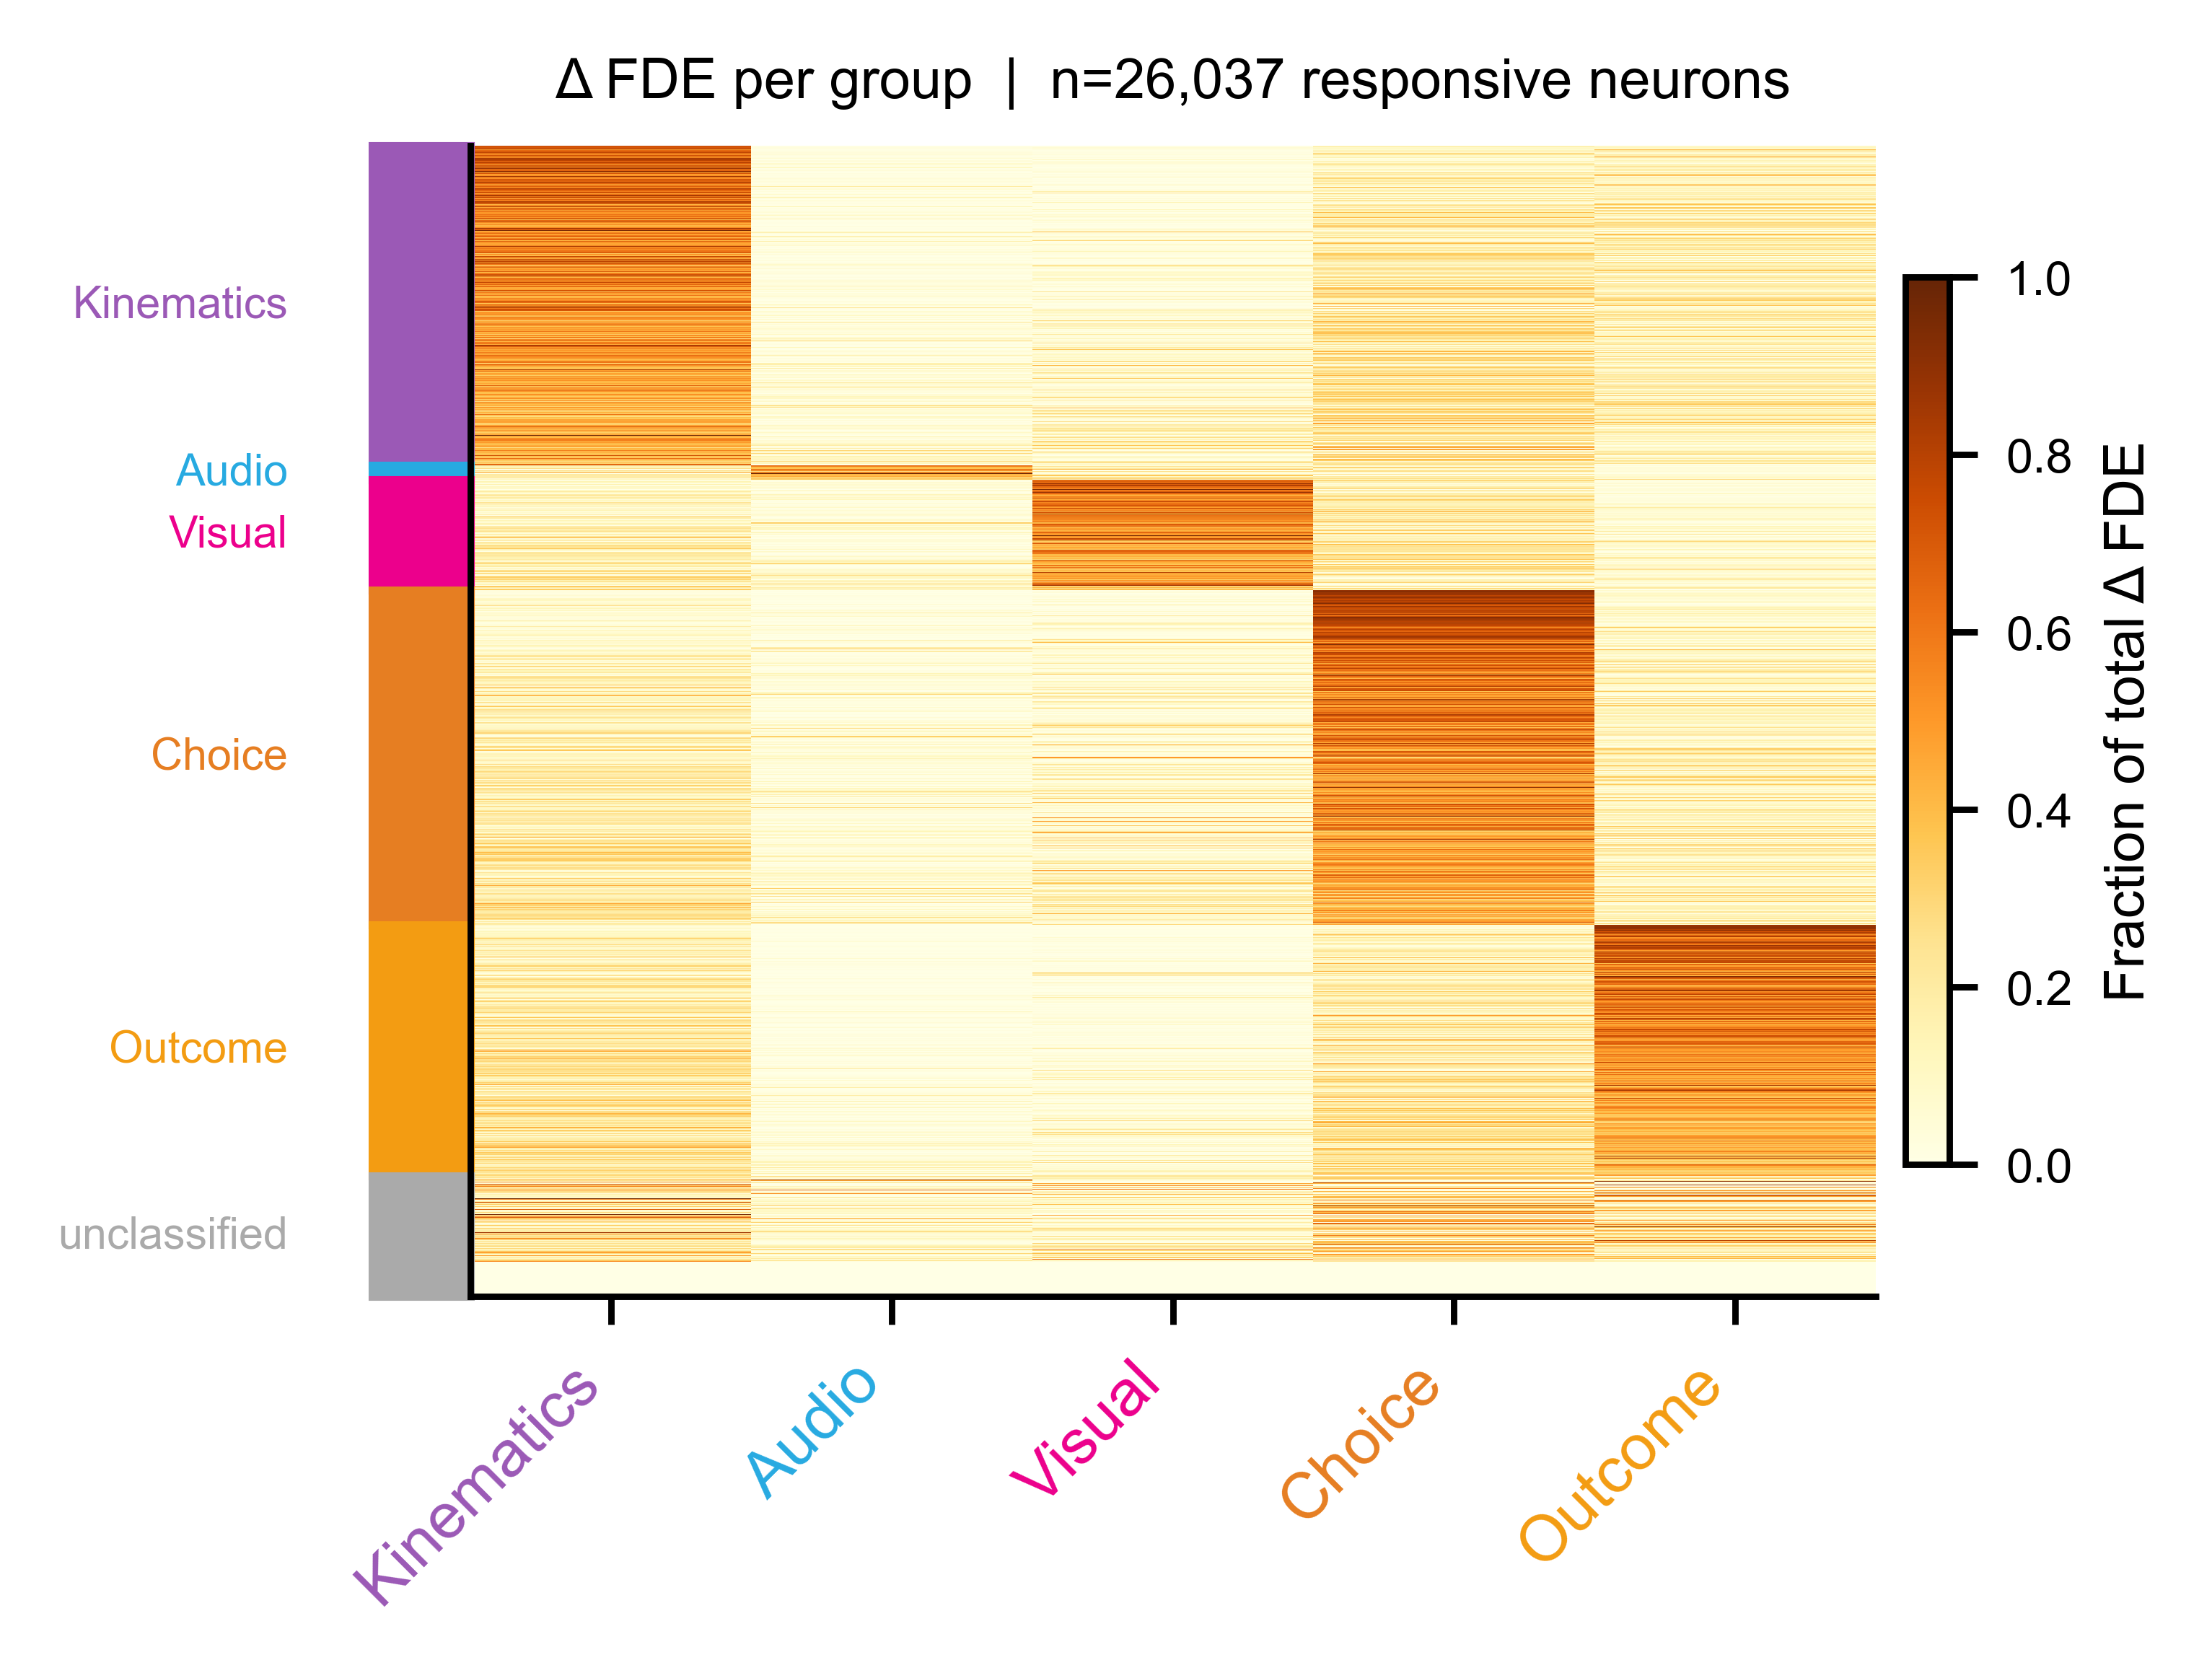

In [135]:
def plot_delta_heatmap(
    X_delta,
    df_delta_resp,
    sort_by   = 'dominant_group',
    normalise = 'row',
    figsize   = (4, 3),
    cmap      = 'YlOrBr',
):
    groups_raw = df_delta_resp.columns.tolist()

    # ── Merge predictor groups ────────────────────────────────────────────────
    MERGE_GROUPS = {
        'Kinematics': ['position_only', 'velocity'],
        'Audio':      ['audio_context', 'audio_stim'],
        'Visual':     ['visual_context', 'visual_stim'],
        'Choice':     ['choice_spatial', 'turn_onset'],
        'Outcome':    ['outcome'],
    }
    MERGE_COLORS = {
        'Kinematics': '#9B59B6',
        'Audio':      '#27AAE1',
        'Visual':     '#EC008C',
        'Choice':     '#E67E22',
        'Outcome':    '#F39C12',
    }
    MERGE_ORDER = ['Kinematics', 'Audio', 'Visual', 'Choice', 'Outcome']

    df_merged = pd.DataFrame(index=df_delta_resp.index)
    for merged_name, src_cols in MERGE_GROUPS.items():
        present = [c for c in src_cols if c in groups_raw]
        df_merged[merged_name] = df_delta_resp[present].sum(axis=1)

    groups = MERGE_ORDER
    mat    = np.clip(df_merged[groups].to_numpy(), 0, None)

    # ── Sort rows ─────────────────────────────────────────────────────────────
    meta = df_m1.loc[df_delta_resp.index]

    if sort_by == 'dominant_group':
        # Map original dominant_group to merged label
        orig_to_merged = {}
        for merged, srcs in MERGE_GROUPS.items():
            for s in srcs:
                orig_to_merged[s] = merged
        orig_to_merged.update({'mixed': 'mixed', 'unclassified': 'unclassified'})

        group_rank = {g: i for i, g in
                      enumerate(MERGE_ORDER + ['mixed', 'unclassified'])}
        merged_dom = meta['dominant_group'].map(orig_to_merged).fillna('unclassified')
        sort_keys  = (
            merged_dom.map(group_rank).fillna(99).values * 1e6
            - meta['dominant_delta'].fillna(0).values
        )
        order = np.argsort(sort_keys)
    elif sort_by in groups:
        order = np.argsort(-mat[:, groups.index(sort_by)])
    else:
        raise ValueError(f'sort_by must be "dominant_group" or one of {groups}')

    mat      = mat[order]
    meta_ord = meta.iloc[order]

    # ── Normalise ─────────────────────────────────────────────────────────────
    if normalise == 'row':
        row_sum = mat.sum(axis=1, keepdims=True)
        row_sum[row_sum == 0] = 1
        mat        = mat / row_sum
        cbar_label = 'Fraction of total Δ FDE'
        vmin, vmax = 0, 1
    elif normalise == 'zscore':
        from scipy.stats import zscore as _zscore
        mat        = np.nan_to_num(_zscore(mat, axis=1))
        cbar_label = 'Z-score across groups'
        vmin, vmax = -2, 2
    else:
        cbar_label = 'Δ frac. deviance'
        vmin, vmax = 0, np.percentile(mat[mat > 0], 99) if mat.max() > 0 else 1

    # ── Plot ──────────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    im = ax.imshow(mat, aspect='auto', cmap=cmap,
                   interpolation='nearest', vmin=vmin, vmax=vmax)

    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels(groups, rotation=45, ha='right', fontsize=8)
    ax.set_yticks([])

    # Colour the x-tick labels by group colour
    for tick, grp in zip(ax.get_xticklabels(), groups):
        tick.set_color(MERGE_COLORS[grp])

    cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label(cbar_label, fontsize=7)
    cbar.ax.tick_params(labelsize=6)

    # ── Class boundary lines + colour bar in left margin ─────────────────────
    if sort_by == 'dominant_group':
        merged_dom_ord = meta_ord['dominant_group'].map(orig_to_merged).fillna('unclassified').values
        prev, start    = merged_dom_ord[0], 0
        boundaries     = []
        for i, cls in enumerate(merged_dom_ord):
            if cls != prev:
                boundaries.append((start, i, prev))
                prev, start = cls, i
        boundaries.append((start, len(merged_dom_ord), prev))

        for s, e, cls in boundaries:
            color = MERGE_COLORS.get(cls, '#aaaaaa')
            ax.add_patch(plt.Rectangle(
                (-0.5 - 0.35, s - 0.5), 0.35, e - s,
                color=color, clip_on=False, transform=ax.transData,
            ))
            ax.text(-0.5 - 0.65, (s + e) / 2, cls,
                    ha='right', va='center', fontsize=5.5,
                    color=color, transform=ax.transData)

    ax.set_title(f'Δ FDE per group  |  n={len(mat):,} responsive neurons',
                 fontsize=7)
    plt.tight_layout()
    return fig


figure = plot_delta_heatmap(X_delta, df_delta_resp)
save_path='figures/delta_heatmap.svg'
plt.savefig(save_path, bbox_inches='tight', facecolor='white', edgecolor='none')

In [137]:
# ── Step 1: build df_delta_resp (responsive neurons only) ─────────────────────
RESP_THRESHOLD = 0.1

delta_cols = [f'delta_fd_{g}' for g in M1_GROUPS
              if f'delta_fd_{g}' in df_m1.columns]

df_resp = df_m1[df_m1['is_responsive']].copy()

df_delta_resp = df_resp[delta_cols].copy()
df_delta_resp.columns = [c.replace('delta_fd_', '') for c in delta_cols]
df_delta_resp = df_delta_resp.dropna()

print(f'Responsive neurons: {len(df_delta_resp):,} / {len(df_m1):,} '
      f'({len(df_delta_resp)/len(df_m1)*100:.1f}%)')

# ── Step 2: build X_delta ─────────────────────────────────────────────────────
X_delta = df_delta_resp.to_numpy()

# ── Step 3: row-normalise → X_norm ────────────────────────────────────────────
X_clipped = np.clip(X_delta, 0, None)
row_sum   = X_clipped.sum(axis=1, keepdims=True)
row_sum[row_sum == 0] = 1
X_norm    = X_clipped / row_sum

print(f'X_delta shape: {X_delta.shape}')
print(f'X_norm shape:  {X_norm.shape}')
print(f'NaNs in X_norm: {np.isnan(X_norm).sum()}')
print(f'Row sums (should all be ~1): min={X_norm.sum(axis=1).min():.3f}  '
      f'max={X_norm.sum(axis=1).max():.3f}')
print(f'Groups: {df_delta_resp.columns.tolist()}')

Responsive neurons: 25,253 / 56,141 (45.0%)
X_delta shape: (25253, 9)
X_norm shape:  (25253, 9)
NaNs in X_norm: 0
Row sums (should all be ~1): min=0.000  max=1.000
Groups: ['position_only', 'audio_context', 'audio_stim', 'visual_context', 'visual_stim', 'velocity', 'choice_spatial', 'turn_onset', 'outcome']


Responsive neurons : 25,253
X_norm shape       : (25253, 5)   (neurons × merged groups)
NaNs in X_norm     : 0
Row sums — min=0.000  max=1.000

PCs to explain 90% variance: 3
PCs to explain 95% variance: 4


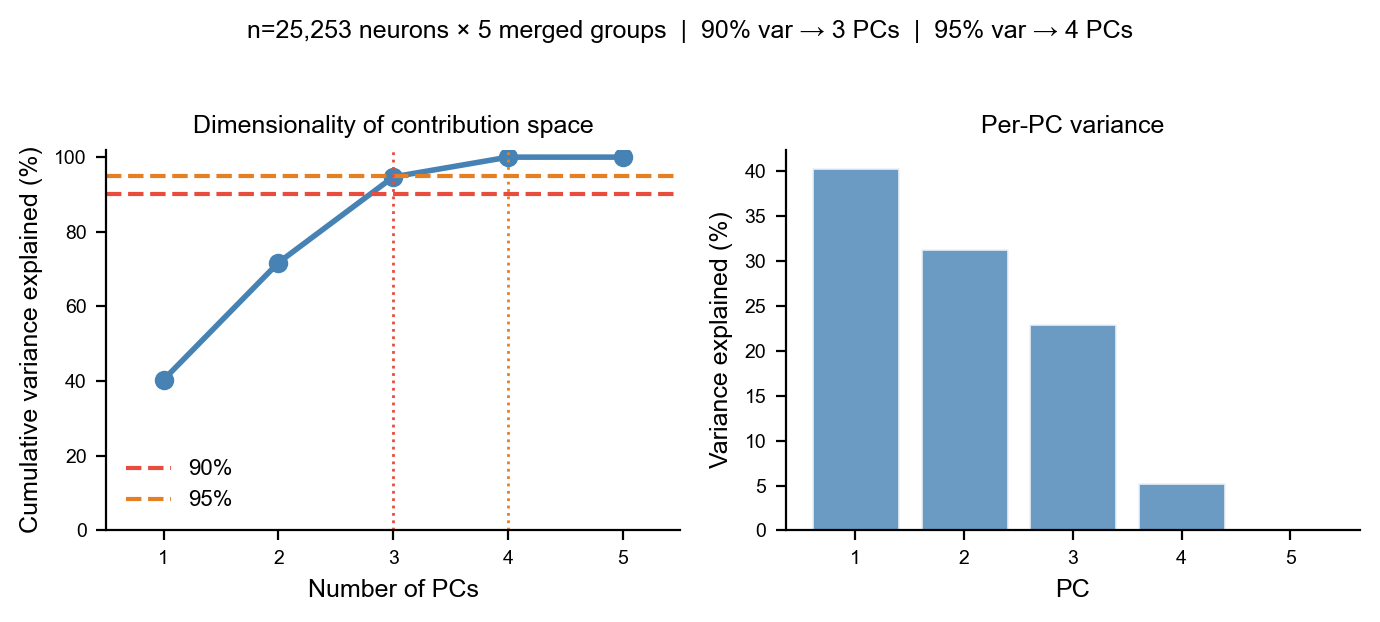

In [144]:
# ── Step 1: build df_delta_resp (responsive neurons, original 9 groups) ───────
delta_cols = [f'delta_fd_{g}' for g in M1_GROUPS
              if f'delta_fd_{g}' in df_m1.columns]

df_resp       = df_m1[df_m1['is_responsive']].copy()
df_delta_resp = df_resp[delta_cols].copy()
df_delta_resp.columns = [c.replace('delta_fd_', '') for c in delta_cols]
df_delta_resp = df_delta_resp.dropna()

# ── Step 2: merge into 5 groups ───────────────────────────────────────────────
MERGE_GROUPS = {
    'Kinematics': ['position_only', 'velocity'],
    'Audio':      ['audio_context', 'audio_stim'],
    'Visual':     ['visual_context', 'visual_stim'],
    'Choice':     ['choice_spatial', 'turn_onset'],
    'Outcome':    ['outcome'],
}
MERGE_ORDER = ['Kinematics', 'Audio', 'Visual', 'Choice', 'Outcome']
MERGE_COLORS = {
    'Kinematics': '#9B59B6',
    'Audio':      '#27AAE1',
    'Visual':     '#EC008C',
    'Choice':     '#E67E22',
    'Outcome':    '#F39C12',
}

df_merged = pd.DataFrame(index=df_delta_resp.index)
for name, src_cols in MERGE_GROUPS.items():
    present = [c for c in src_cols if c in df_delta_resp.columns]
    df_merged[name] = df_delta_resp[present].clip(lower=0).sum(axis=1)

df_merged = df_merged[MERGE_ORDER]

# ── Step 3: build X_delta and X_norm from merged matrix ──────────────────────
X_delta   = df_merged.to_numpy()
X_clipped = np.clip(X_delta, 0, None)
row_sum   = X_clipped.sum(axis=1, keepdims=True)
row_sum[row_sum == 0] = 1
X_norm    = X_clipped / row_sum

print(f'Responsive neurons : {len(df_merged):,}')
print(f'X_norm shape       : {X_norm.shape}   (neurons × merged groups)')
print(f'NaNs in X_norm     : {np.isnan(X_norm).sum()}')
print(f'Row sums — min={X_norm.sum(axis=1).min():.3f}  max={X_norm.sum(axis=1).max():.3f}')

# ── Step 4: refit PCA on 5-group X_norm ──────────────────────────────────────
from sklearn.decomposition import PCA

pca       = PCA()
pca.fit(X_norm)

cumvar    = np.cumsum(pca.explained_variance_ratio_)
n_groups  = X_norm.shape[1]   # 5
n_dims_90 = np.searchsorted(cumvar, 0.90) + 1
n_dims_95 = np.searchsorted(cumvar, 0.95) + 1

print(f'\nPCs to explain 90% variance: {n_dims_90}')
print(f'PCs to explain 95% variance: {n_dims_95}')

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(7, 3), dpi=200)

# Left: cumulative explained variance
ax = axes[0]
ax.plot(range(1, n_groups + 1), cumvar * 100, 'o-',
        color='steelblue', lw=2, markersize=6)
ax.axhline(90, color='#E74C3C', lw=1.5, ls='--', label='90%')
ax.axhline(95, color='#E67E22', lw=1.5, ls='--', label='95%')
ax.axvline(n_dims_90, color='#E74C3C', lw=1, ls=':')
ax.axvline(n_dims_95, color='#E67E22', lw=1, ls=':')
ax.set_xlabel('Number of PCs', fontsize=9)
ax.set_ylabel('Cumulative variance explained (%)', fontsize=9)
ax.set_title('Dimensionality of contribution space', fontsize=9)
ax.set_xlim(0.5, n_groups + 0.5)
ax.set_xticks(range(1, n_groups + 1))
ax.set_ylim(0, 102)
ax.legend(fontsize=8, frameon=False)
sns.despine(ax=ax)

# Right: per-PC variance with merged group colours on x-axis
MERGE_COLORS = {
    'Kinematics': '#9B59B6',
    'Audio':      '#27AAE1',
    'Visual':     '#EC008C',
    'Choice':     '#E67E22',
    'Outcome':    '#F39C12',
}
ax = axes[1]
ax.bar(range(1, n_groups + 1),
       pca.explained_variance_ratio_ * 100,
       color='steelblue', alpha=0.8, edgecolor='white')
ax.set_xlabel('PC', fontsize=9)
ax.set_ylabel('Variance explained (%)', fontsize=9)
ax.set_title('Per-PC variance', fontsize=9)
ax.set_xticks(range(1, n_groups + 1))
sns.despine(ax=ax)

plt.suptitle(
    f'n={X_norm.shape[0]:,} neurons × {n_groups} merged groups  |  '
    f'90% var → {n_dims_90} PCs  |  95% var → {n_dims_95} PCs',
    fontsize=9, y=1.02
)
plt.tight_layout()
plt.show()

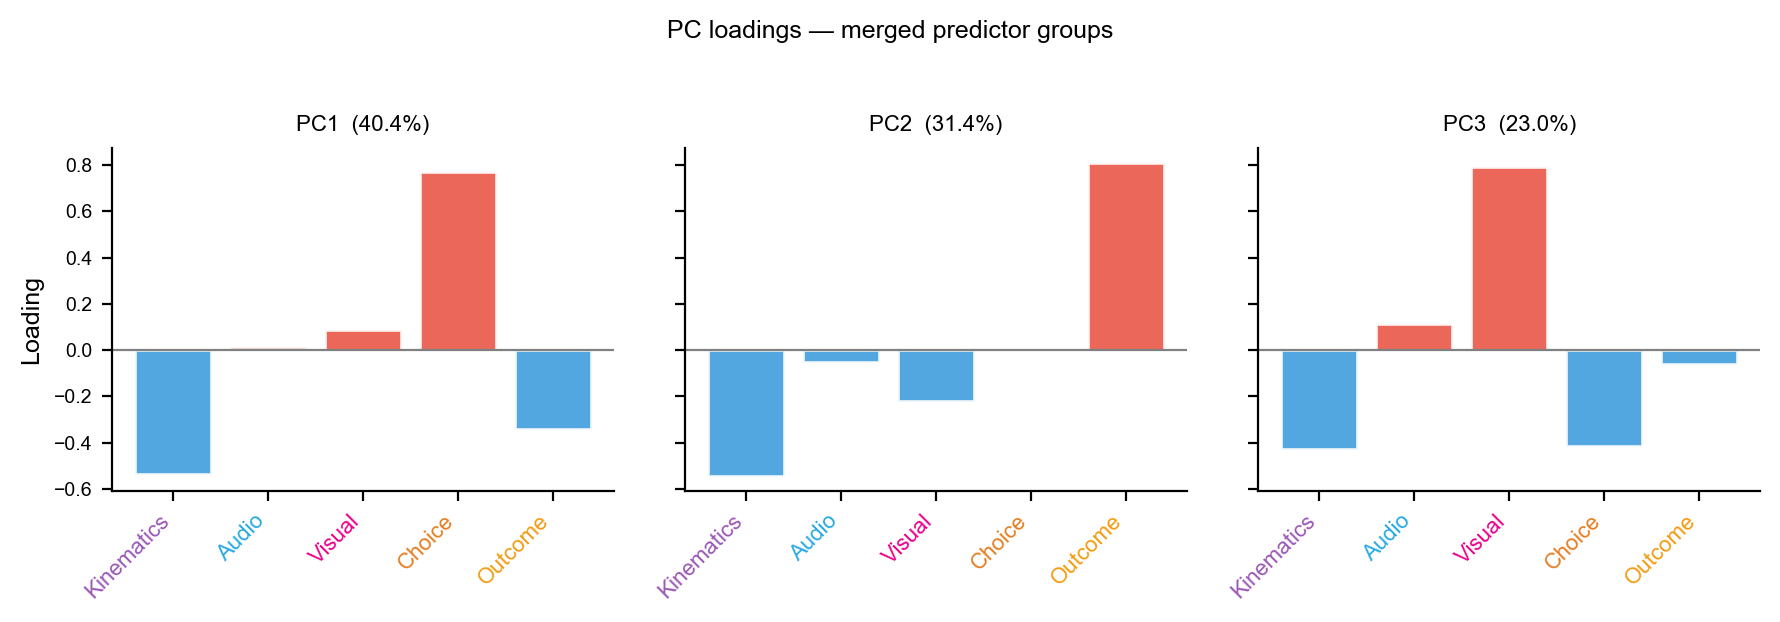

In [145]:
# groups here are the 5 merged names — use MERGE_ORDER and MERGE_COLORS directly
MERGE_ORDER = ['Kinematics', 'Audio', 'Visual', 'Choice', 'Outcome']
MERGE_COLORS = {
    'Kinematics': '#9B59B6',
    'Audio':      '#27AAE1',
    'Visual':     '#EC008C',
    'Choice':     '#E67E22',
    'Outcome':    '#F39C12',
}

groups = MERGE_ORDER   # 5 merged groups

fig, axes = plt.subplots(1, n_dims_90, figsize=(3 * n_dims_90, 3), dpi=200, sharey=True)
if n_dims_90 == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    loadings = pca.components_[i]
    colors   = ['#E74C3C' if v > 0 else '#3498DB' for v in loadings]
    ax.bar(range(len(groups)), loadings, color=colors, edgecolor='white', alpha=0.85)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels(groups, rotation=45, ha='right', fontsize=8)

    # Colour x-tick labels by merged group colour
    for tick, grp in zip(ax.get_xticklabels(), groups):
        tick.set_color(MERGE_COLORS[grp])

    ax.set_title(f'PC{i+1}  ({pca.explained_variance_ratio_[i]*100:.1f}%)', fontsize=8)
    if i == 0:
        ax.set_ylabel('Loading', fontsize=9)
    sns.despine(ax=ax)

plt.suptitle('PC loadings — merged predictor groups', fontsize=9, y=1.02)
plt.tight_layout()
plt.show()

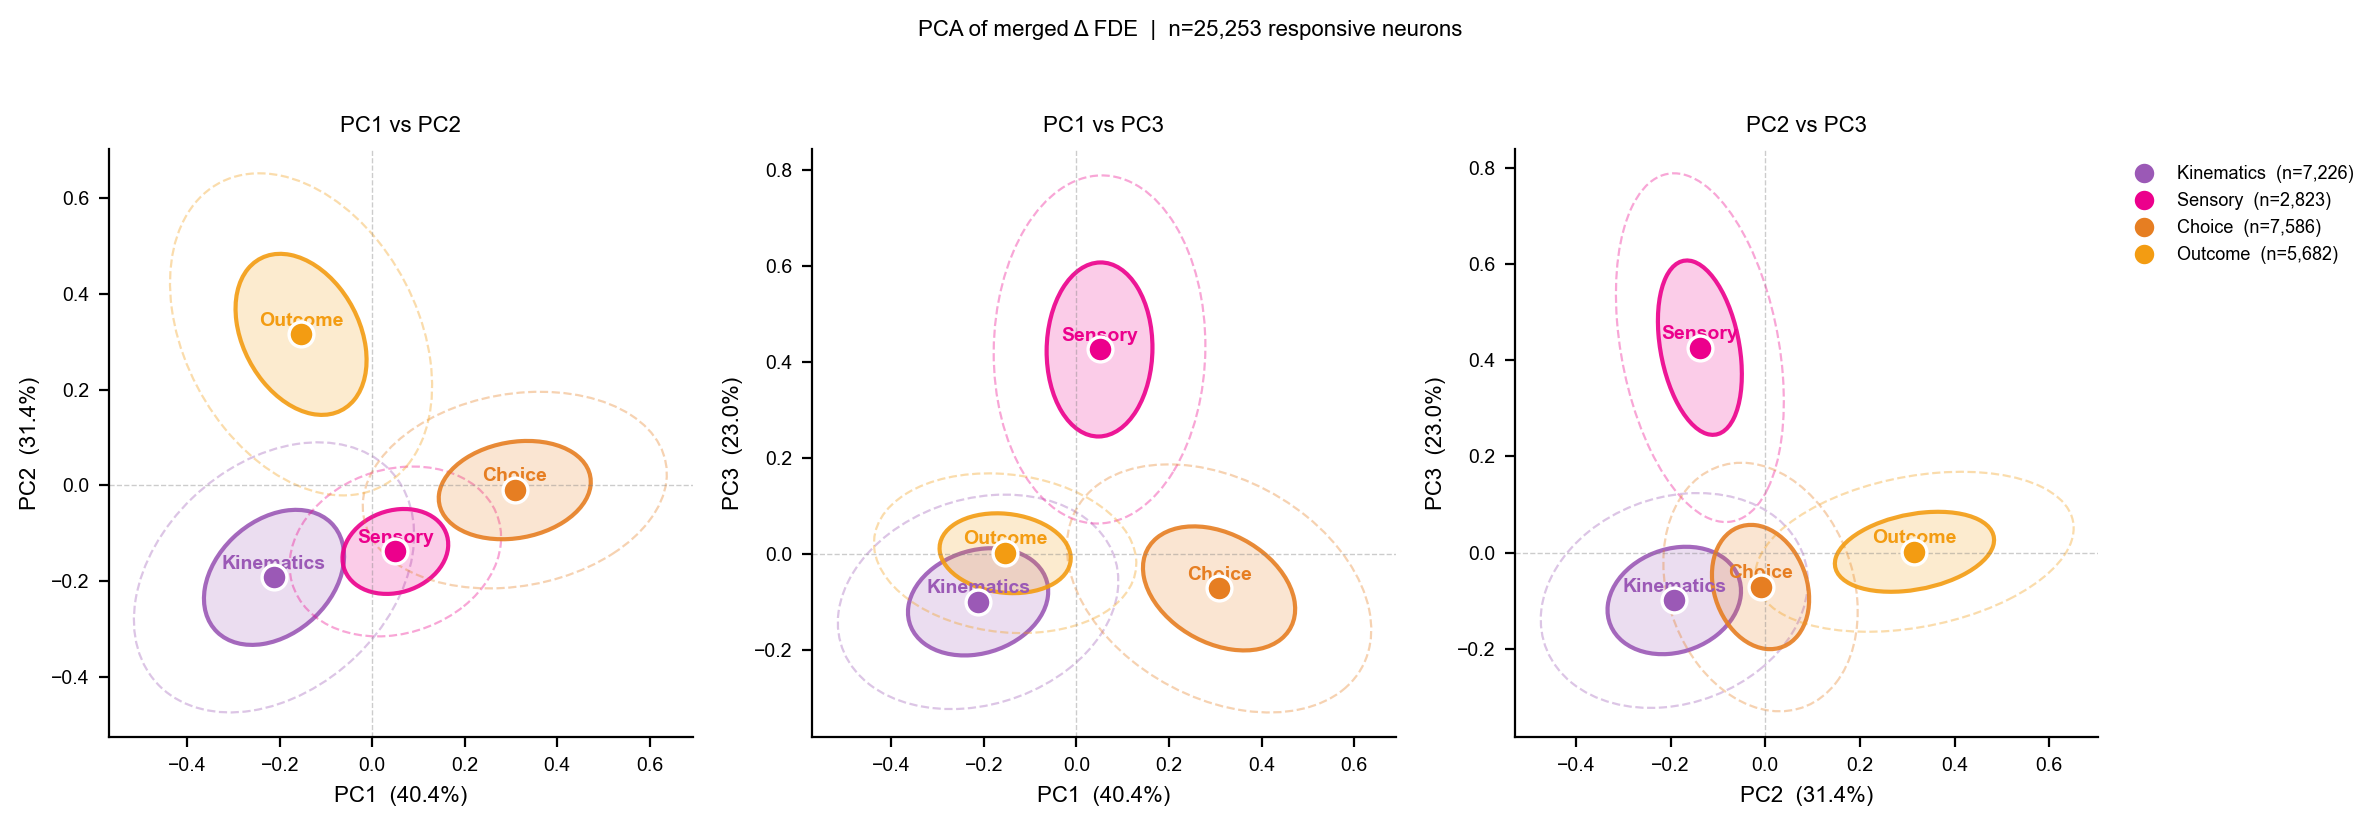

In [146]:
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

# ── confidence ellipse helper ─────────────────────────────────────────────────
def confidence_ellipse(x, y, ax, n_std=1.0, facecolor='none', **kwargs):
    if len(x) < 3:
        return
    cov  = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    rx   = np.sqrt(1 + pearson)
    ry   = np.sqrt(1 - pearson)
    ellipse = Ellipse((0, 0), width=rx*2, height=ry*2,
                      facecolor=facecolor, **kwargs)
    scale_x = np.sqrt(cov[0, 0]) * n_std
    scale_y = np.sqrt(cov[1, 1]) * n_std
    t = (transforms.Affine2D()
         .rotate_deg(45)
         .scale(scale_x, scale_y)
         .translate(np.mean(x), np.mean(y)))
    ellipse.set_transform(t + ax.transData)
    ax.add_patch(ellipse)

# ── PCA scores ────────────────────────────────────────────────────────────────
scores = pca.transform(X_norm)   # (n_responsive_neurons, 5)

# ── Map dominant_group → merged cloud label ───────────────────────────────────
orig_to_cloud = {
    'position_only':  'kinematics',
    'velocity':       'kinematics',
    'audio_context':  'sensory',
    'audio_stim':     'sensory',
    'visual_context': 'sensory',
    'visual_stim':    'sensory',
    'choice_spatial': 'choice',
    'turn_onset':     'choice',
    'outcome':        'outcome',
    'mixed':          'mixed',
    'unclassified':   'unclassified',
}

meta = df_m1.loc[df_delta_resp.index]
cloud_labels_per_neuron = meta['dominant_group'].map(orig_to_cloud).fillna('unclassified')

CLOUD_COLORS = {
    'kinematics':  '#9B59B6',
    'sensory':     '#EC008C',
    'choice':      '#E67E22',
    'outcome':     '#F39C12',
    'mixed':       '#95A5A6',
    'unclassified':'#BDC3C7',
}
CLOUD_LABELS = {
    'kinematics':  'Kinematics',
    'sensory':     'Sensory',
    'choice':      'Choice',
    'outcome':     'Outcome',
    'mixed':       'Mixed',
    'unclassified':'Unclassified',
}

PLOT_CLOUDS = ['kinematics', 'sensory', 'choice', 'outcome']

# ── PC scatter plots ──────────────────────────────────────────────────────────
pc_pairs = [(0, 1), (0, 2), (1, 2)]   # PC1v2, PC1v3, PC2v3

fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=200)

for ax, (px, py) in zip(axes, pc_pairs):
    for cloud in PLOT_CLOUDS:
        mask = (cloud_labels_per_neuron == cloud).values
        if mask.sum() < 10:
            continue
        x     = scores[mask, px]
        y     = scores[mask, py]
        color = CLOUD_COLORS[cloud]
        label = CLOUD_LABELS[cloud]

        confidence_ellipse(x, y, ax, n_std=1.0,
                           facecolor=color, alpha=0.2, edgecolor='none')
        confidence_ellipse(x, y, ax, n_std=1.0,
                           facecolor='none', edgecolor=color, lw=1.5, alpha=0.9)
        confidence_ellipse(x, y, ax, n_std=2.0,
                           facecolor='none', edgecolor=color, lw=0.8,
                           alpha=0.35, linestyle='--')

        cx, cy = np.mean(x), np.mean(y)
        ax.scatter(cx, cy, color=color, s=80, zorder=5,
                   edgecolors='white', linewidths=1.2)
        ax.text(cx, cy + 0.01, label,
                ha='center', va='bottom', fontsize=7,
                color=color, fontweight='bold')

    ax.axhline(0, color='gray', lw=0.5, ls='--', alpha=0.4)
    ax.axvline(0, color='gray', lw=0.5, ls='--', alpha=0.4)

    vx = pca.explained_variance_ratio_[px] * 100
    vy = pca.explained_variance_ratio_[py] * 100
    ax.set_xlabel(f'PC{px+1}  ({vx:.1f}%)', fontsize=8)
    ax.set_ylabel(f'PC{py+1}  ({vy:.1f}%)', fontsize=8)
    ax.set_title(f'PC{px+1} vs PC{py+1}', fontsize=8)
    sns.despine(ax=ax)

handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor=CLOUD_COLORS[c], markersize=8,
               label=f'{CLOUD_LABELS[c]}  (n={(cloud_labels_per_neuron==c).sum():,})')
    for c in PLOT_CLOUDS
]
axes[-1].legend(handles=handles, fontsize=6.5, frameon=False,
                bbox_to_anchor=(1.02, 1), loc='upper left')

plt.suptitle(f'PCA of merged Δ FDE  |  n={len(scores):,} responsive neurons',
             fontsize=8, y=1.02)
plt.tight_layout()
plt.show()

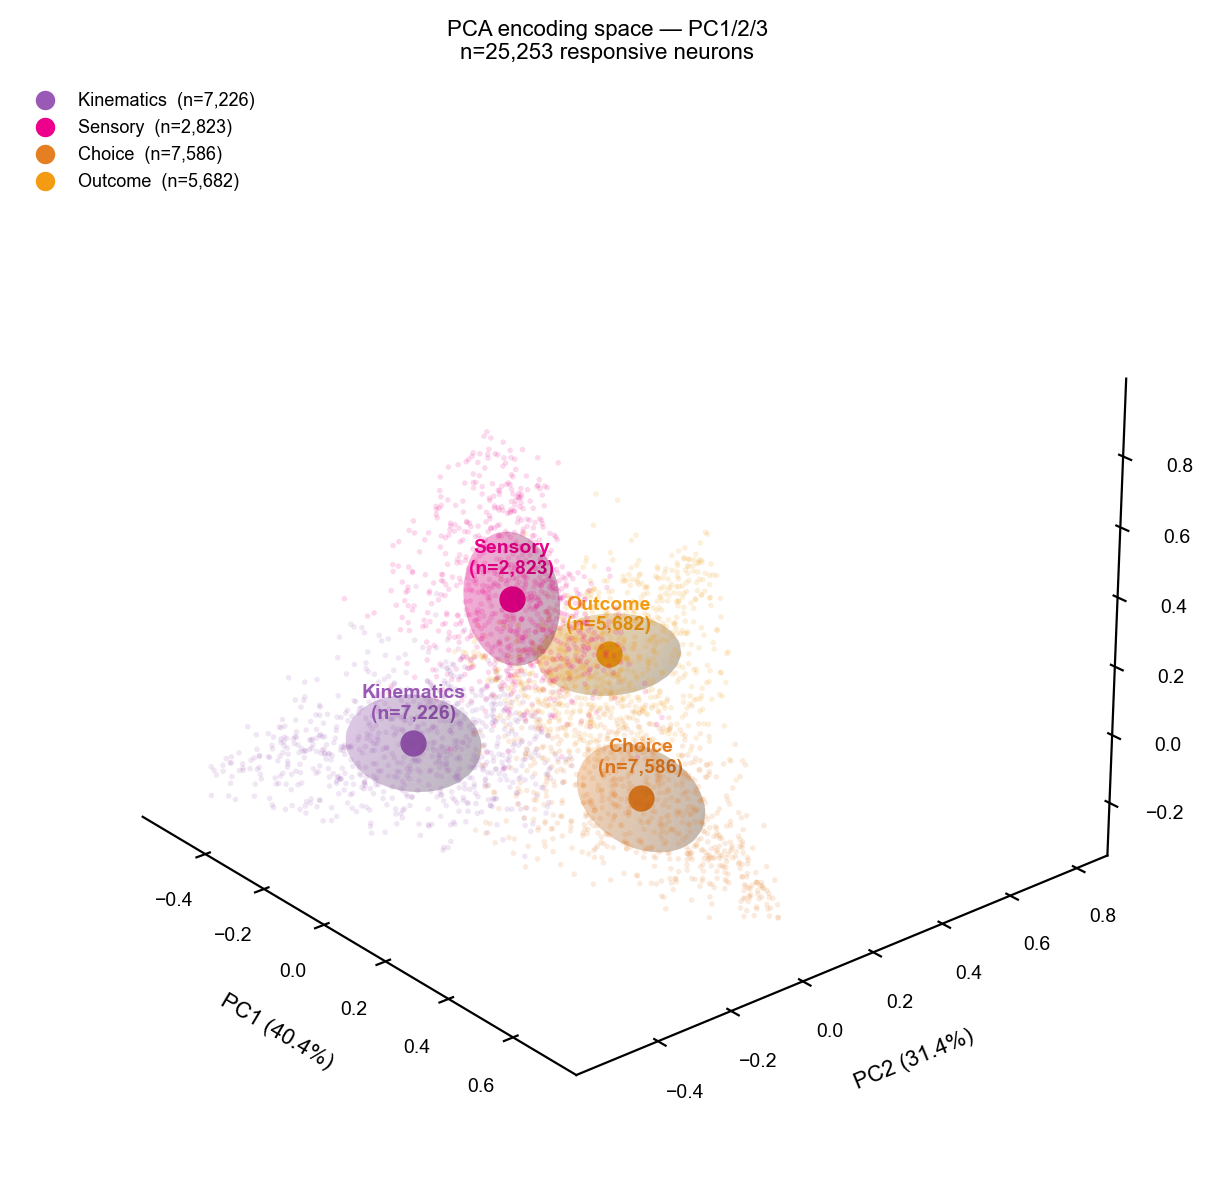

In [148]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(7, 6), dpi=200)
ax  = fig.add_subplot(111, projection='3d')

for cloud in PLOT_CLOUDS:
    mask  = (cloud_labels_per_neuron == cloud).values
    if mask.sum() < 10:
        continue
    x     = scores[mask, 0]
    y     = scores[mask, 1]
    z     = scores[mask, 2]
    color = CLOUD_COLORS[cloud]
    label = CLOUD_LABELS[cloud]
    n     = mask.sum()

    # Subsampled scatter
    rng     = np.random.default_rng(seed=42)
    sub_idx = rng.choice(n, size=min(800, n), replace=False)
    ax.scatter(x[sub_idx], y[sub_idx], z[sub_idx],
               color=color, alpha=0.15, s=4, linewidths=0)

    # 1 SD ellipsoid shell
    cx, cy, cz = np.mean(x), np.mean(y), np.mean(z)
    rx, ry, rz = np.std(x), np.std(y), np.std(z)
    u = np.linspace(0, 2*np.pi, 30)
    v = np.linspace(0,   np.pi, 30)
    xs = cx + rx * np.outer(np.cos(u), np.sin(v))
    ys = cy + ry * np.outer(np.sin(u), np.sin(v))
    zs = cz + rz * np.outer(np.ones_like(u), np.cos(v))
    ax.plot_surface(xs, ys, zs, color=color, alpha=0.18, linewidth=0)

    # Centroid
    ax.scatter(cx, cy, cz, color=color, s=120, zorder=10,
               edgecolors='white', linewidths=1.5)
    ax.text(cx, cy, cz + 0.06, f'{label}\n(n={n:,})',
            ha='center', va='bottom', fontsize=7,
            color=color, fontweight='bold')

# Axis labels
v1, v2, v3 = [pca.explained_variance_ratio_[i]*100 for i in range(3)]
ax.set_xlabel(f'PC1 ({v1:.1f}%)', fontsize=8, labelpad=6)
ax.set_ylabel(f'PC2 ({v2:.1f}%)', fontsize=8, labelpad=6)
ax.set_zlabel(f'PC3 ({v3:.1f}%)', fontsize=8, labelpad=6)
ax.set_title(f'PCA encoding space — PC1/2/3\nn={len(scores):,} responsive neurons',
             fontsize=8)

# ── Remove grid and clean panes ───────────────────────────────────────────────
ax.grid(False)
ax.xaxis.pane.fill       = False
ax.yaxis.pane.fill       = False
ax.zaxis.pane.fill       = False
ax.xaxis.pane.set_edgecolor('none')
ax.yaxis.pane.set_edgecolor('none')
ax.zaxis.pane.set_edgecolor('none')
ax.xaxis._axinfo['grid']['color'] = (1, 1, 1, 0)
ax.yaxis._axinfo['grid']['color'] = (1, 1, 1, 0)
ax.zaxis._axinfo['grid']['color'] = (1, 1, 1, 0)

# Viewing angle
ax.view_init(elev=25, azim=-40)

# Legend
handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor=CLOUD_COLORS[c], markersize=8,
               label=f'{CLOUD_LABELS[c]}  (n={(cloud_labels_per_neuron==c).sum():,})')
    for c in PLOT_CLOUDS
]
ax.legend(handles=handles, fontsize=6.5, frameon=False,
          loc='upper left', bbox_to_anchor=(-0.05, 1.0))

plt.tight_layout()
plt.show()

## Section 1 — Model 1: Population Composition & Behavioural Encoding

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_80318/9084854.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(mice, rotation=30, ha='right', fontsize=8)


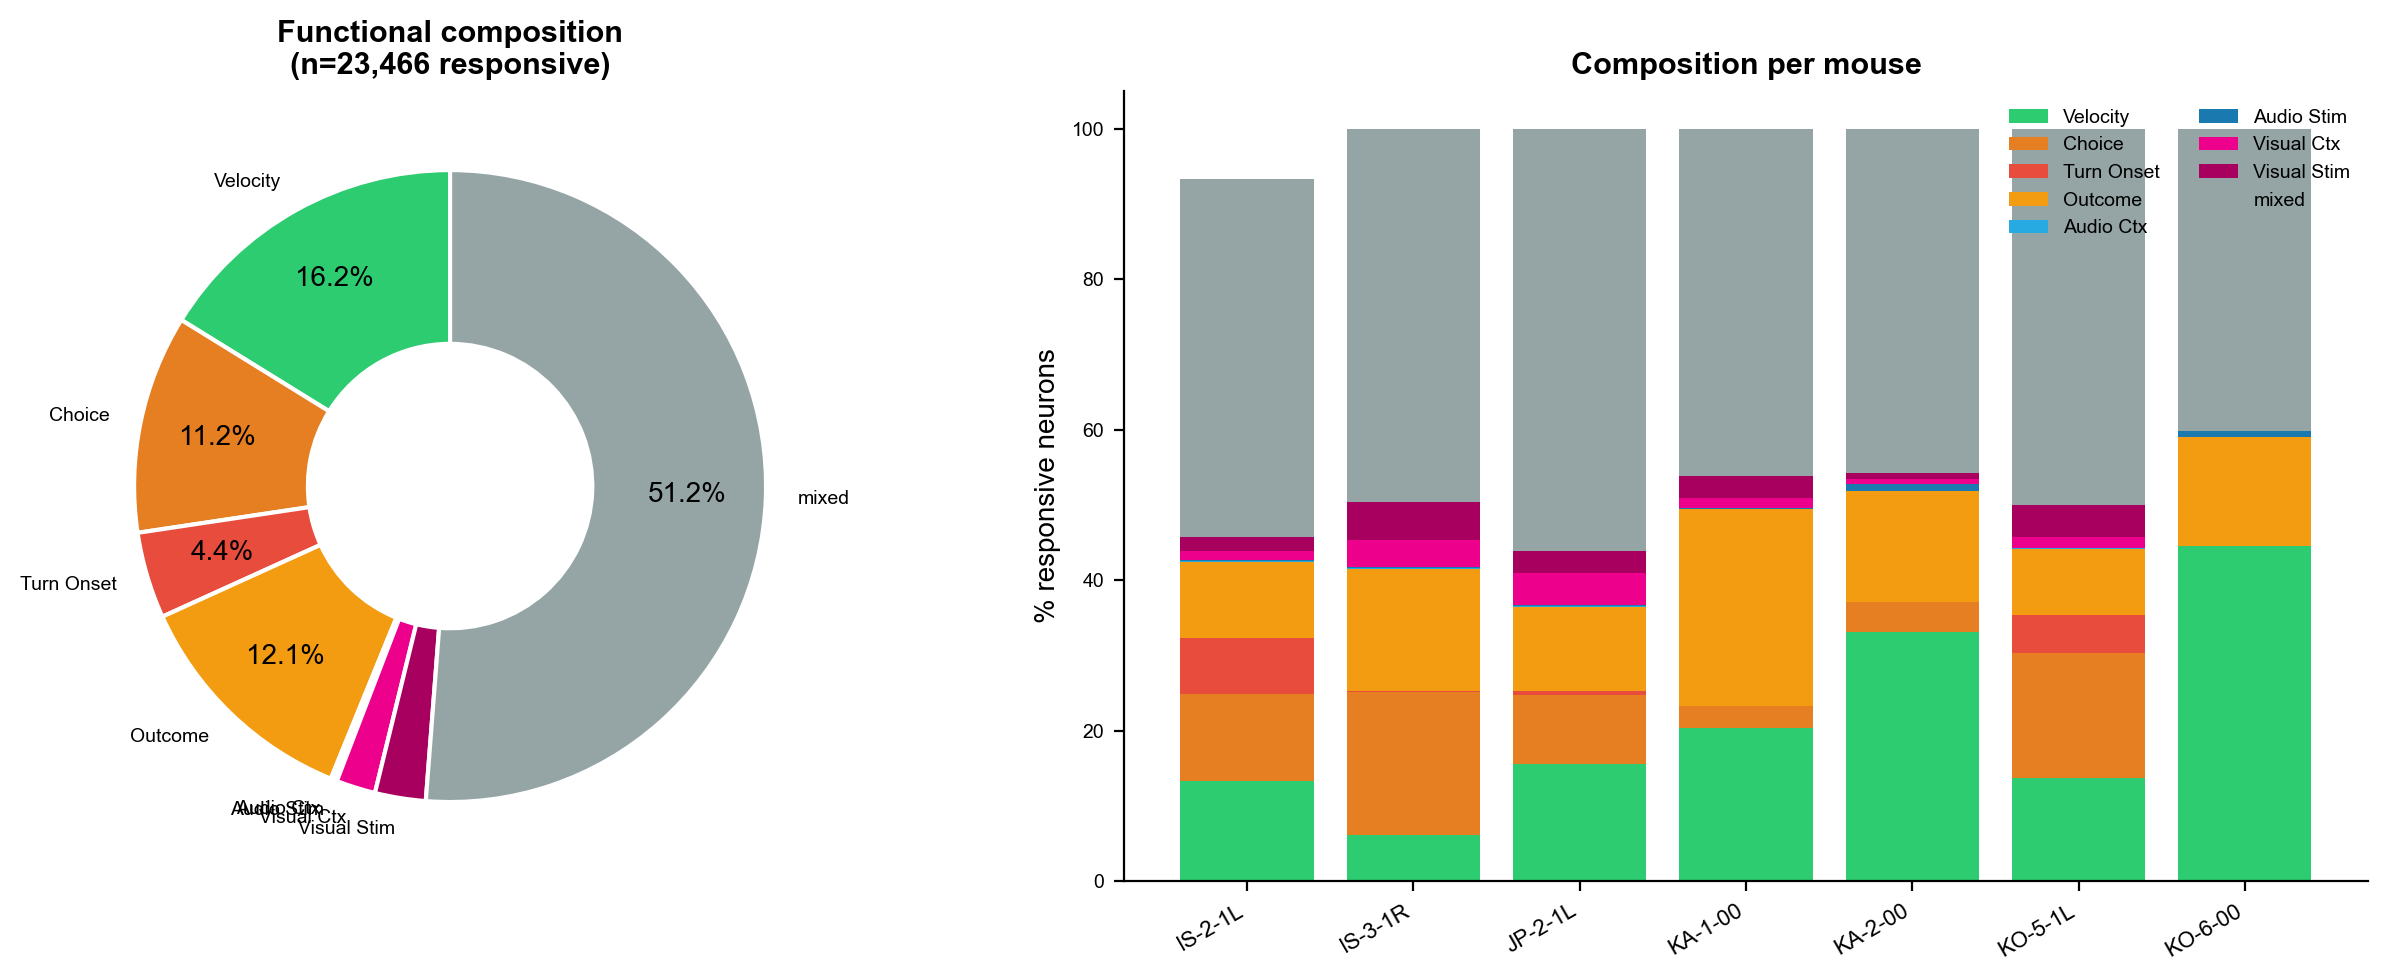

In [9]:
# ── 1a. Population composition — pie + per-mouse bar ──────────────────────────
df_resp = df_m1[resp_m1].copy()
class_order = ['velocity','choice_spatial','turn_onset','outcome',
                'audio_context','audio_stim','visual_context','visual_stim',
                'position_only','mixed','unclassified']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Donut
ax = axes[0]
counts = df_resp['neuron_class'].value_counts()
present = [c for c in class_order if c in counts.index]
vals    = [counts.get(c, 0) for c in present]
colors  = [CLASS_COLORS.get(c, '#BDC3C7') for c in present]
wedges, texts, autotexts = ax.pie(
    vals, labels=[GROUP_LABELS.get(c, c) for c in present],
    colors=colors, autopct=lambda p: f'{p:.1f}%' if p > 3 else '',
    startangle=90, pctdistance=0.75,
    wedgeprops=dict(width=0.55, edgecolor='white', linewidth=1.5),
)
ax.set_title(f'Functional composition\n(n={len(df_resp):,} responsive)', fontsize=11, fontweight='bold')

# Per-mouse stacked bar
ax = axes[1]
mice = list(df_resp['mouse_ID'].unique())
bottom = np.zeros(len(mice))
for cls in present:
    fracs = []
    for m in mice:
        sub = df_resp[df_resp['mouse_ID']==m]['neuron_class']
        fracs.append((sub==cls).mean() * 100)
    ax.bar(mice, fracs, bottom=bottom,
           color=CLASS_COLORS.get(cls,'#BDC3C7'), label=GROUP_LABELS.get(cls,cls))
    bottom += np.array(fracs)
ax.set_ylabel('% responsive neurons', fontsize=10)
ax.set_title('Composition per mouse', fontsize=11, fontweight='bold')
ax.set_xticklabels(mice, rotation=30, ha='right', fontsize=8)
ax.legend(loc='upper right', fontsize=7, ncol=2, frameon=False)
plt.tight_layout()
plt.show()

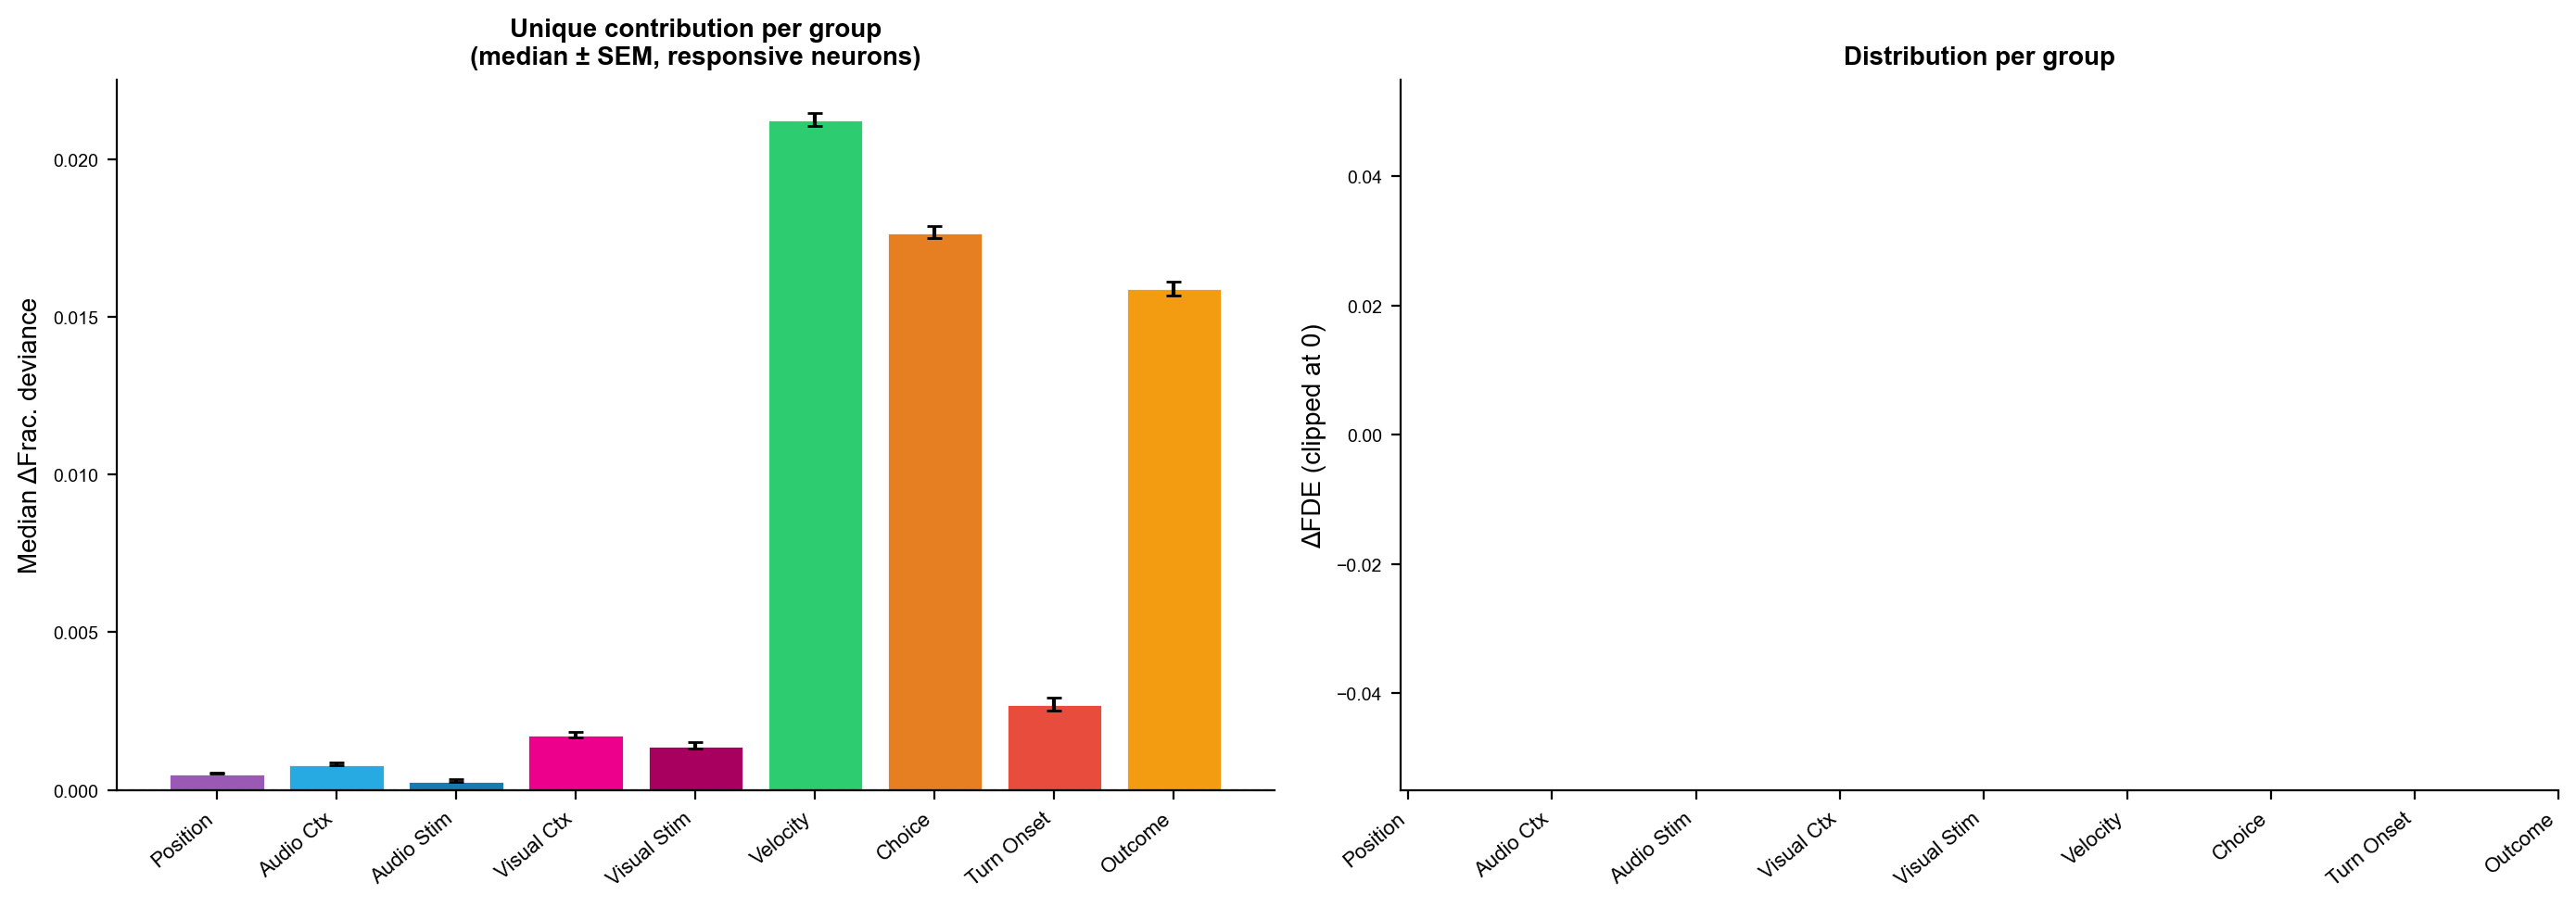

In [30]:
# ── 1b. Lesion contribution profiles — bar chart + violin ─────────────────────
delta_cols = [f'delta_fd_{g}' for g in M1_GROUPS if f'delta_fd_{g}' in df_resp.columns]
groups_present = [c.replace('delta_fd_','') for c in delta_cols]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar: median delta_FDE per group
ax = axes[0]
medians = [df_resp[c].median() for c in delta_cols]
sems    = [df_resp[c].sem() for c in delta_cols]
cols    = [GROUP_COLORS.get(g,'gray') for g in groups_present]
bars = ax.bar(range(len(groups_present)), medians, color=cols, edgecolor='white')
ax.errorbar(range(len(groups_present)), medians, yerr=sems, fmt='none', color='black', capsize=3, lw=1.5)
ax.set_xticks(range(len(groups_present)))
ax.set_xticklabels([GROUP_LABELS.get(g,g) for g in groups_present], rotation=40, ha='right', fontsize=8)
ax.set_ylabel('Median ΔFrac. deviance', fontsize=10)
ax.set_title('Unique contribution per group\n(median ± SEM, responsive neurons)', fontsize=10, fontweight='bold')
ax.axhline(0, color='k', lw=0.8, ls='--', alpha=0.4)

# Violin per group
ax = axes[1]
data_for_violin = [df_resp[c].clip(lower=0).values for c in delta_cols]
vp = ax.violinplot(data_for_violin, positions=range(len(groups_present)),
                   showmedians=True, showextrema=False)
for pc, g in zip(vp['bodies'], groups_present):
    pc.set_facecolor(GROUP_COLORS.get(g,'gray'))
    pc.set_alpha(0.7)
vp['cmedians'].set_color('black'); vp['cmedians'].set_linewidth(2)
ax.set_xticks(range(len(groups_present)))
ax.set_xticklabels([GROUP_LABELS.get(g,g) for g in groups_present], rotation=40, ha='right', fontsize=8)
ax.set_ylabel('ΔFDE (clipped at 0)', fontsize=10)
ax.set_title('Distribution per group', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

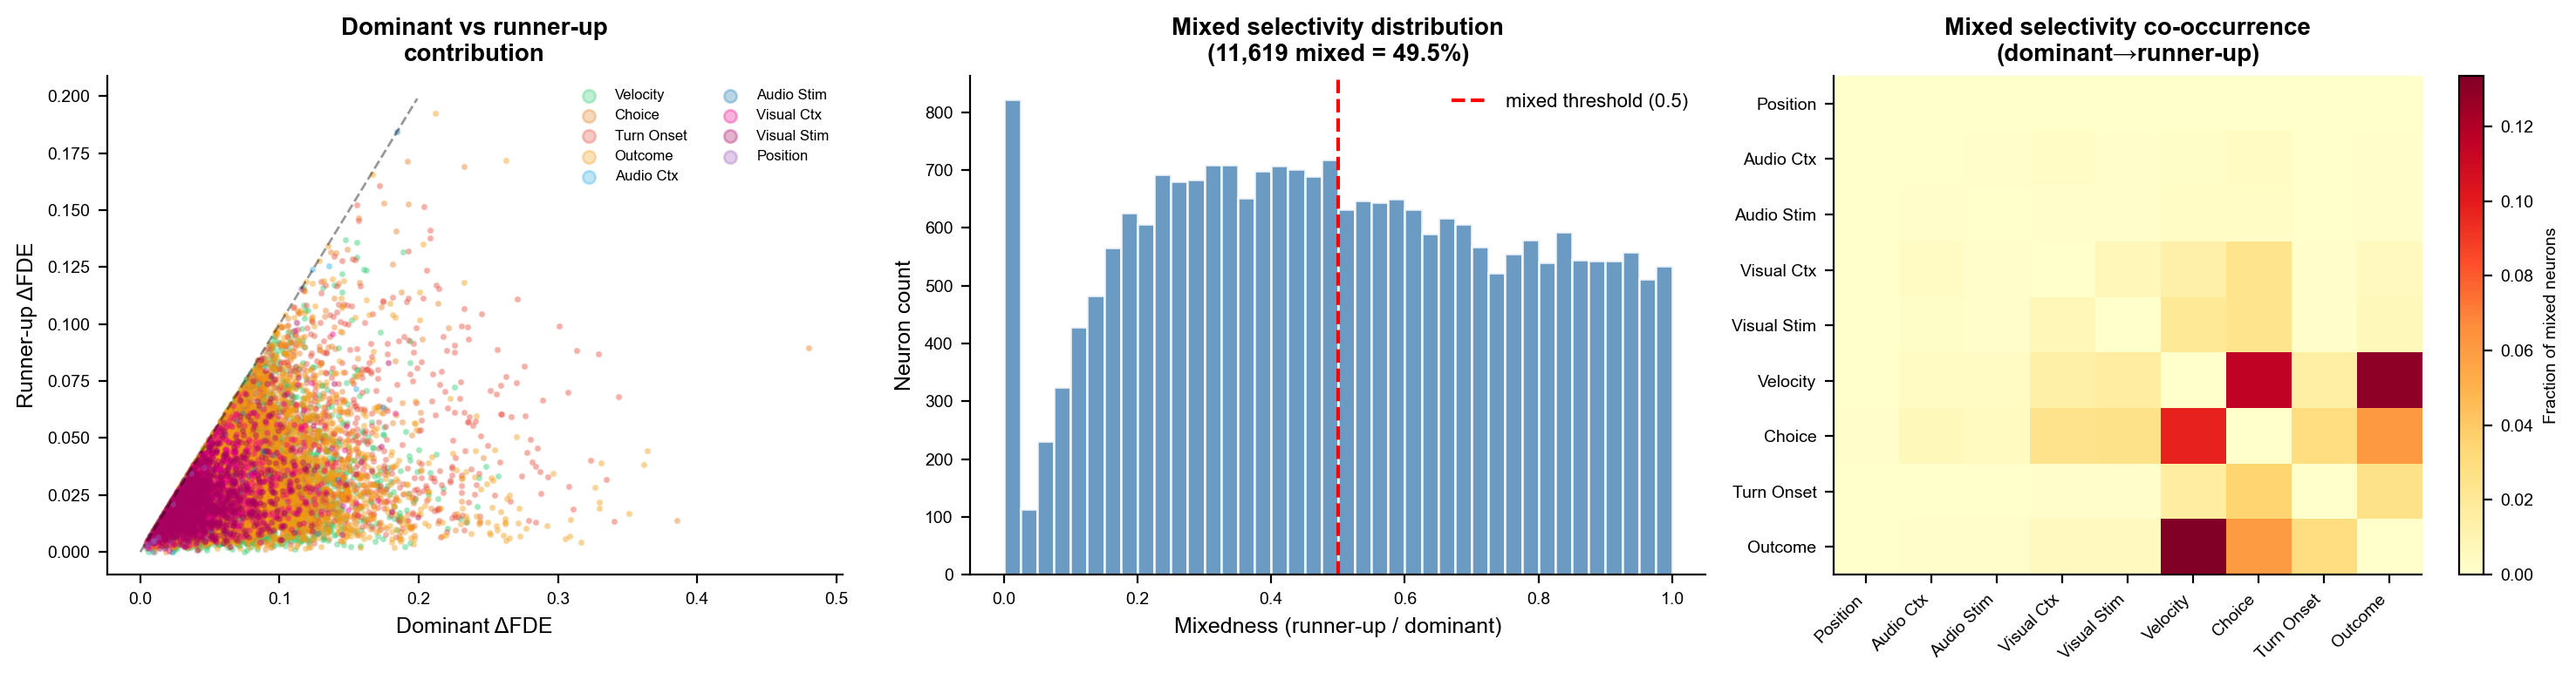

In [31]:
# ── 1c. Mixed selectivity analysis ────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Scatter: dominant vs runner-up delta
ax = axes[0]
for cls in class_order:
    sub = df_resp[df_resp['dominant_group']==cls] if cls not in ('mixed','unclassified') else pd.DataFrame()
    if len(sub) == 0: continue
    ax.scatter(sub['dominant_delta'], sub['runner_up_delta'], s=3, alpha=0.3,
               color=CLASS_COLORS.get(cls,'gray'), label=GROUP_LABELS.get(cls,cls))
lim = max(df_resp['dominant_delta'].quantile(0.99), df_resp['runner_up_delta'].quantile(0.99))
ax.plot([0,lim],[0,lim],'k--',lw=1,alpha=0.4)
ax.set_xlabel('Dominant ΔFDE', fontsize=9); ax.set_ylabel('Runner-up ΔFDE', fontsize=9)
ax.set_title('Dominant vs runner-up\ncontribution', fontsize=10, fontweight='bold')
ax.legend(fontsize=6, markerscale=3, frameon=False, ncol=2)

# Histogram of mixedness
ax = axes[1]
ax.hist(df_resp['mixedness'], bins=40, color='steelblue', edgecolor='white', alpha=0.8)
ax.axvline(0.5, color='red', ls='--', lw=1.5, label='mixed threshold (0.5)')
n_mixed = df_resp['is_mixed'].sum()
ax.set_xlabel('Mixedness (runner-up / dominant)', fontsize=9)
ax.set_ylabel('Neuron count', fontsize=9)
ax.set_title(f'Mixed selectivity distribution\n({n_mixed:,} mixed = {n_mixed/len(df_resp)*100:.1f}%)',
             fontsize=10, fontweight='bold')
ax.legend(fontsize=8, frameon=False)

# Co-occurrence heatmap
ax = axes[2]
pure = df_resp[~df_resp['is_mixed'] & (df_resp['neuron_class']!='unclassified')]
mixed_neurons = df_resp[df_resp['is_mixed']]
g_list = [g for g in M1_GROUPS if f'delta_fd_{g}' in df_m1.columns]
comat = np.zeros((len(g_list), len(g_list)))
for i, gi in enumerate(g_list):
    for j, gj in enumerate(g_list):
        comat[i,j] = ((mixed_neurons['dominant_group']==gi) & (mixed_neurons['runner_up_group']==gj)).sum()
comat_norm = comat / (comat.sum() + 1e-9)
im = ax.imshow(comat_norm, cmap='YlOrRd', aspect='auto')
labels_short = [GROUP_LABELS.get(g,g) for g in g_list]
ax.set_xticks(range(len(g_list))); ax.set_xticklabels(labels_short, rotation=45, ha='right', fontsize=7)
ax.set_yticks(range(len(g_list))); ax.set_yticklabels(labels_short, fontsize=7)
ax.set_title('Mixed selectivity co-occurrence\n(dominant→runner-up)', fontsize=10, fontweight='bold')
plt.colorbar(im, ax=ax, label='Fraction of mixed neurons')
plt.tight_layout()
plt.show()

## Section 2 — Model 1: Context Modulation

CG (multi) vs Visual: p=2.78e-40
CG (multi) vs Audio: p=5.02e-117
Visual vs Audio: p=8.98e-27


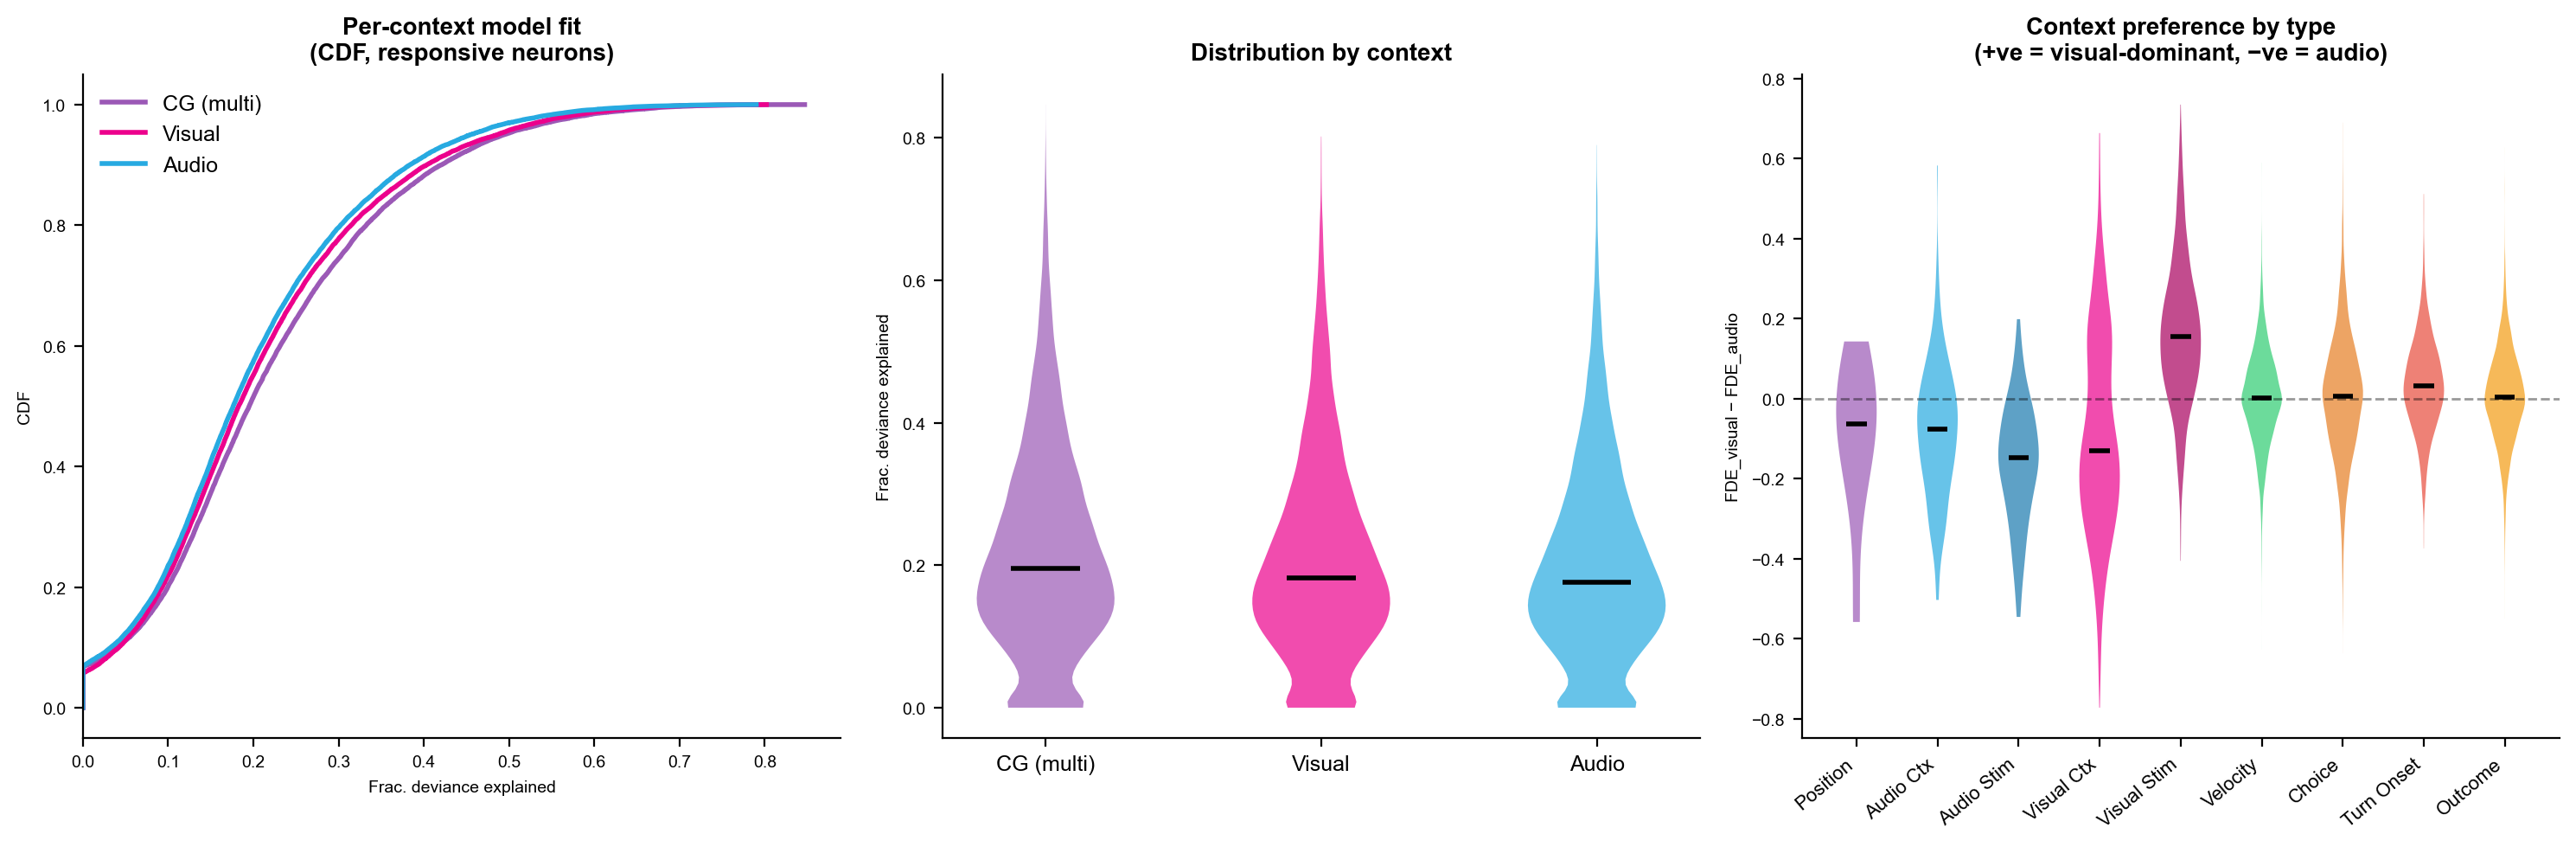

In [32]:
# ── 2a. Per-context model fit ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

ctx_fd_cols = ['frac_dev_cg','frac_dev_visual','frac_dev_audio']
ctx_labels  = ['CG (multi)', 'Visual', 'Audio']
ctx_colors  = [CTX_COLORS_STR['cg'], CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio']]

# CDF per context
ax = axes[0]
for col, lbl, col_c in zip(ctx_fd_cols, ctx_labels, ctx_colors):
    x = np.sort(df_resp[col].values)
    y = np.linspace(0,1,len(x))
    ax.plot(x, y, color=col_c, lw=2, label=lbl)
ax.set_xlabel('Frac. deviance explained'); ax.set_ylabel('CDF')
ax.set_title('Per-context model fit\n(CDF, responsive neurons)', fontsize=10, fontweight='bold')
ax.legend(fontsize=9, frameon=False)
ax.set_xlim(0, None)

# Violin per context
ax = axes[1]
data_ctx = [df_resp[c].values for c in ctx_fd_cols]
vp = ax.violinplot(data_ctx, positions=range(3), showmedians=True, showextrema=False)
for pc, col_c in zip(vp['bodies'], ctx_colors):
    pc.set_facecolor(col_c); pc.set_alpha(0.7)
vp['cmedians'].set_color('black'); vp['cmedians'].set_linewidth(2)
ax.set_xticks(range(3)); ax.set_xticklabels(ctx_labels, fontsize=9)
ax.set_ylabel('Frac. deviance explained')
ax.set_title('Distribution by context', fontsize=10, fontweight='bold')
# Stats
for i,(c1,c2) in enumerate([(0,1),(0,2),(1,2)]):
    s, p = stats.wilcoxon(df_resp[ctx_fd_cols[c1]], df_resp[ctx_fd_cols[c2]])
    print(f'{ctx_labels[c1]} vs {ctx_labels[c2]}: p={p:.2e}')

# Context preference index by functional type
ax = axes[2]
class_list = [g for g in M1_GROUPS if g in df_resp['dominant_group'].values]
ctx_pref_by_class = [df_resp[df_resp['dominant_group']==g]['ctx_pref_vis_aud'].values
                     for g in class_list]
vp2 = ax.violinplot(ctx_pref_by_class, positions=range(len(class_list)), showmedians=True, showextrema=False)
for pc, g in zip(vp2['bodies'], class_list):
    pc.set_facecolor(GROUP_COLORS.get(g,'gray')); pc.set_alpha(0.7)
vp2['cmedians'].set_color('black'); vp2['cmedians'].set_linewidth(2)
ax.axhline(0, color='k', lw=1, ls='--', alpha=0.4)
ax.set_xticks(range(len(class_list)))
ax.set_xticklabels([GROUP_LABELS.get(g,g) for g in class_list], rotation=40, ha='right', fontsize=8)
ax.set_ylabel('FDE_visual − FDE_audio')
ax.set_title('Context preference by type\n(+ve = visual-dominant, −ve = audio)', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

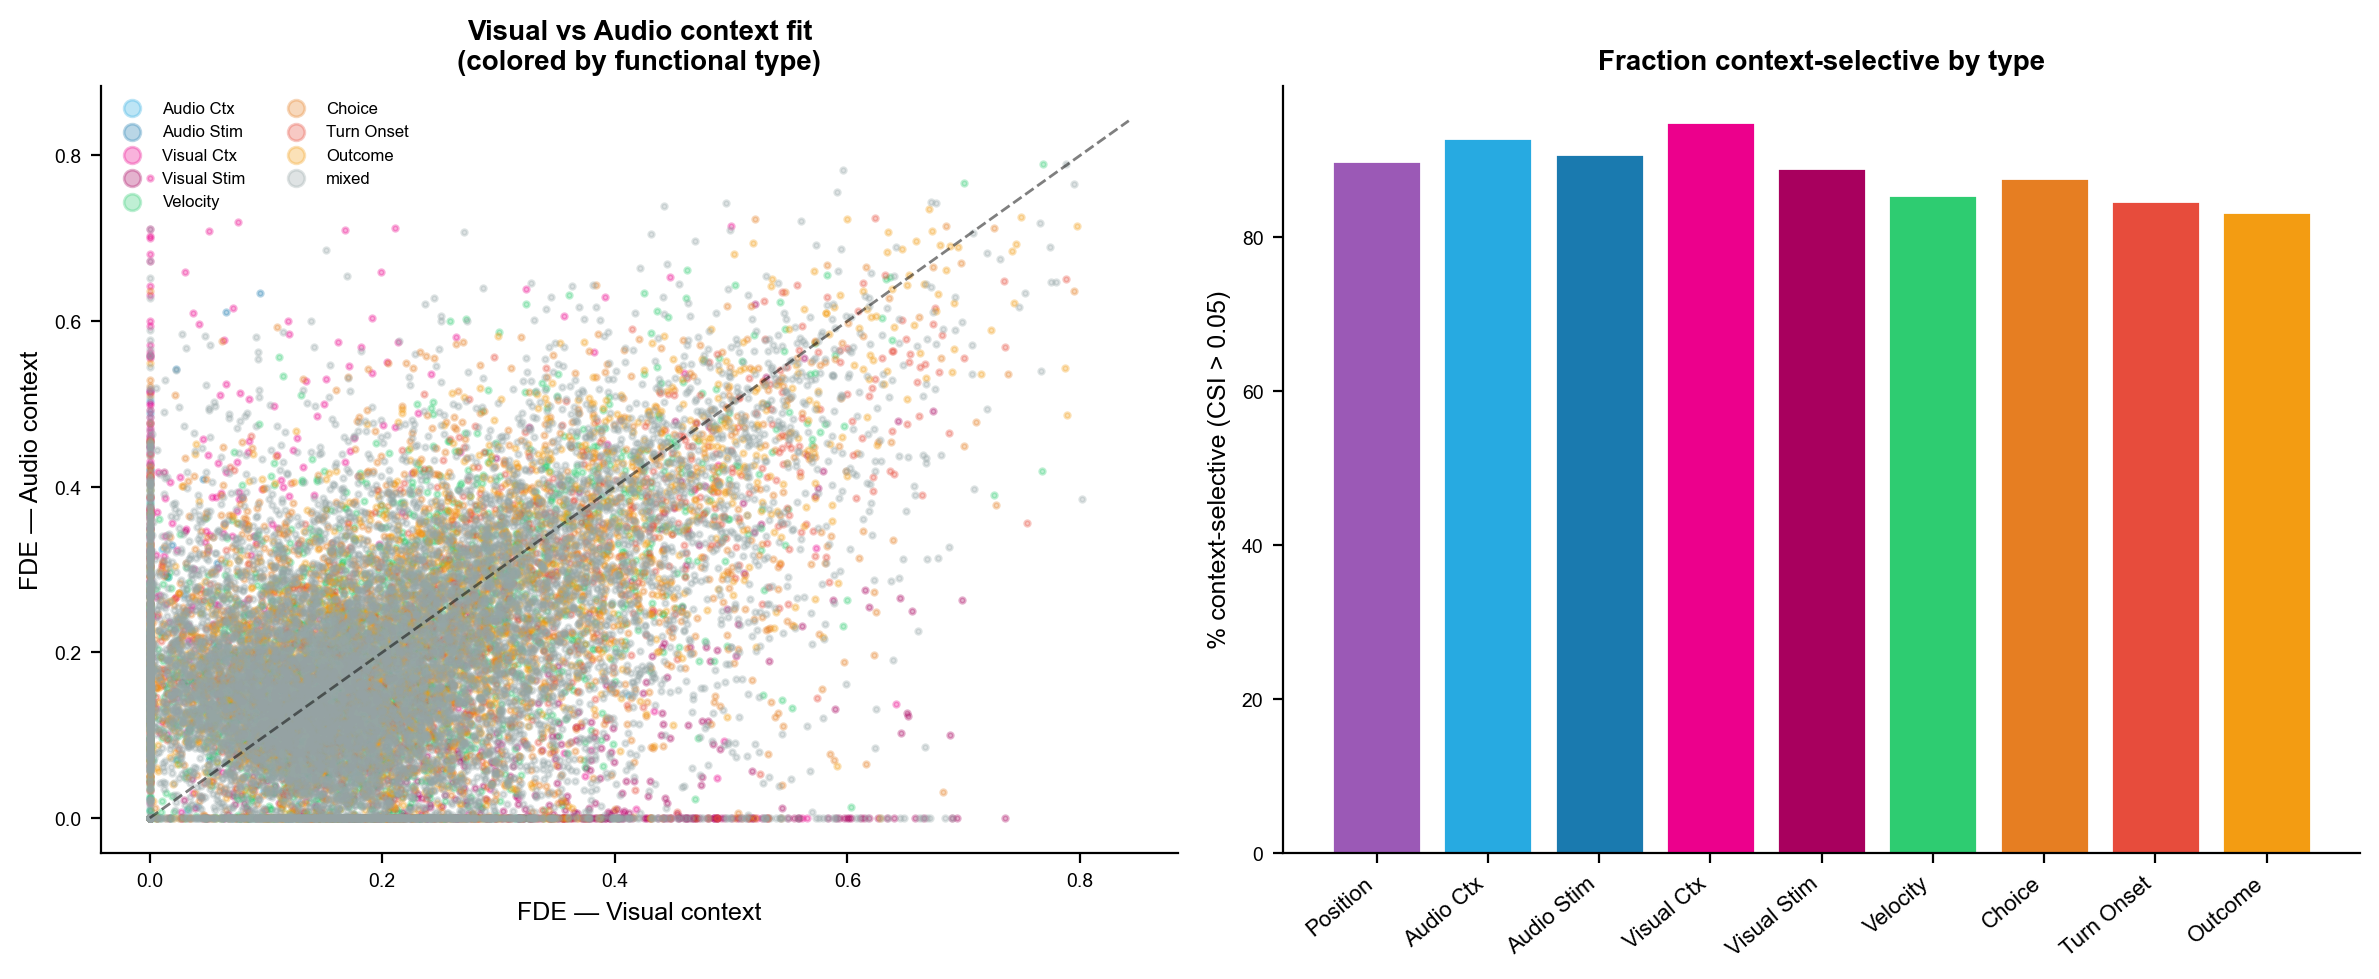

In [33]:
# ── 2b. Context-gated neurons ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Scatter: FDE_visual vs FDE_audio
ax = axes[0]
classes_to_plot = [g for g in M1_GROUPS if g in df_resp['dominant_group'].values]
for cls in classes_to_plot + ['mixed']:
    sub = df_resp[df_resp['neuron_class']==cls] if cls in df_resp['neuron_class'].values else pd.DataFrame()
    if len(sub)==0: continue
    ax.scatter(sub['frac_dev_visual'], sub['frac_dev_audio'],
               s=4, alpha=0.3, color=CLASS_COLORS.get(cls,'gray'),
               label=GROUP_LABELS.get(cls,cls))
lim = max(df_resp[['frac_dev_visual','frac_dev_audio']].values.max() * 1.05, 0.1)
ax.plot([0,lim],[0,lim],'k--',lw=1,alpha=0.5)
ax.set_xlabel('FDE — Visual context', fontsize=9)
ax.set_ylabel('FDE — Audio context', fontsize=9)
ax.set_title('Visual vs Audio context fit\n(colored by functional type)', fontsize=10, fontweight='bold')
ax.legend(fontsize=6, markerscale=3, frameon=False, ncol=2)

# Fraction context-gated per type (threshold: |ctx_pref_vis_aud| > 0.05)
ax = axes[1]
gated_thresh = 0.05
frac_gated = []
for g in classes_to_plot:
    sub = df_resp[df_resp['dominant_group']==g]
    frac_gated.append((sub['context_pref_idx'] > gated_thresh).mean() * 100)
bars = ax.bar(range(len(classes_to_plot)), frac_gated,
              color=[GROUP_COLORS.get(g,'gray') for g in classes_to_plot], edgecolor='white')
ax.set_xticks(range(len(classes_to_plot)))
ax.set_xticklabels([GROUP_LABELS.get(g,g) for g in classes_to_plot], rotation=40, ha='right', fontsize=8)
ax.set_ylabel(f'% context-selective (CSI > {gated_thresh})', fontsize=9)
ax.set_title('Fraction context-selective by type', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

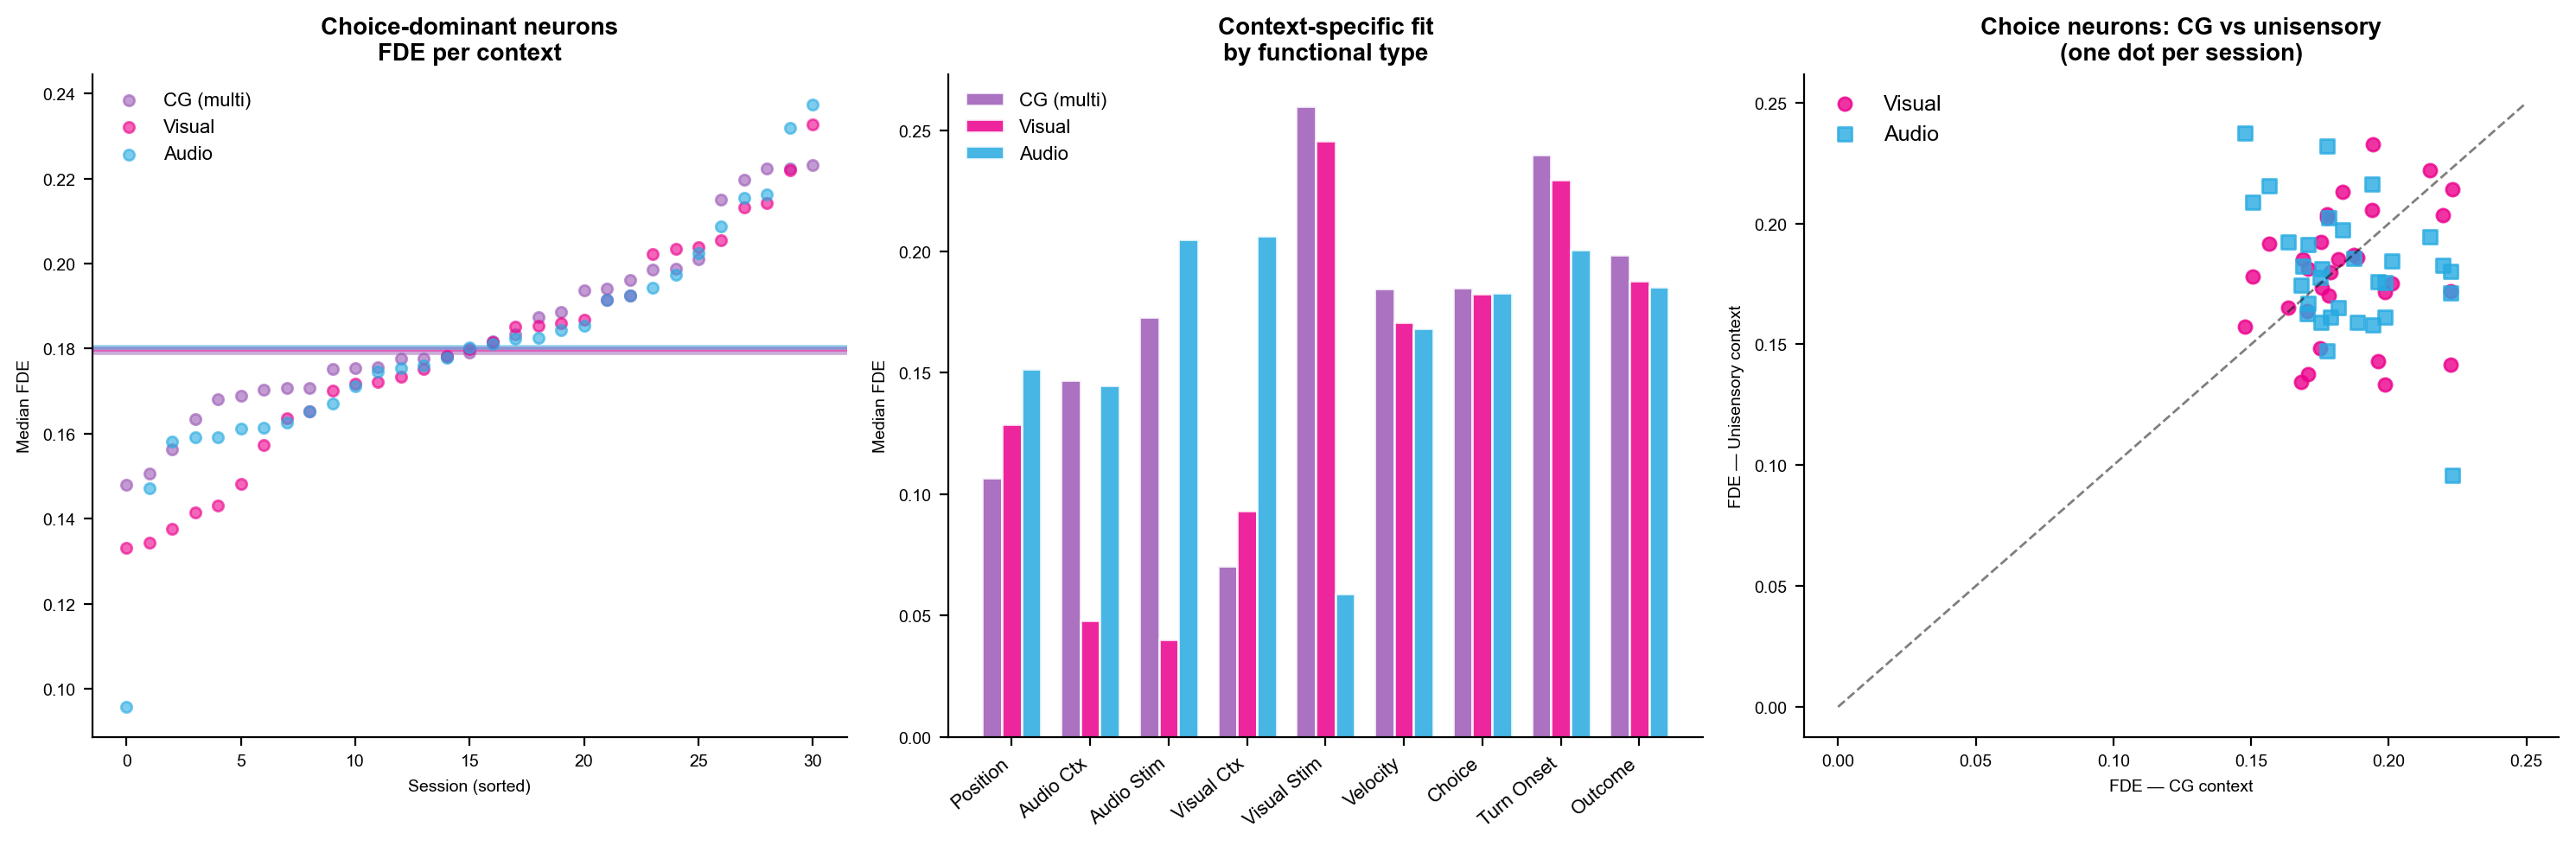

In [34]:
# ── 2c. Choice coding × context ───────────────────────────────────────────────
# Compare choice FDE per context using context-specific test masks
# NOTE: this requires loading per-context lesion data from individual session pkls.
# Here we use the per-context full-model FDE for neurons classified as choice-dominant
# as a proxy (full comparison requires per-context lesion refits).

choice_neurons = df_resp[df_resp['dominant_group']=='choice_spatial']
other_neurons  = df_resp[df_resp['dominant_group']!='choice_spatial']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Context FDE distribution for choice-dominant neurons
ax = axes[0]
for col, lbl, col_c in zip(ctx_fd_cols, ctx_labels, ctx_colors):
    medians = choice_neurons.groupby(['mouse_ID','date'])[col].median()
    ax.scatter(range(len(medians)), medians.sort_values(), s=20, alpha=0.6,
               color=col_c, label=lbl, zorder=3)
    ax.axhline(medians.median(), color=col_c, lw=2, ls='-', alpha=0.5)
ax.set_xlabel('Session (sorted)'); ax.set_ylabel('Median FDE')
ax.set_title('Choice-dominant neurons\nFDE per context', fontsize=10, fontweight='bold')
ax.legend(fontsize=8, frameon=False)

# Bar: median FDE per context for each functional type
ax = axes[1]
x = np.arange(len(classes_to_plot))
w = 0.25
for i, (col, lbl, col_c) in enumerate(zip(ctx_fd_cols, ctx_labels, ctx_colors)):
    meds = [df_resp[df_resp['dominant_group']==g][col].median() for g in classes_to_plot]
    ax.bar(x + i*w, meds, width=w, color=col_c, label=lbl, edgecolor='white', alpha=0.85)
ax.set_xticks(x + w)
ax.set_xticklabels([GROUP_LABELS.get(g,g) for g in classes_to_plot], rotation=40, ha='right', fontsize=8)
ax.set_ylabel('Median FDE'); ax.legend(fontsize=8, frameon=False)
ax.set_title('Context-specific fit\nby functional type', fontsize=10, fontweight='bold')

# Is CG better for choice? Paired comparison across sessions
ax = axes[2]
choice_sess = choice_neurons.groupby(['mouse_ID','date'])[ctx_fd_cols].median()
ax.scatter(choice_sess['frac_dev_cg'], choice_sess['frac_dev_visual'],
           s=30, color=CTX_COLORS_STR['visual'], alpha=0.8, label='Visual')
ax.scatter(choice_sess['frac_dev_cg'], choice_sess['frac_dev_audio'],
           s=30, color=CTX_COLORS_STR['audio'], alpha=0.8, label='Audio', marker='s')
lim = max(choice_sess.values.max() * 1.05, 0.05)
ax.plot([0,lim],[0,lim],'k--',lw=1,alpha=0.5)
ax.set_xlabel('FDE — CG context'); ax.set_ylabel('FDE — Unisensory context')
ax.set_title('Choice neurons: CG vs unisensory\n(one dot per session)', fontsize=10, fontweight='bold')
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

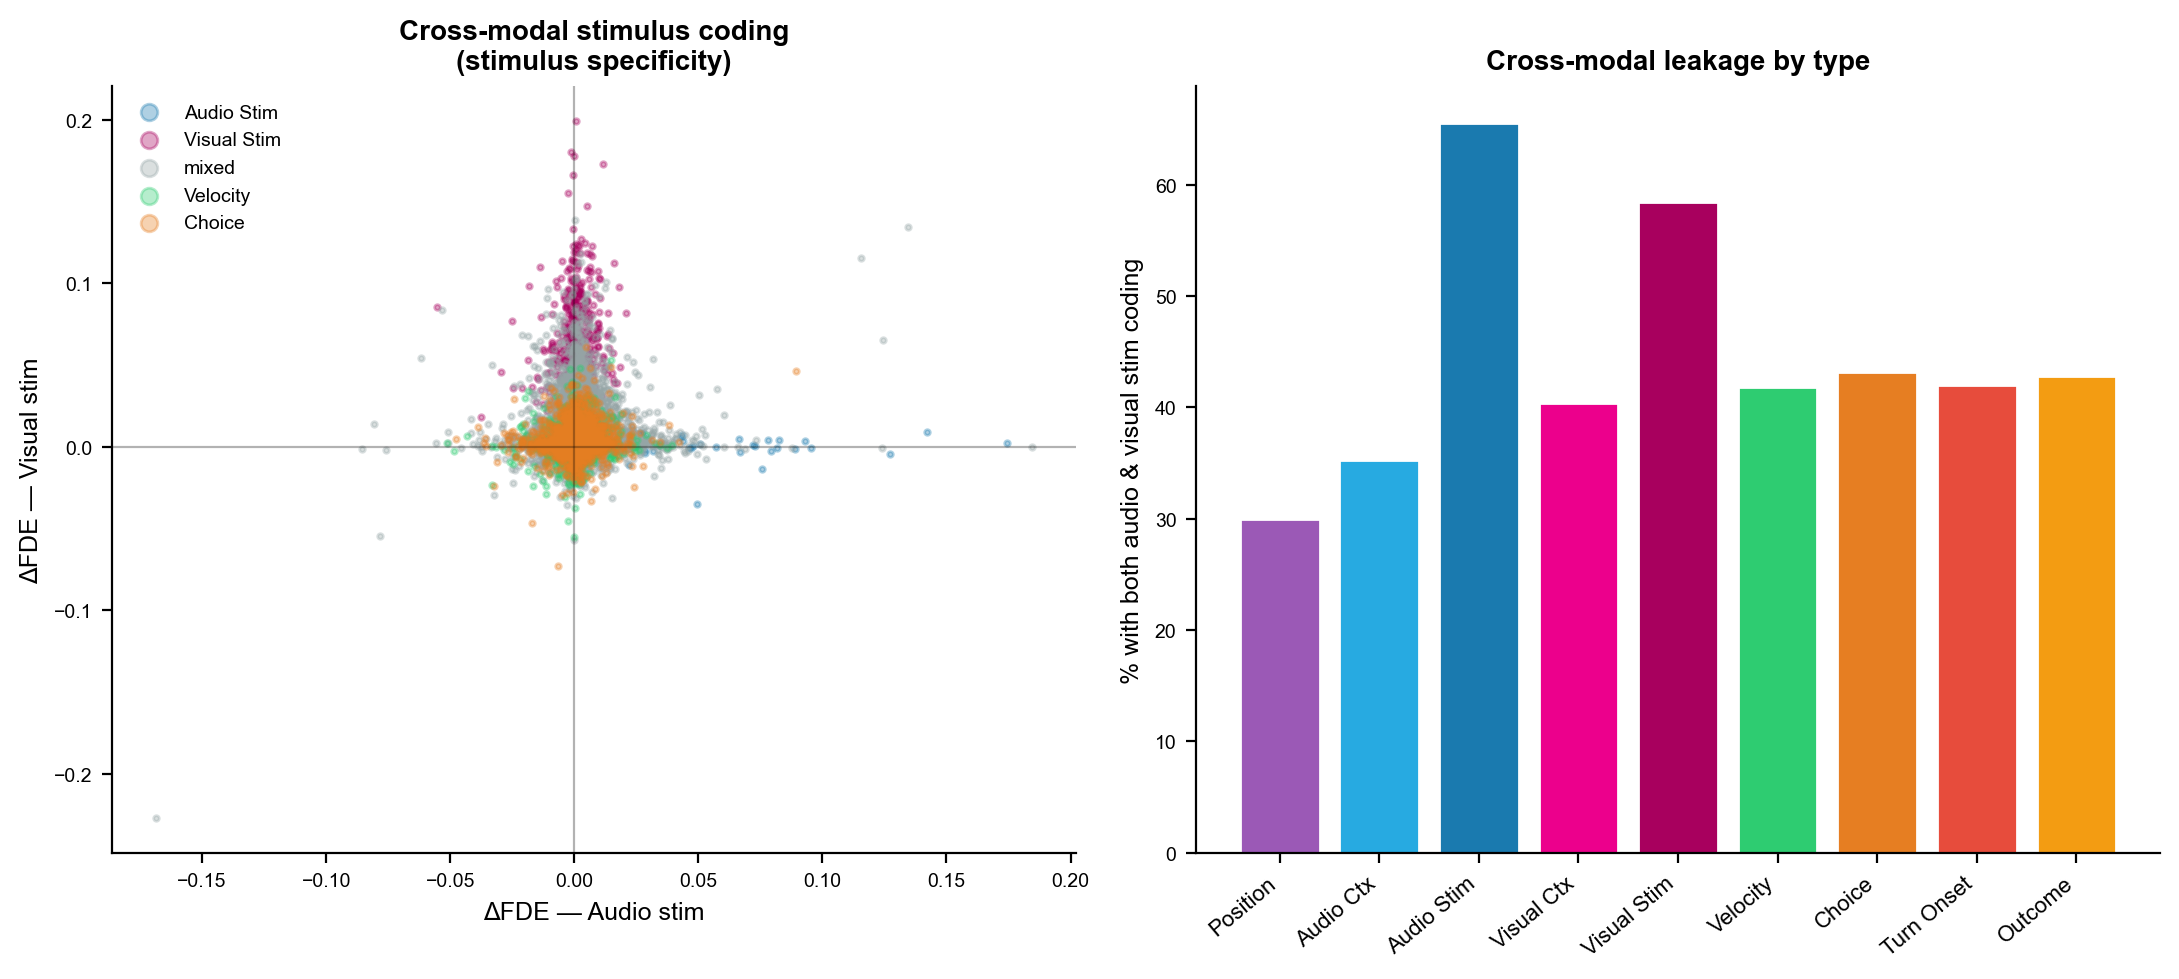

In [35]:
# ── 2d. Stimulus coding specificity — cross-modal leakage ─────────────────────
if 'delta_fd_audio_stim' in df_resp.columns and 'delta_fd_visual_stim' in df_resp.columns:
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))

    # Scatter: audio_stim vs visual_stim delta_FDE
    ax = axes[0]
    for cls in ['audio_stim','visual_stim','mixed','velocity','choice_spatial']:
        sub = df_resp[df_resp['neuron_class']==cls] if cls in df_resp['neuron_class'].values else pd.DataFrame()
        if len(sub)==0: continue
        ax.scatter(sub['delta_fd_audio_stim'], sub['delta_fd_visual_stim'],
                   s=4, alpha=0.35, color=CLASS_COLORS.get(cls,'gray'),
                   label=GROUP_LABELS.get(cls,cls))
    ax.axhline(0,color='k',lw=0.8,alpha=0.3); ax.axvline(0,color='k',lw=0.8,alpha=0.3)
    ax.set_xlabel('ΔFDE — Audio stim', fontsize=9)
    ax.set_ylabel('ΔFDE — Visual stim', fontsize=9)
    ax.set_title('Cross-modal stimulus coding\n(stimulus specificity)', fontsize=10, fontweight='bold')
    ax.legend(fontsize=7, markerscale=3, frameon=False)

    # Fraction with cross-modal leakage (both > 0)
    ax = axes[1]
    both_pos = (df_resp['delta_fd_audio_stim'] > 0) & (df_resp['delta_fd_visual_stim'] > 0)
    cross_modal_pct = []
    for g in classes_to_plot:
        sub = df_resp[df_resp['dominant_group']==g]
        cross_modal_pct.append(both_pos.loc[sub.index].mean() * 100)
    ax.bar(range(len(classes_to_plot)), cross_modal_pct,
           color=[GROUP_COLORS.get(g,'gray') for g in classes_to_plot], edgecolor='white')
    ax.set_xticks(range(len(classes_to_plot)))
    ax.set_xticklabels([GROUP_LABELS.get(g,g) for g in classes_to_plot], rotation=40, ha='right', fontsize=8)
    ax.set_ylabel('% with both audio & visual stim coding', fontsize=9)
    ax.set_title('Cross-modal leakage by type', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('Note: delta_fd_audio_stim / delta_fd_visual_stim not found — run lesions first.')

## Section 3 — Coupling Model: Population Dynamics

Neurons in both models: 51,635
Coupling gain (all):       median=+0.0302
Coupling gain (responsive): median=+0.0554
% positive gain (responsive): 98.3%


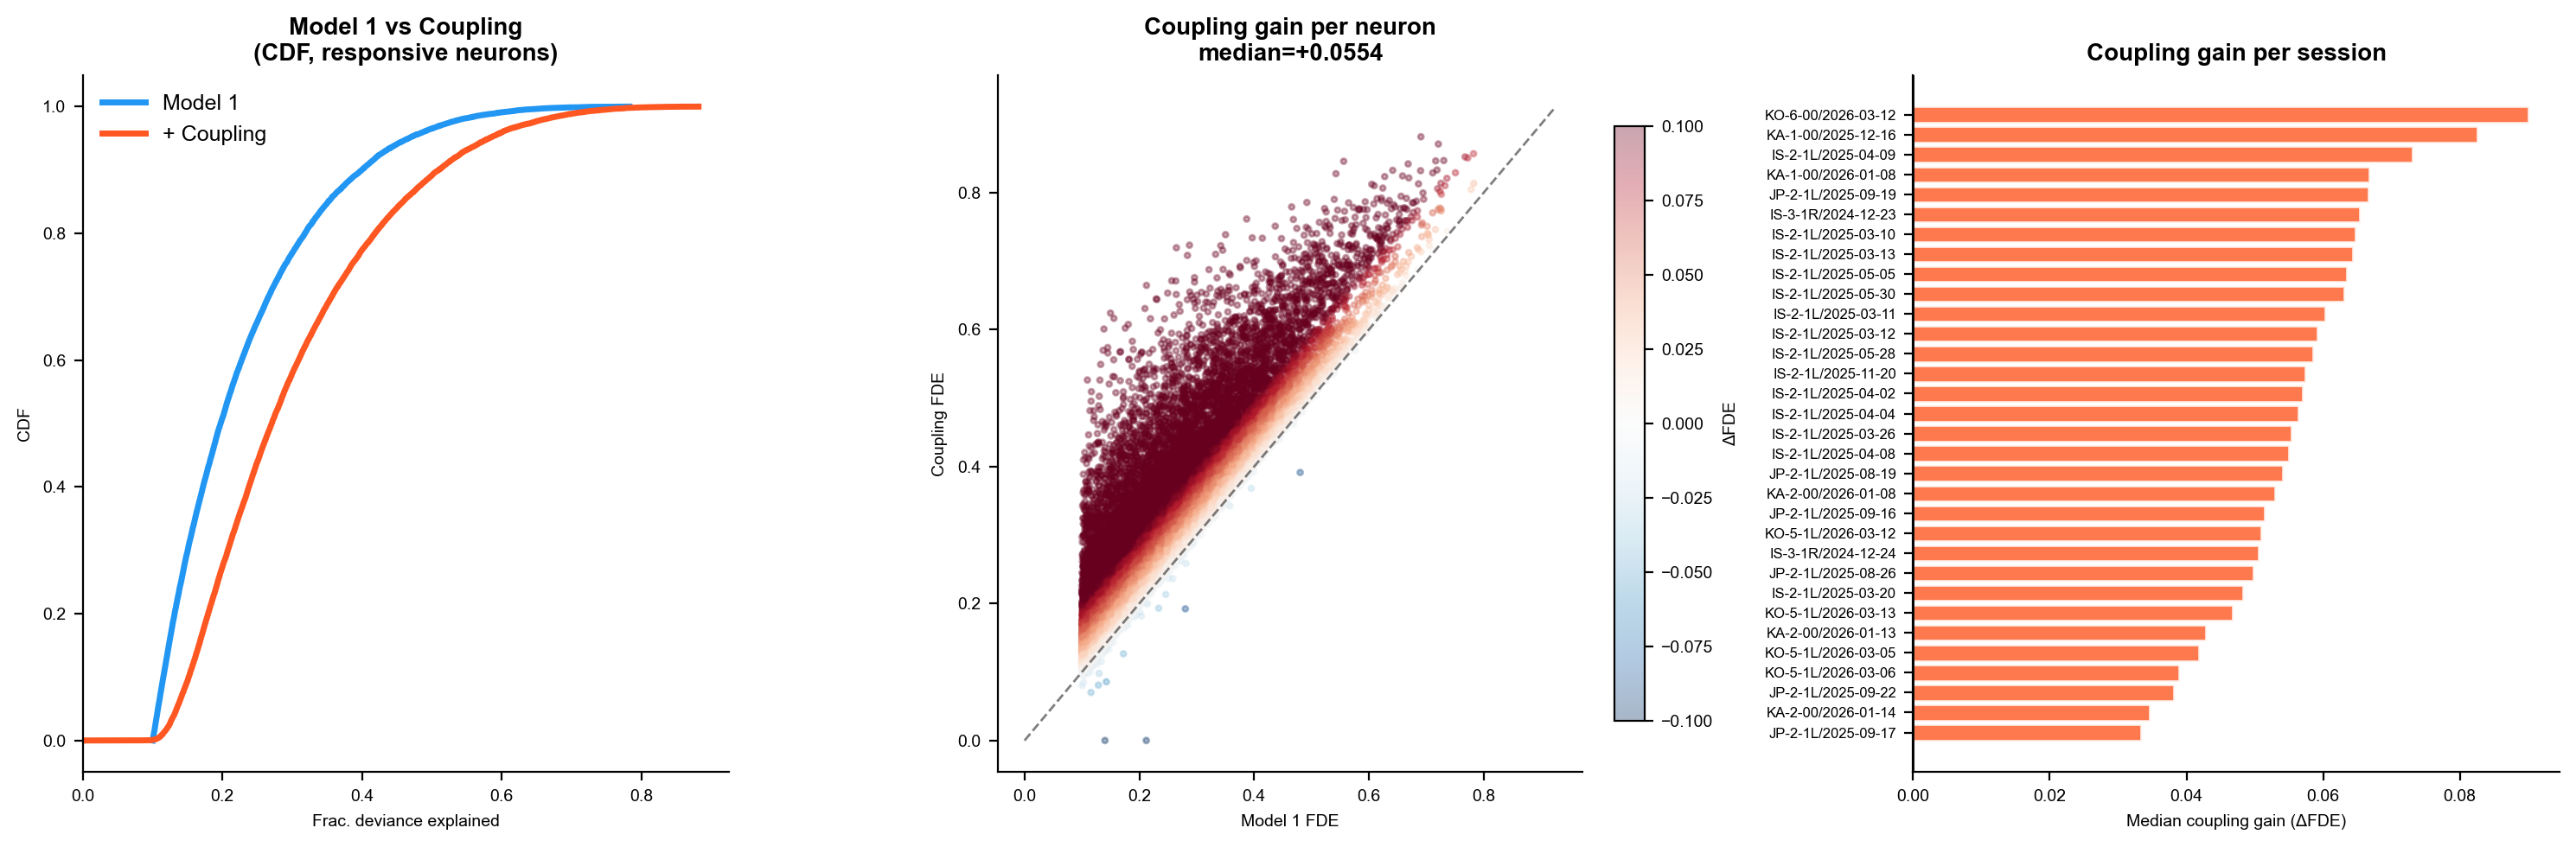

In [36]:
# ── 3a. Coupling gain overview ─────────────────────────────────────────────────
# Align neurons common to both models by session + neuron_idx
common_idx = df_m1.index.intersection(df_coup.index)
fde_m1   = df_m1.loc[common_idx, 'test_frac_dev'].values
fde_coup = df_coup.loc[common_idx, 'test_frac_dev'].values
coup_gain = fde_coup - fde_m1
resp_mask_both = df_m1.loc[common_idx, 'is_responsive'].values

print(f'Neurons in both models: {len(common_idx):,}')
print(f'Coupling gain (all):       median={np.nanmedian(coup_gain):+.4f}')
print(f'Coupling gain (responsive): median={np.nanmedian(coup_gain[resp_mask_both]):+.4f}')
print(f'% positive gain (responsive): {(coup_gain[resp_mask_both]>0).mean()*100:.1f}%')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# CDF comparison
ax = axes[0]
for fde, lbl, col in [(fde_m1[resp_mask_both],'Model 1','#2196F3'),
                      (fde_coup[resp_mask_both],'+ Coupling','#FF5722')]:
    x = np.sort(fde); y = np.linspace(0,1,len(x))
    ax.plot(x, y, color=col, lw=2.5, label=lbl)
ax.set_xlabel('Frac. deviance explained'); ax.set_ylabel('CDF')
ax.set_title('Model 1 vs Coupling\n(CDF, responsive neurons)', fontsize=10, fontweight='bold')
ax.legend(fontsize=9, frameon=False); ax.set_xlim(0, None)

# Scatter: M1 vs coupling FDE
ax = axes[1]
gain_clipped = np.clip(coup_gain[resp_mask_both], -0.15, 0.15)
sc = ax.scatter(fde_m1[resp_mask_both], fde_coup[resp_mask_both],
                s=5, alpha=0.35, c=gain_clipped, cmap='RdBu_r', vmin=-0.1, vmax=0.1)
lim = max(fde_m1[resp_mask_both].max(), fde_coup[resp_mask_both].max()) * 1.05
ax.plot([0,lim],[0,lim],'k--',lw=1,alpha=0.5)
ax.set_xlabel('Model 1 FDE'); ax.set_ylabel('Coupling FDE')
ax.set_title(f'Coupling gain per neuron\nmedian={np.nanmedian(coup_gain[resp_mask_both]):+.4f}',
             fontsize=10, fontweight='bold')
fig.colorbar(sc, ax=ax, label='ΔFDE', fraction=0.046)

# Per-session median gain
ax = axes[2]
df_both = df_m1.loc[common_idx, ['mouse_ID','date','is_responsive']].copy()
df_both['coup_gain'] = coup_gain
sess_gain = df_both[df_both['is_responsive']].groupby(['mouse_ID','date'])['coup_gain'].median().reset_index()
sess_gain_sorted = sess_gain.sort_values('coup_gain')
colors_sess = [CTX_COLORS.get(0,'gray')]*len(sess_gain_sorted)
ax.barh(range(len(sess_gain_sorted)), sess_gain_sorted['coup_gain'], color='#FF5722', alpha=0.8, edgecolor='white')
ax.set_yticks(range(len(sess_gain_sorted)))
ax.set_yticklabels([f"{r['mouse_ID']}/{r['date']}" for _, r in sess_gain_sorted.iterrows()], fontsize=6)
ax.axvline(0, color='k', lw=1)
ax.set_xlabel('Median coupling gain (ΔFDE)'); ax.set_title('Coupling gain per session', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

         class  median_gain  pct_positive     n
 audio_context     0.021935     91.176471    34
    audio_stim     0.017140    100.000000    40
visual_context     0.013813     93.201754   456
   visual_stim     0.018097     93.039049   589
      velocity     0.060388     99.319172  3672
choice_spatial     0.039173     97.278107  2535
    turn_onset     0.088457     99.800399  1002
       outcome     0.064190     99.305302  2735
         mixed     0.056645     98.261468 11619


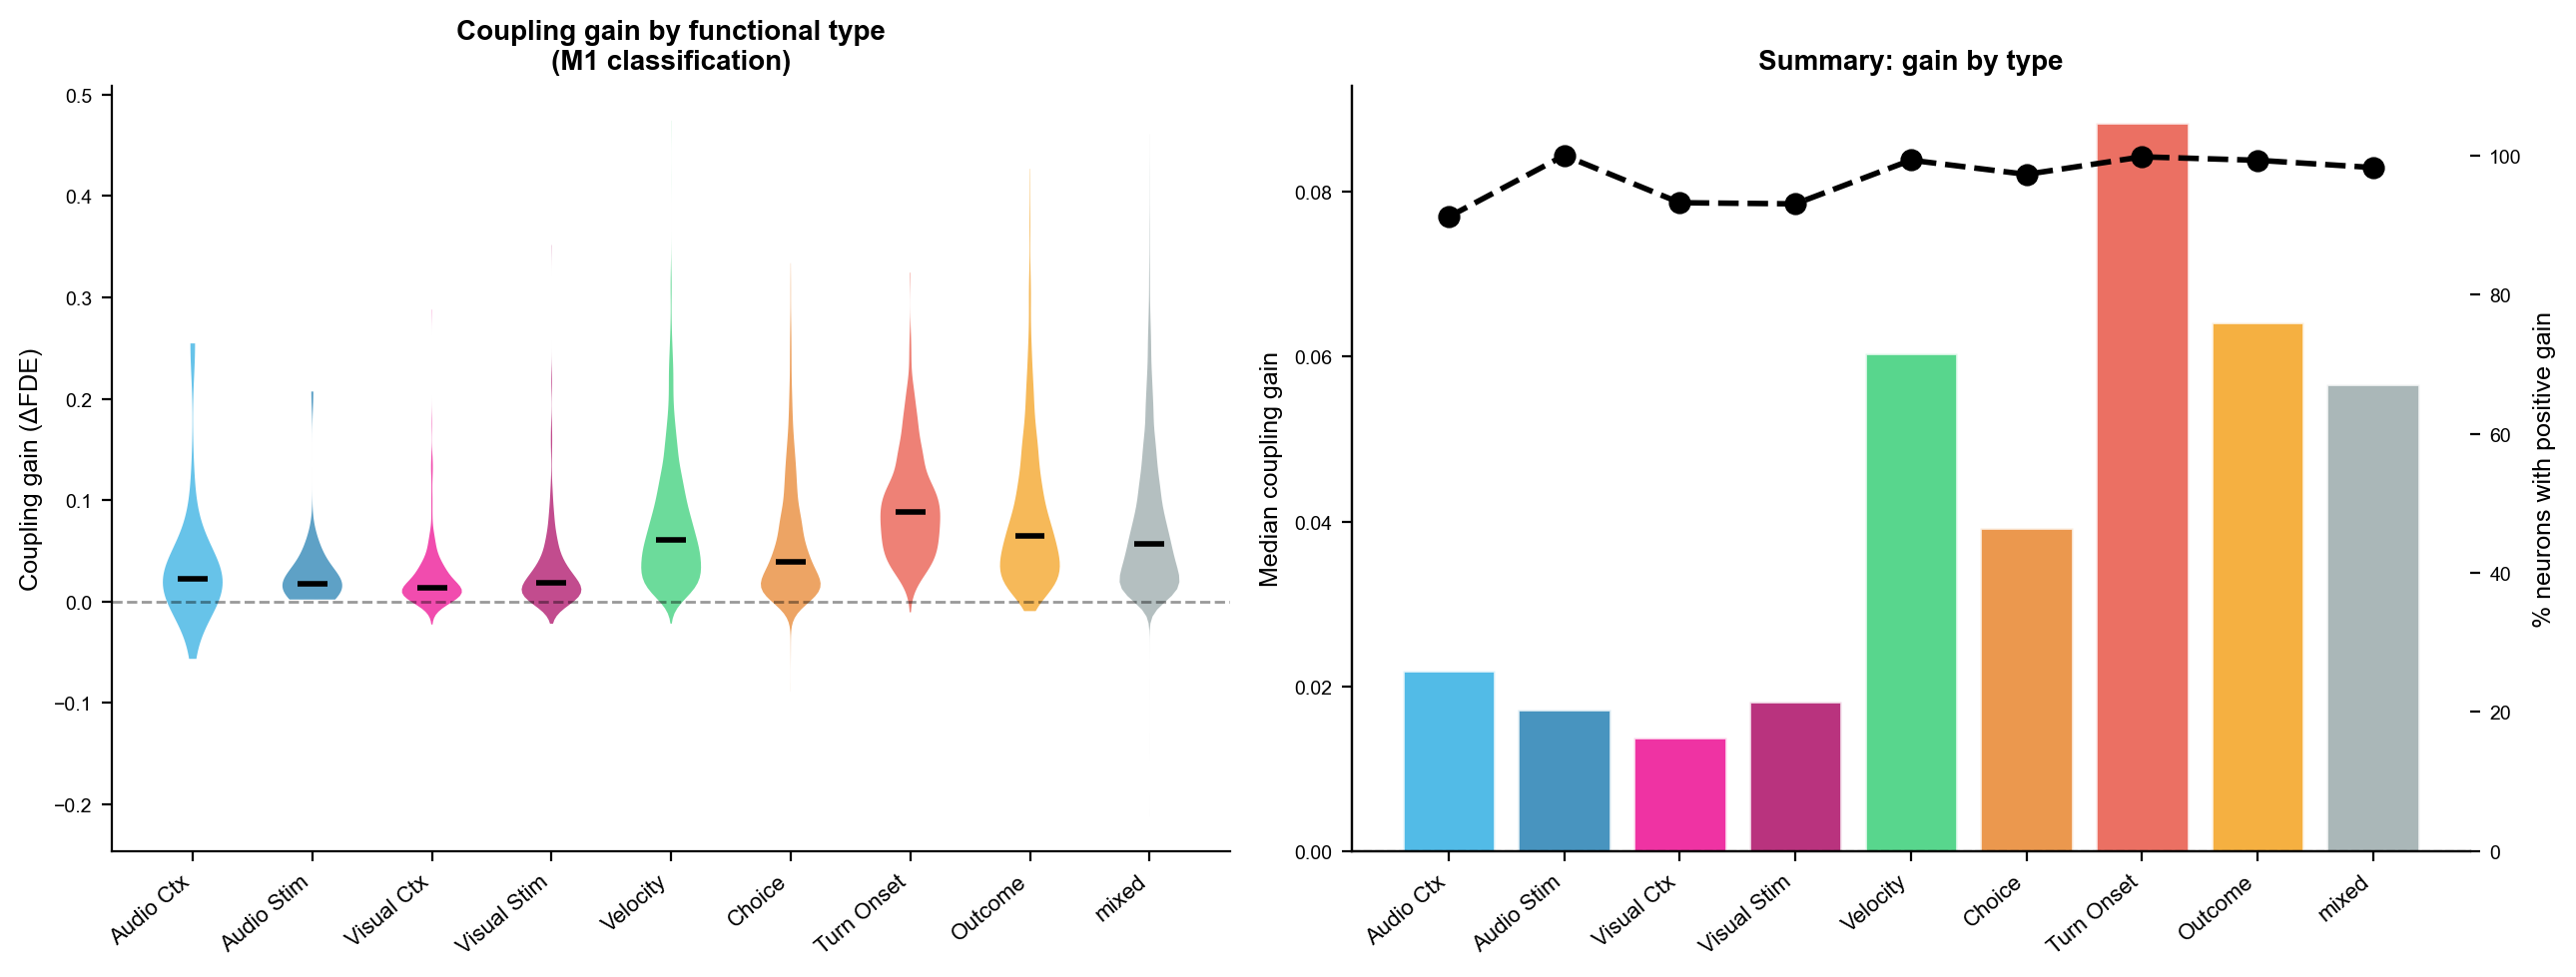

In [37]:
# ── 3b. Coupling gain by functional type (M1 classification) ──────────────────
df_both = df_m1.loc[common_idx].copy()
df_both['coup_gain'] = coup_gain
df_both['fde_coup']  = fde_coup

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Build filtered lists — skip any class with fewer than 5 responsive neurons
MIN_N = 5
cls_candidates = [g for g in M1_GROUPS if g in df_both['dominant_group'].values] + ['mixed']
data_by_type = []
cls_present  = []
for c in cls_candidates:
    d = df_both[(df_both['neuron_class'] == c) & df_both['is_responsive']]['coup_gain'].dropna().values
    if len(d) >= MIN_N:
        data_by_type.append(d)
        cls_present.append(c)

# Violin: gain distribution by type
ax = axes[0]
vp = ax.violinplot(data_by_type, positions=range(len(cls_present)),
                   showmedians=True, showextrema=False)
for pc, c in zip(vp['bodies'], cls_present):
    pc.set_facecolor(CLASS_COLORS.get(c, 'gray'))
    pc.set_alpha(0.7)
vp['cmedians'].set_color('black')
vp['cmedians'].set_linewidth(2)
ax.axhline(0, color='k', lw=1, ls='--', alpha=0.4)
ax.set_xticks(range(len(cls_present)))
ax.set_xticklabels([GROUP_LABELS.get(c, c) for c in cls_present],
                   rotation=40, ha='right', fontsize=8)
ax.set_ylabel('Coupling gain (ΔFDE)', fontsize=9)
ax.set_title('Coupling gain by functional type\n(M1 classification)', fontsize=10, fontweight='bold')

# Bar: % positive gain + median gain per type
ax = axes[1]
summary = []
for c in cls_present:
    sub = df_both[(df_both['neuron_class'] == c) & df_both['is_responsive']]['coup_gain'].dropna()
    summary.append((c, np.nanmedian(sub), (sub > 0).mean() * 100, len(sub)))
summary_df = pd.DataFrame(summary, columns=['class', 'median_gain', 'pct_positive', 'n'])

x   = np.arange(len(summary_df))
ax2 = ax.twinx()
ax.bar(x, summary_df['median_gain'],
       color=[CLASS_COLORS.get(c, 'gray') for c in cls_present],
       alpha=0.8, edgecolor='white')
ax2.plot(x, summary_df['pct_positive'], 'ko--', ms=7, lw=2)
ax.set_xticks(x)
ax.set_xticklabels([GROUP_LABELS.get(c, c) for c in cls_present],
                   rotation=40, ha='right', fontsize=8)
ax.set_ylabel('Median coupling gain', fontsize=9)
ax2.set_ylabel('% neurons with positive gain', fontsize=9)
ax2.set_ylim(0, 110)
ax.axhline(0, color='k', lw=0.8, ls='--', alpha=0.4)
ax.set_title('Summary: gain by type', fontsize=10, fontweight='bold')

print(summary_df.to_string(index=False))
plt.tight_layout()
plt.show()

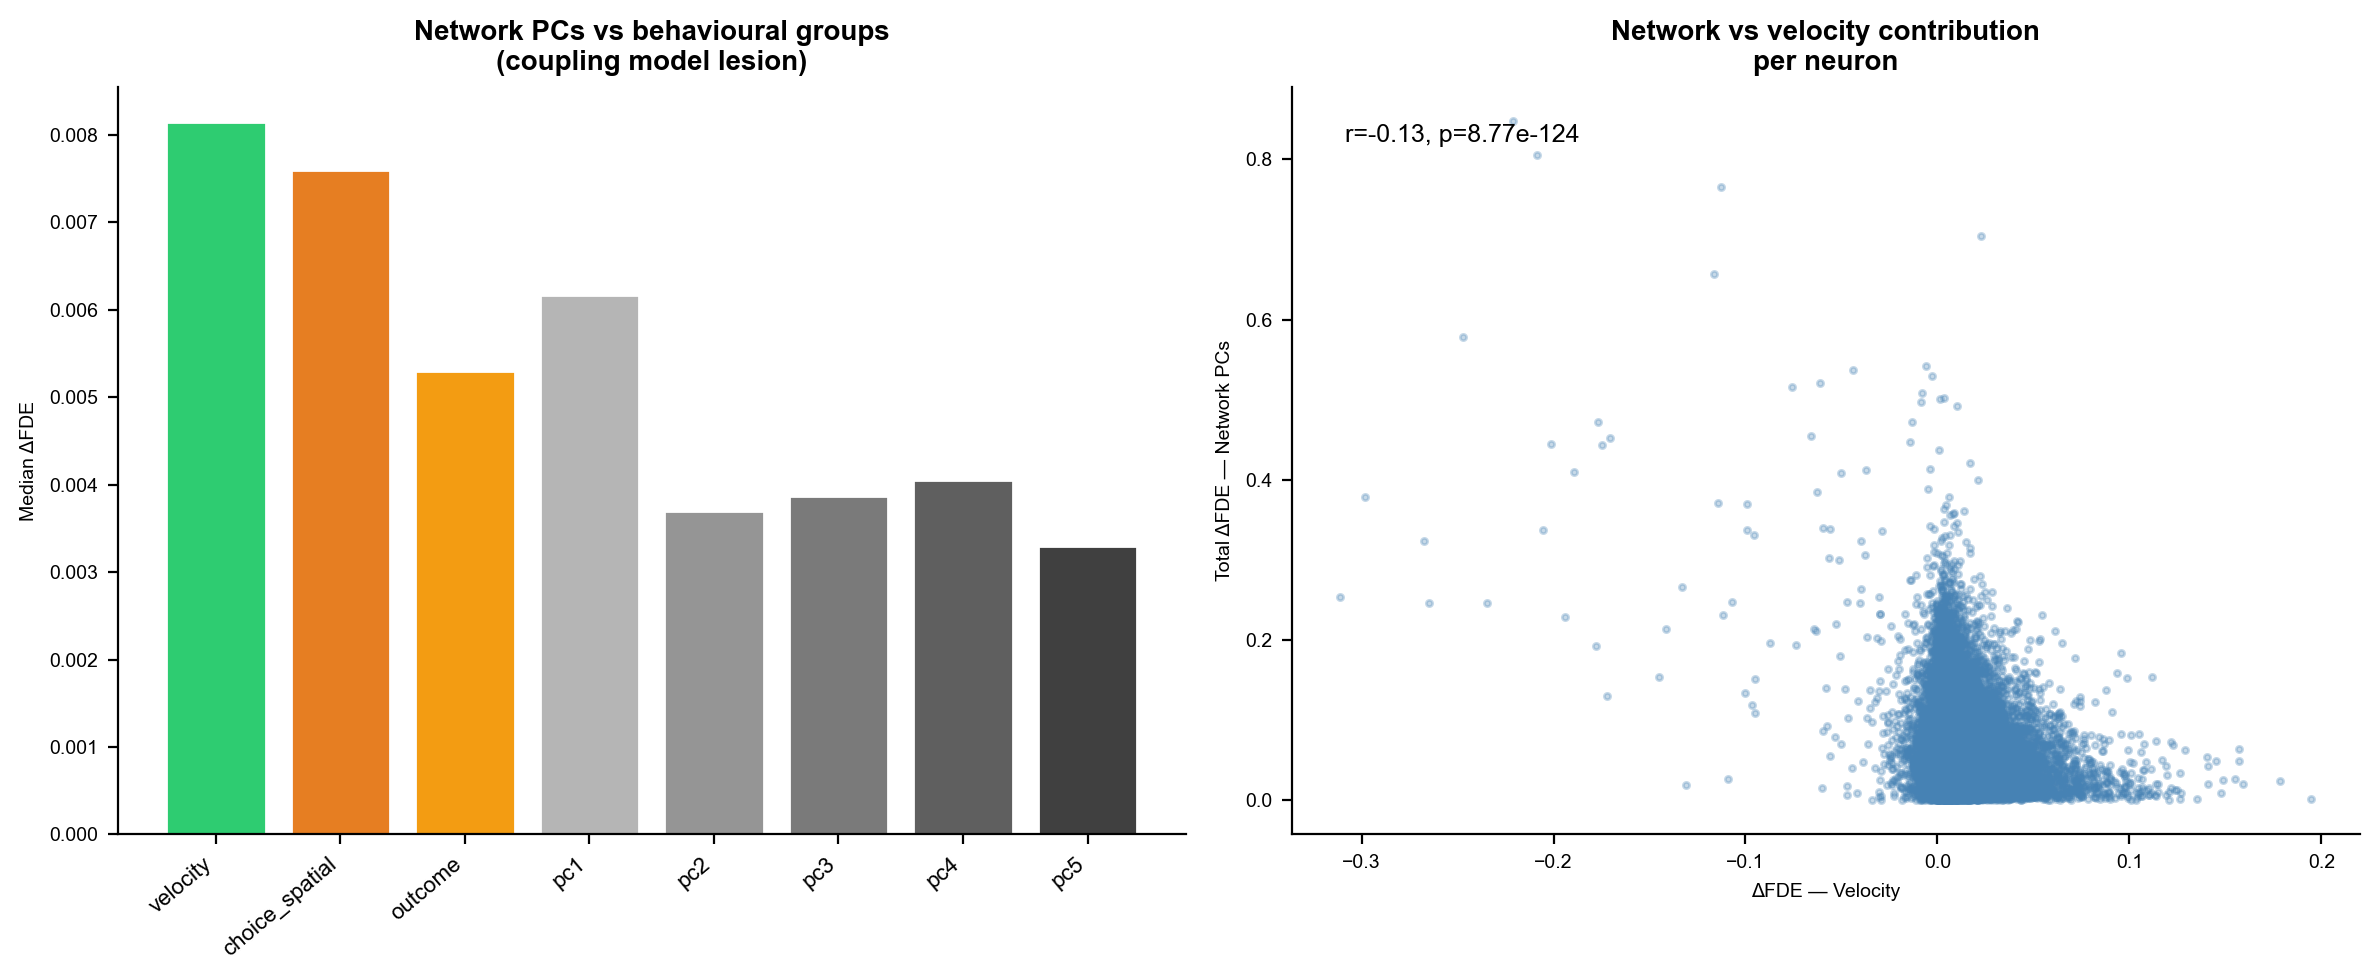

In [38]:
# ── 3c. Coupling lesion contribution (network PCs) ────────────────────────────
pc_cols = [f'delta_fd_network_pc{i+1}' for i in range(5) if f'delta_fd_network_pc{i+1}' in df_coup.columns]
if pc_cols:
    df_coup_resp = df_coup[resp_coup].copy()
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Bar: median delta_FDE per PC vs top behavioral groups
    ax = axes[0]
    beh_cols = [f'delta_fd_{g}' for g in ['velocity','choice_spatial','outcome'] if f'delta_fd_{g}' in df_coup_resp.columns]
    all_compare_cols = beh_cols + pc_cols
    compare_labels = [c.replace('delta_fd_','').replace('network_','') for c in all_compare_cols]
    compare_colors = [GROUP_COLORS.get(c.replace('delta_fd_',''),'#999999') for c in all_compare_cols]
    medians_c = [df_coup_resp[c].median() for c in all_compare_cols]
    ax.bar(range(len(all_compare_cols)), medians_c, color=compare_colors, edgecolor='white')
    ax.set_xticks(range(len(all_compare_cols)))
    ax.set_xticklabels(compare_labels, rotation=40, ha='right', fontsize=8)
    ax.set_ylabel('Median ΔFDE'); ax.set_title('Network PCs vs behavioural groups\n(coupling model lesion)', fontsize=10, fontweight='bold')

    # Scatter: total network contribution vs velocity
    ax = axes[1]
    total_net = df_coup_resp[pc_cols].clip(lower=0).sum(axis=1)
    vel_col = 'delta_fd_velocity'
    if vel_col in df_coup_resp.columns:
        ax.scatter(df_coup_resp[vel_col], total_net, s=5, alpha=0.3, color='steelblue')
        ax.set_xlabel('ΔFDE — Velocity'); ax.set_ylabel('Total ΔFDE — Network PCs')
        ax.set_title('Network vs velocity contribution\nper neuron', fontsize=10, fontweight='bold')
        r, p = stats.spearmanr(df_coup_resp[vel_col], total_net, nan_policy='omit')
        ax.text(0.05, 0.95, f'r={r:.2f}, p={p:.2e}', transform=ax.transAxes, fontsize=9,
                verticalalignment='top')
    plt.tight_layout()
    plt.show()
else:
    print('Coupling lesion results not yet available.')

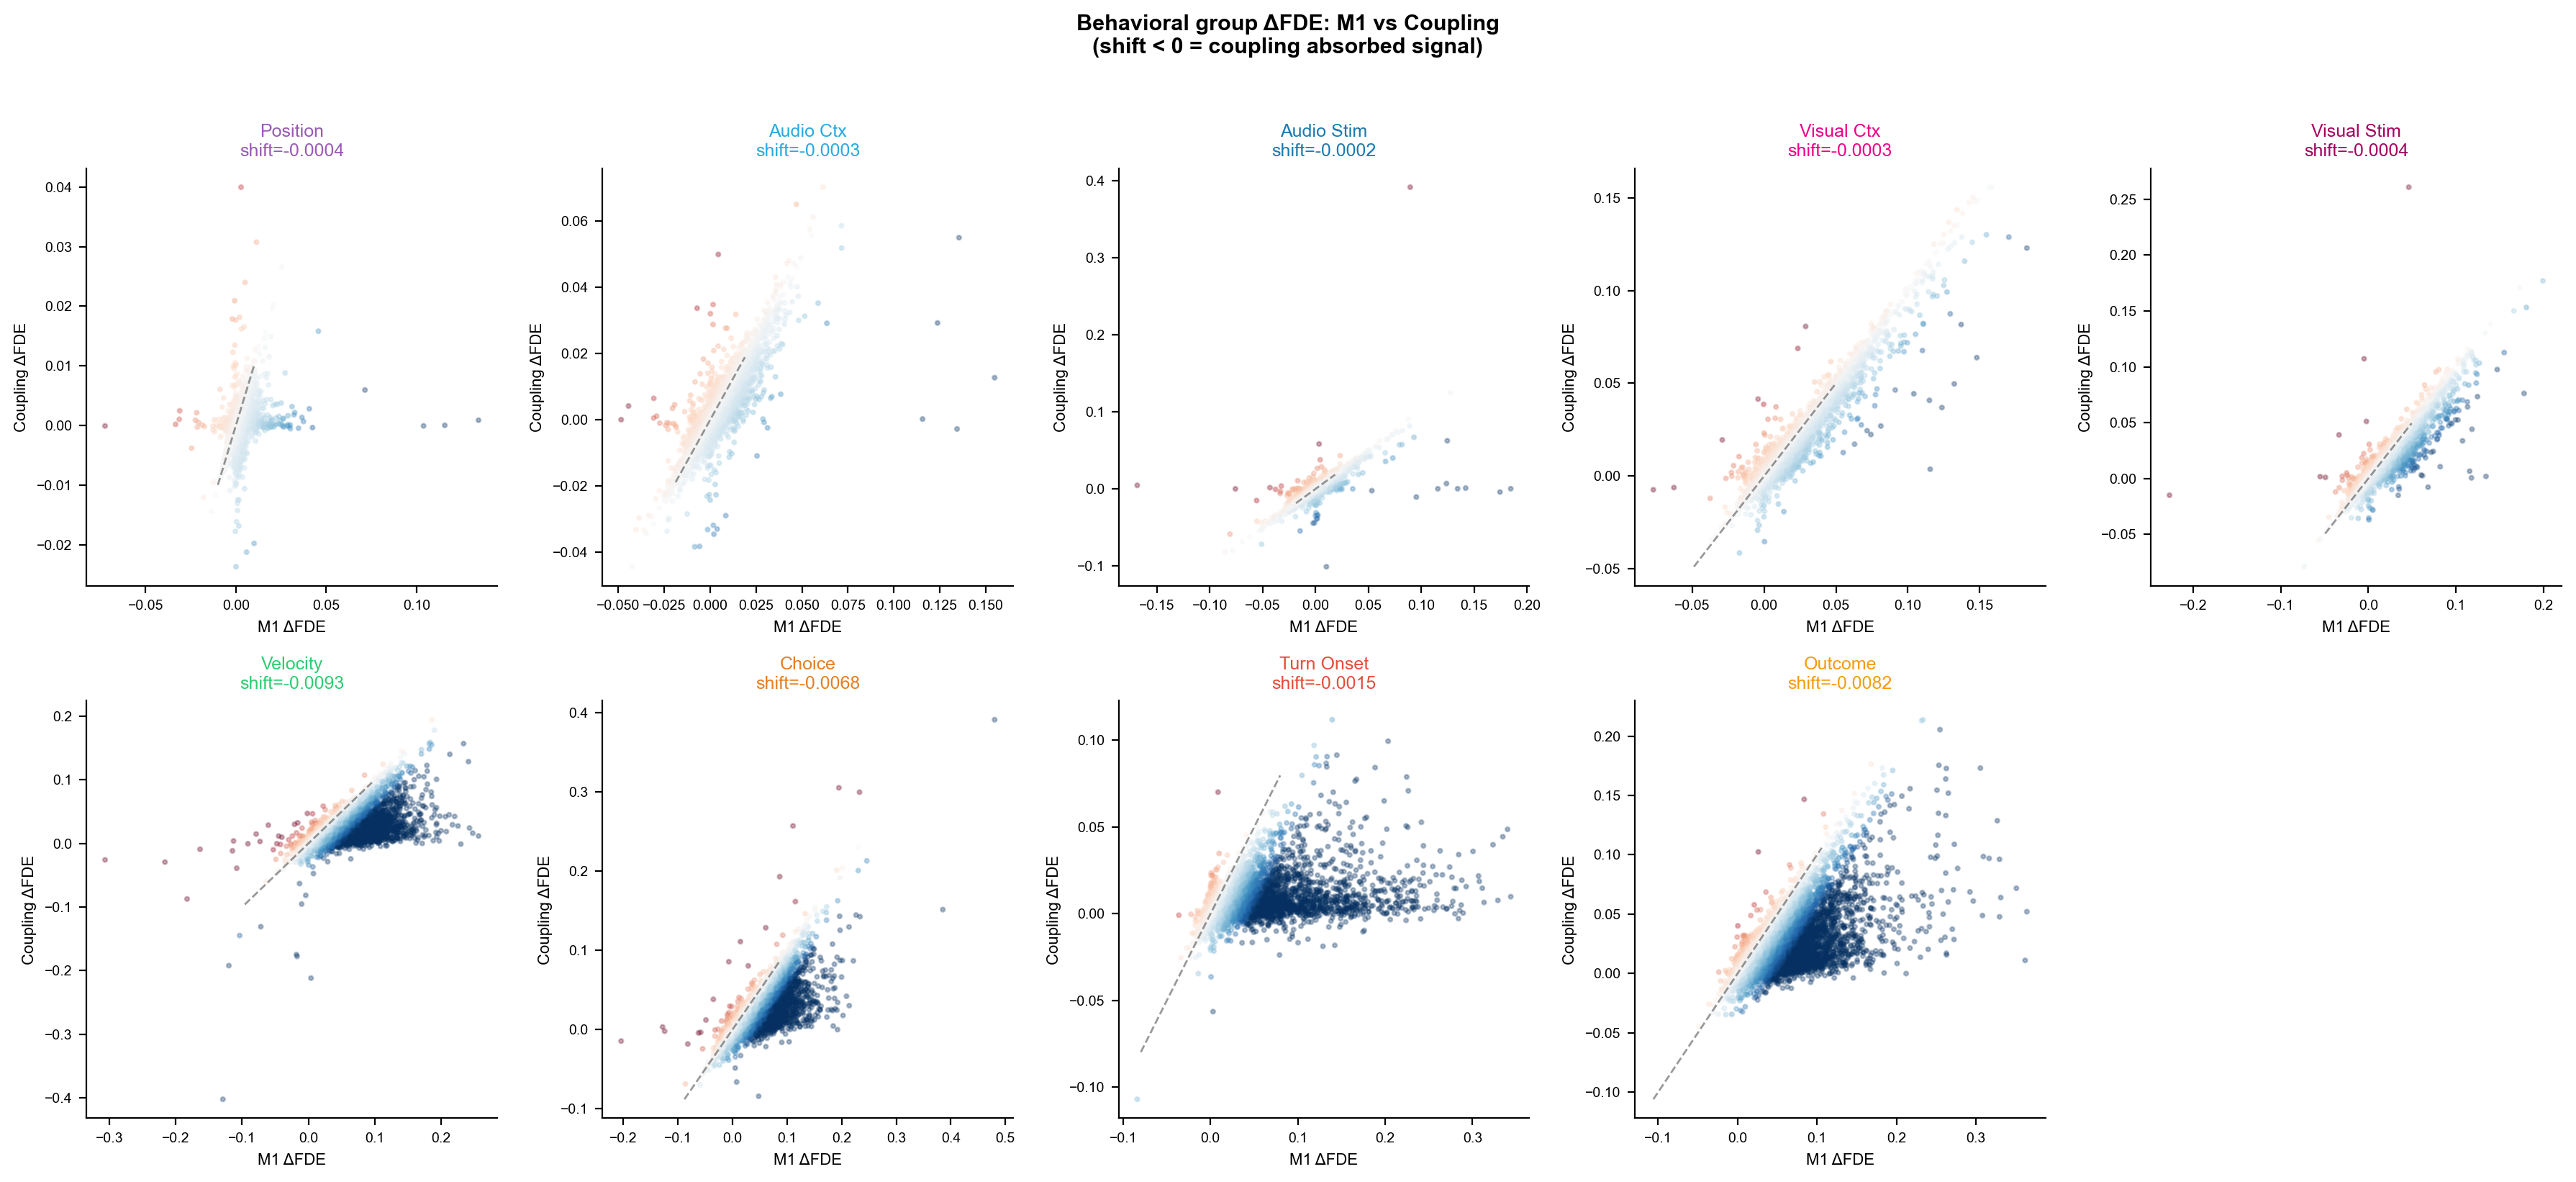


Substitution summary:
         group  median_shift  pct_decrease
 position_only     -0.000383     69.423847
 audio_context     -0.000315     60.005966
    audio_stim     -0.000167     57.704764
visual_context     -0.000345     60.138072
   visual_stim     -0.000390     61.881019
      velocity     -0.009272     86.635984
choice_spatial     -0.006809     85.983977
    turn_onset     -0.001535     75.411233
       outcome     -0.008249     87.658740


In [39]:
# ── 3d. Does coupling substitute behavioral coding? ───────────────────────────
# Compare delta_FDE for each behavioral group between M1 and coupling model
beh_groups_both = [g for g in M1_GROUPS
                   if f'delta_fd_{g}' in df_m1.columns and f'delta_fd_{g}' in df_coup.columns]

if beh_groups_both:
    fig, axes = plt.subplots(2, len(beh_groups_both)//2 + 1, figsize=(18, 8))
    axes = axes.flatten()

    subst_summary = []
    for i, g in enumerate(beh_groups_both):
        ax = axes[i]
        col = f'delta_fd_{g}'
        shared = df_m1.index.intersection(df_coup.index)
        x = df_m1.loc[shared, col].values
        y = df_coup.loc[shared, col].values
        resp = df_m1.loc[shared, 'is_responsive'].values
        delta = y[resp] - x[resp]
        subst_summary.append({'group': g, 'median_shift': np.nanmedian(delta),
                               'pct_decrease': (delta < 0).mean()*100})

        ax.scatter(x[resp], y[resp], s=4, alpha=0.3,
                   c=np.clip(delta,-0.05,0.05), cmap='RdBu_r', vmin=-0.05, vmax=0.05)
        lim = max(np.nanpercentile(np.abs(np.concatenate([x[resp],y[resp]])), 98), 0.01)
        ax.plot([-lim,lim],[-lim,lim],'k--',lw=1,alpha=0.4)
        ax.set_xlabel('M1 ΔFDE', fontsize=8); ax.set_ylabel('Coupling ΔFDE', fontsize=8)
        ax.set_title(f'{GROUP_LABELS.get(g,g)}\nshift={np.nanmedian(delta):+.4f}',
                     fontsize=9, color=GROUP_COLORS.get(g,'black'))
    for ax in axes[len(beh_groups_both):]:
        ax.axis('off')

    plt.suptitle('Behavioral group ΔFDE: M1 vs Coupling\n(shift < 0 = coupling absorbed signal)',
                 fontsize=11, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

    print('\nSubstitution summary:')
    print(pd.DataFrame(subst_summary).to_string(index=False))
else:
    print('Need lesion results for both models.')

## Section 4 — Coupling × Context

CG vs Visual: p=1.932e-02
CG vs Audio:  p=1.499e-13
Visual vs Audio: p=7.073e-11


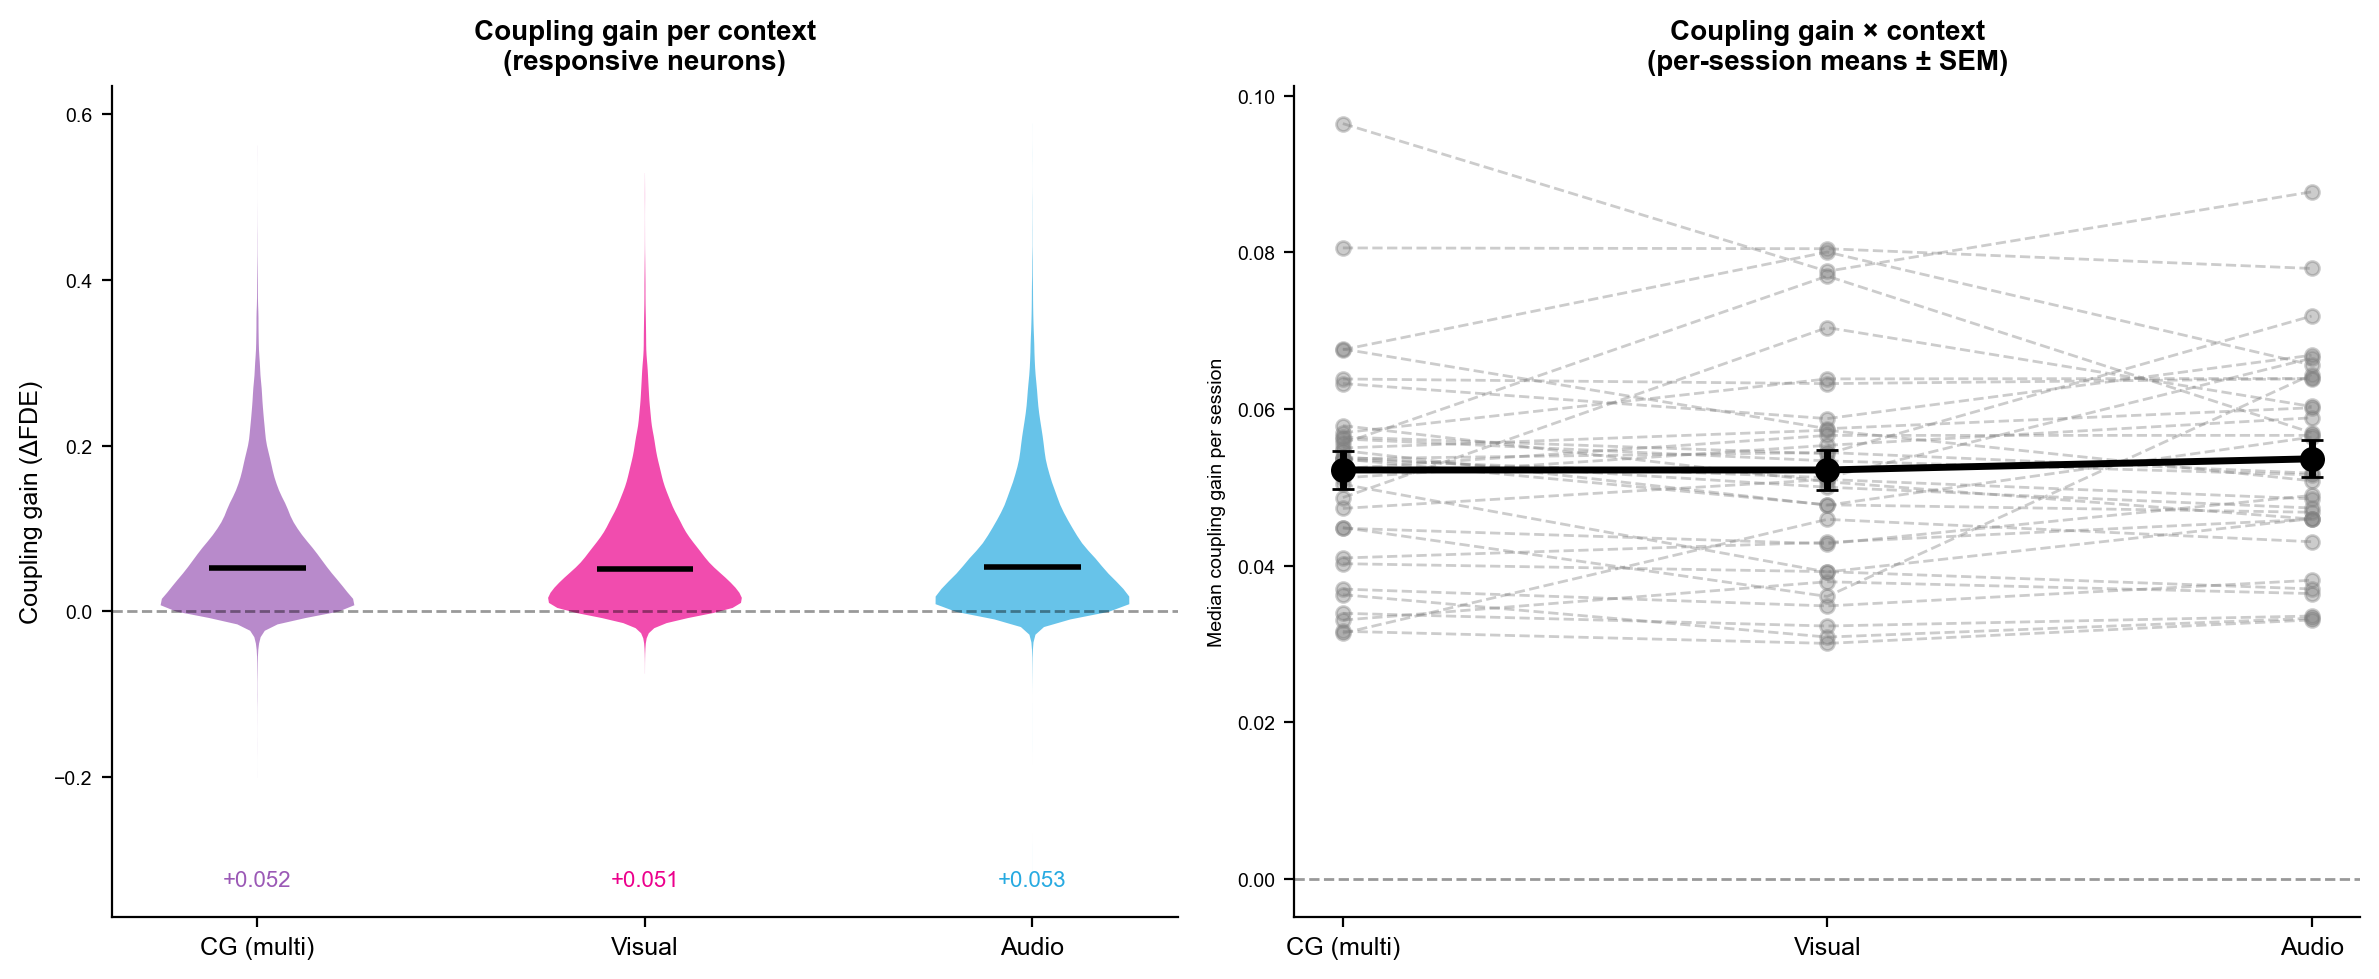

In [40]:
# ── 4a. Coupling gain per context ─────────────────────────────────────────────
if common_idx is not None and len(common_idx) > 0:
    gain_per_ctx = {}
    for ctx_key, ctx_col in [('cg','frac_dev_cg'),('visual','frac_dev_visual'),('audio','frac_dev_audio')]:
        if ctx_col in df_m1.columns and ctx_col in df_coup.columns:
            gain_per_ctx[ctx_key] = df_coup.loc[common_idx, ctx_col].values - df_m1.loc[common_idx, ctx_col].values

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Violin per context
    ax = axes[0]
    ctx_keys = list(gain_per_ctx.keys())
    data_ctx_gain = [gain_per_ctx[k][resp_mask_both] for k in ctx_keys]
    ctx_lbl_map = {'cg':'CG (multi)','visual':'Visual','audio':'Audio'}
    vp = ax.violinplot(data_ctx_gain, positions=range(len(ctx_keys)), showmedians=True, showextrema=False)
    for pc, k in zip(vp['bodies'], ctx_keys):
        pc.set_facecolor(CTX_COLORS_STR[k]); pc.set_alpha(0.7)
    vp['cmedians'].set_color('black'); vp['cmedians'].set_linewidth(2)
    ax.axhline(0, color='k', lw=1, ls='--', alpha=0.4)
    ax.set_xticks(range(len(ctx_keys)))
    ax.set_xticklabels([ctx_lbl_map[k] for k in ctx_keys], fontsize=9)
    ax.set_ylabel('Coupling gain (ΔFDE)', fontsize=9)
    ax.set_title('Coupling gain per context\n(responsive neurons)', fontsize=10, fontweight='bold')
    for i, (k, d) in enumerate(zip(ctx_keys, data_ctx_gain)):
        med = np.nanmedian(d)
        ax.text(i, ax.get_ylim()[0]*0.9, f'{med:+.3f}', ha='center', fontsize=8, color=CTX_COLORS_STR[k])

    # Stats: CG vs unisensory
    ax = axes[1]
    if 'cg' in gain_per_ctx and 'visual' in gain_per_ctx and 'audio' in gain_per_ctx:
        g_cg  = gain_per_ctx['cg'][resp_mask_both]
        g_vis = gain_per_ctx['visual'][resp_mask_both]
        g_aud = gain_per_ctx['audio'][resp_mask_both]
        _, p_cg_vis = stats.wilcoxon(g_cg, g_vis, nan_policy='omit')
        _, p_cg_aud = stats.wilcoxon(g_cg, g_aud, nan_policy='omit')
        _, p_vis_aud = stats.wilcoxon(g_vis, g_aud, nan_policy='omit')

        sess_gain_ctx = []
        df_gain = df_m1.loc[common_idx, ['mouse_ID','date','is_responsive']].copy()
        for k, g in gain_per_ctx.items():
            df_gain[f'gain_{k}'] = g
        for (m, d), sub in df_gain[df_gain['is_responsive']].groupby(['mouse_ID','date']):
            sess_gain_ctx.append({**{f'gain_{k}': sub[f'gain_{k}'].median() for k in ctx_keys},
                                   'mouse_ID': m, 'date': d})
        sg = pd.DataFrame(sess_gain_ctx)
        x = np.arange(len(ctx_keys))
        for _, row in sg.iterrows():
            ax.plot(x, [row.get(f'gain_{k}', np.nan) for k in ctx_keys],
                    'o--', color='gray', alpha=0.4, ms=5, lw=1)
        means = [sg[f'gain_{k}'].mean() for k in ctx_keys]
        sems  = [sg[f'gain_{k}'].sem()  for k in ctx_keys]
        ax.errorbar(x, means, yerr=sems, fmt='o-', color='black', ms=8, lw=2.5, capsize=4, zorder=5)
        ax.set_xticks(x)
        ax.set_xticklabels([ctx_lbl_map[k] for k in ctx_keys], fontsize=9)
        ax.set_ylabel('Median coupling gain per session')
        ax.set_title(f'Coupling gain × context\n(per-session means ± SEM)', fontsize=10, fontweight='bold')
        ax.axhline(0, color='k', lw=1, ls='--', alpha=0.4)
        print(f'CG vs Visual: p={p_cg_vis:.3e}')
        print(f'CG vs Audio:  p={p_cg_aud:.3e}')
        print(f'Visual vs Audio: p={p_vis_aud:.3e}')
    plt.tight_layout()
    plt.show()

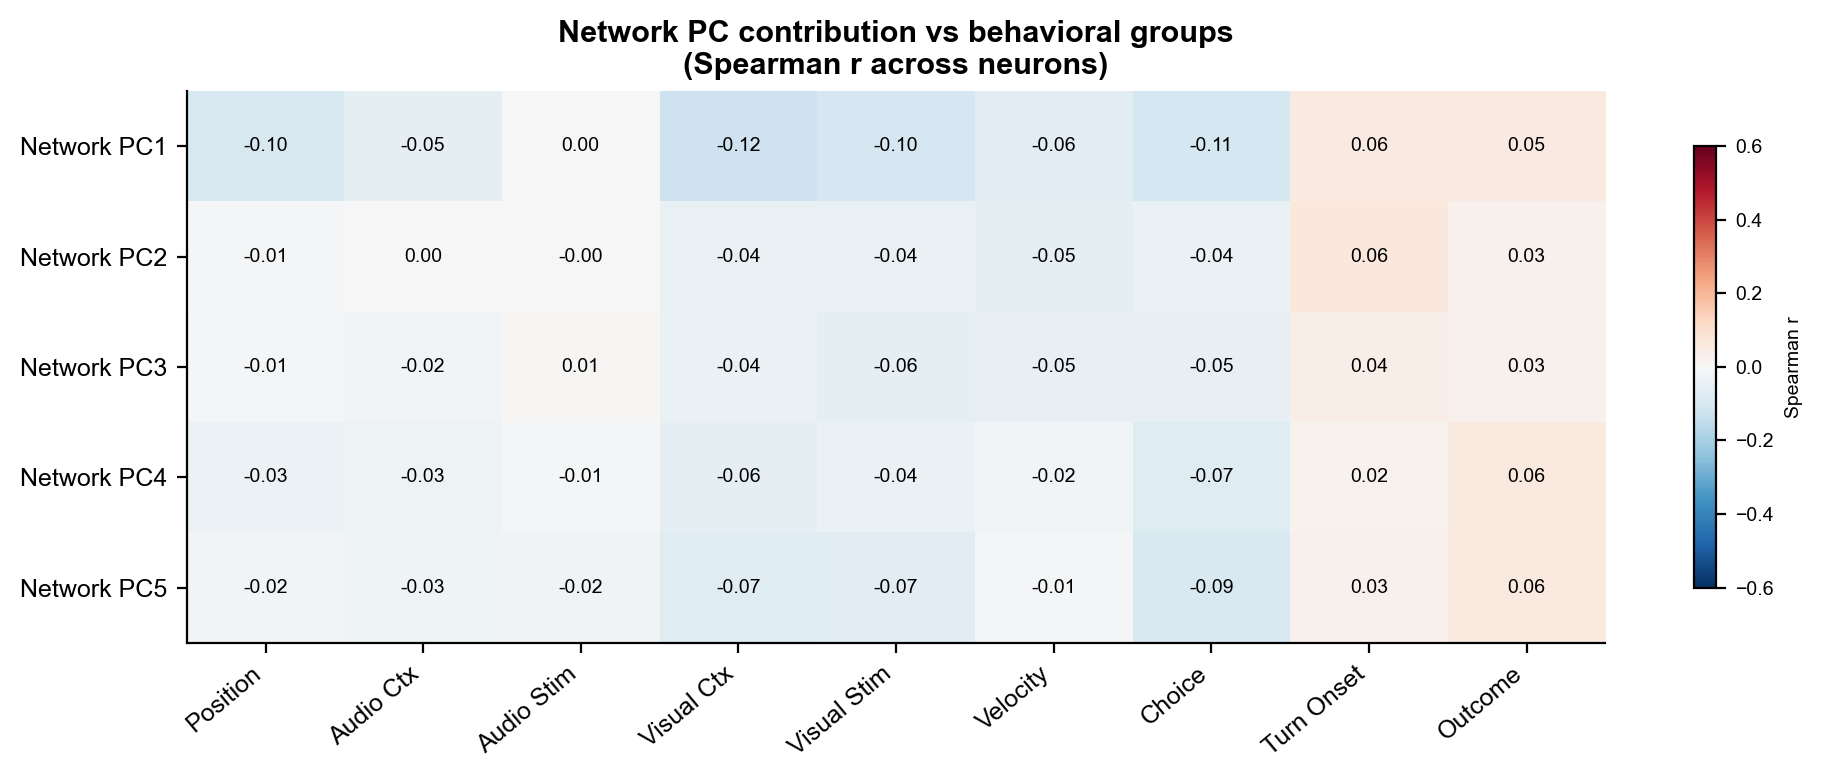

High r → network PC resembles that behavioral variable


In [41]:
# ── 4b. What does the network signal represent? ────────────────────────────────
pc_cols_available = [f'delta_fd_network_pc{i+1}' for i in range(5) if f'delta_fd_network_pc{i+1}' in df_coup.columns]
beh_delta_cols    = [f'delta_fd_{g}' for g in M1_GROUPS if f'delta_fd_{g}' in df_coup.columns]

if pc_cols_available and beh_delta_cols:
    df_cr = df_coup[resp_coup].copy()
    corr_mat = np.zeros((len(pc_cols_available), len(beh_delta_cols)))
    for i, pc_col in enumerate(pc_cols_available):
        for j, beh_col in enumerate(beh_delta_cols):
            mask = np.isfinite(df_cr[pc_col]) & np.isfinite(df_cr[beh_col])
            if mask.sum() > 10:
                r, _ = stats.spearmanr(df_cr.loc[mask, pc_col], df_cr.loc[mask, beh_col])
                corr_mat[i, j] = r

    fig, ax = plt.subplots(figsize=(10, 4))
    im = ax.imshow(corr_mat, cmap='RdBu_r', vmin=-0.6, vmax=0.6, aspect='auto')
    ax.set_xticks(range(len(beh_delta_cols)))
    ax.set_xticklabels([GROUP_LABELS.get(c.replace('delta_fd_',''),c.replace('delta_fd_',''))
                        for c in beh_delta_cols], rotation=40, ha='right', fontsize=9)
    ax.set_yticks(range(len(pc_cols_available)))
    ax.set_yticklabels([f'Network PC{i+1}' for i in range(len(pc_cols_available))], fontsize=9)
    ax.set_title('Network PC contribution vs behavioral groups\n(Spearman r across neurons)',
                 fontsize=11, fontweight='bold')
    plt.colorbar(im, ax=ax, label="Spearman r", shrink=0.8)
    for i in range(corr_mat.shape[0]):
        for j in range(corr_mat.shape[1]):
            ax.text(j, i, f'{corr_mat[i,j]:.2f}', ha='center', va='center',
                    fontsize=7, color='white' if abs(corr_mat[i,j])>0.3 else 'black')
    plt.tight_layout()
    plt.show()
    print('High r → network PC resembles that behavioral variable')
else:
    print('Coupling lesion results needed for this analysis.')

## Section 5 — Cross-Model Comparison & Summary

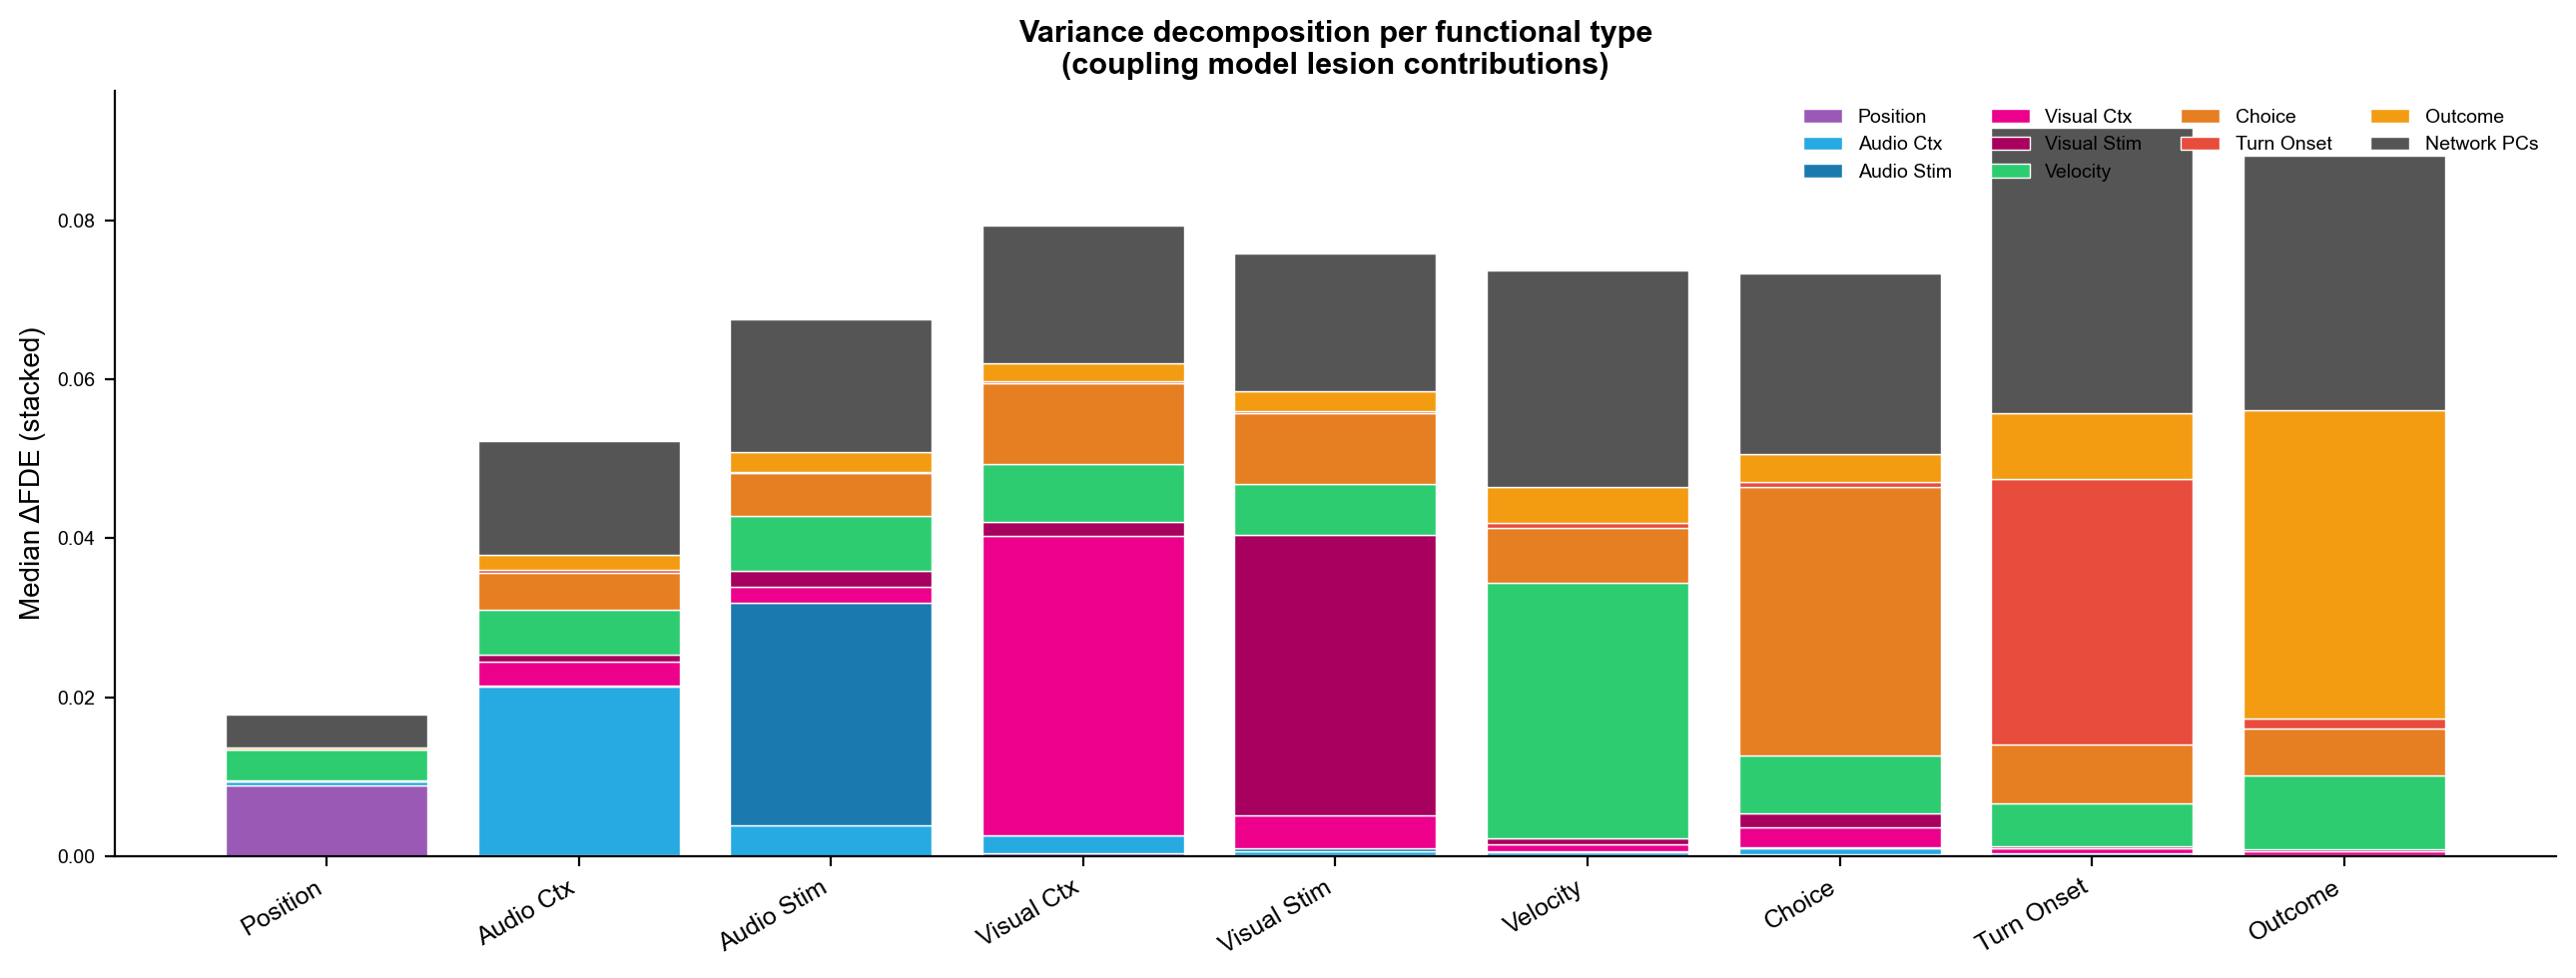

In [42]:
# ── 5a. Variance decomposition per functional type ────────────────────────────
# Stacked bar: behavioral groups + network contribution per type
# Uses coupling model delta_FDE (which includes both behavioral + PC groups)
all_groups_coup = [g for g in M1_GROUPS + [f'network_pc{i+1}' for i in range(5)]
                   if f'delta_fd_{g}' in df_coup.columns]

if all_groups_coup:
    df_cr = df_coup[resp_coup].copy()
    types_to_plot = [g for g in M1_GROUPS if g in df_cr['dominant_group'].values]

    n_pc_groups = sum(1 for g in all_groups_coup if 'network_pc' in g)
    decomp_groups = M1_GROUPS + (['network_pcs'] if n_pc_groups > 0 else [])

    fig, ax = plt.subplots(figsize=(13, 5))
    x = np.arange(len(types_to_plot))
    bottom = np.zeros(len(types_to_plot))

    for g in M1_GROUPS:
        col = f'delta_fd_{g}'
        if col not in df_cr.columns: continue
        heights = [df_cr[df_cr['dominant_group']==t][col].clip(lower=0).median() for t in types_to_plot]
        ax.bar(x, heights, bottom=bottom, color=GROUP_COLORS.get(g,'gray'),
               label=GROUP_LABELS.get(g,g), edgecolor='white', linewidth=0.5)
        bottom += np.array(heights)

    if n_pc_groups > 0:
        pc_all_cols = [f'delta_fd_network_pc{i+1}' for i in range(5) if f'delta_fd_network_pc{i+1}' in df_cr.columns]
        net_heights = [df_cr[df_cr['dominant_group']==t][pc_all_cols].clip(lower=0).sum(axis=1).median()
                       for t in types_to_plot]
        ax.bar(x, net_heights, bottom=bottom, color='#555555', label='Network PCs', edgecolor='white', linewidth=0.5)

    ax.set_xticks(x)
    ax.set_xticklabels([GROUP_LABELS.get(g,g) for g in types_to_plot], rotation=30, ha='right', fontsize=9)
    ax.set_ylabel('Median ΔFDE (stacked)', fontsize=10)
    ax.set_title('Variance decomposition per functional type\n(coupling model lesion contributions)',
                 fontsize=11, fontweight='bold')
    ax.legend(fontsize=7, frameon=False, ncol=4, loc='upper right')
    plt.tight_layout()
    plt.show()

In [43]:
# ── 5b. Neuron reclassification: M1 dominant_group → coupling dominant_group ──
shared = df_m1.index.intersection(df_coup.index)
df_reclass = pd.DataFrame({
    'm1_class':   df_m1.loc[shared, 'neuron_class'],
    'coup_class': df_coup.loc[shared, 'neuron_class'],
    'is_resp':    df_m1.loc[shared, 'is_responsive'],
})
df_reclass = df_reclass[df_reclass['is_resp']]

# Build transition matrix
all_classes = sorted(set(df_reclass['m1_class'].unique()) | set(df_reclass['coup_class'].unique()))
trans = pd.crosstab(df_reclass['m1_class'], df_reclass['coup_class'],
                    normalize='index') * 100  # % of M1 class → coupling class

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Heatmap
ax = axes[0]
sns.heatmap(trans.fillna(0), cmap='Blues', annot=True, fmt='.0f', ax=ax,
            cbar_kws={'label':'% of M1 class'}, linewidths=0.5)
ax.set_xlabel('Coupling model class', fontsize=10)
ax.set_ylabel('Model 1 class', fontsize=10)
ax.set_title('Neuron reclassification\nM1 → Coupling model (%)', fontsize=11, fontweight='bold')

# Bar: % that changed class
ax = axes[1]
changed = (df_reclass['m1_class'] != df_reclass['coup_class']).groupby(df_reclass['m1_class']).mean() * 100
changed = changed.sort_values(ascending=False)
ax.bar(range(len(changed)), changed.values,
       color=[CLASS_COLORS.get(c,'gray') for c in changed.index], edgecolor='white')
ax.set_xticks(range(len(changed)))
ax.set_xticklabels(changed.index, rotation=40, ha='right', fontsize=9)
ax.set_ylabel('% neurons that changed class', fontsize=10)
ax.set_title('Classification stability\nwhen coupling is added', fontsize=11, fontweight='bold')
print(f'Overall: {(df_reclass["m1_class"]!=df_reclass["coup_class"]).mean()*100:.1f}% of neurons change class')
plt.tight_layout()
plt.show()

TypeError: '<' not supported between instances of 'float' and 'str'

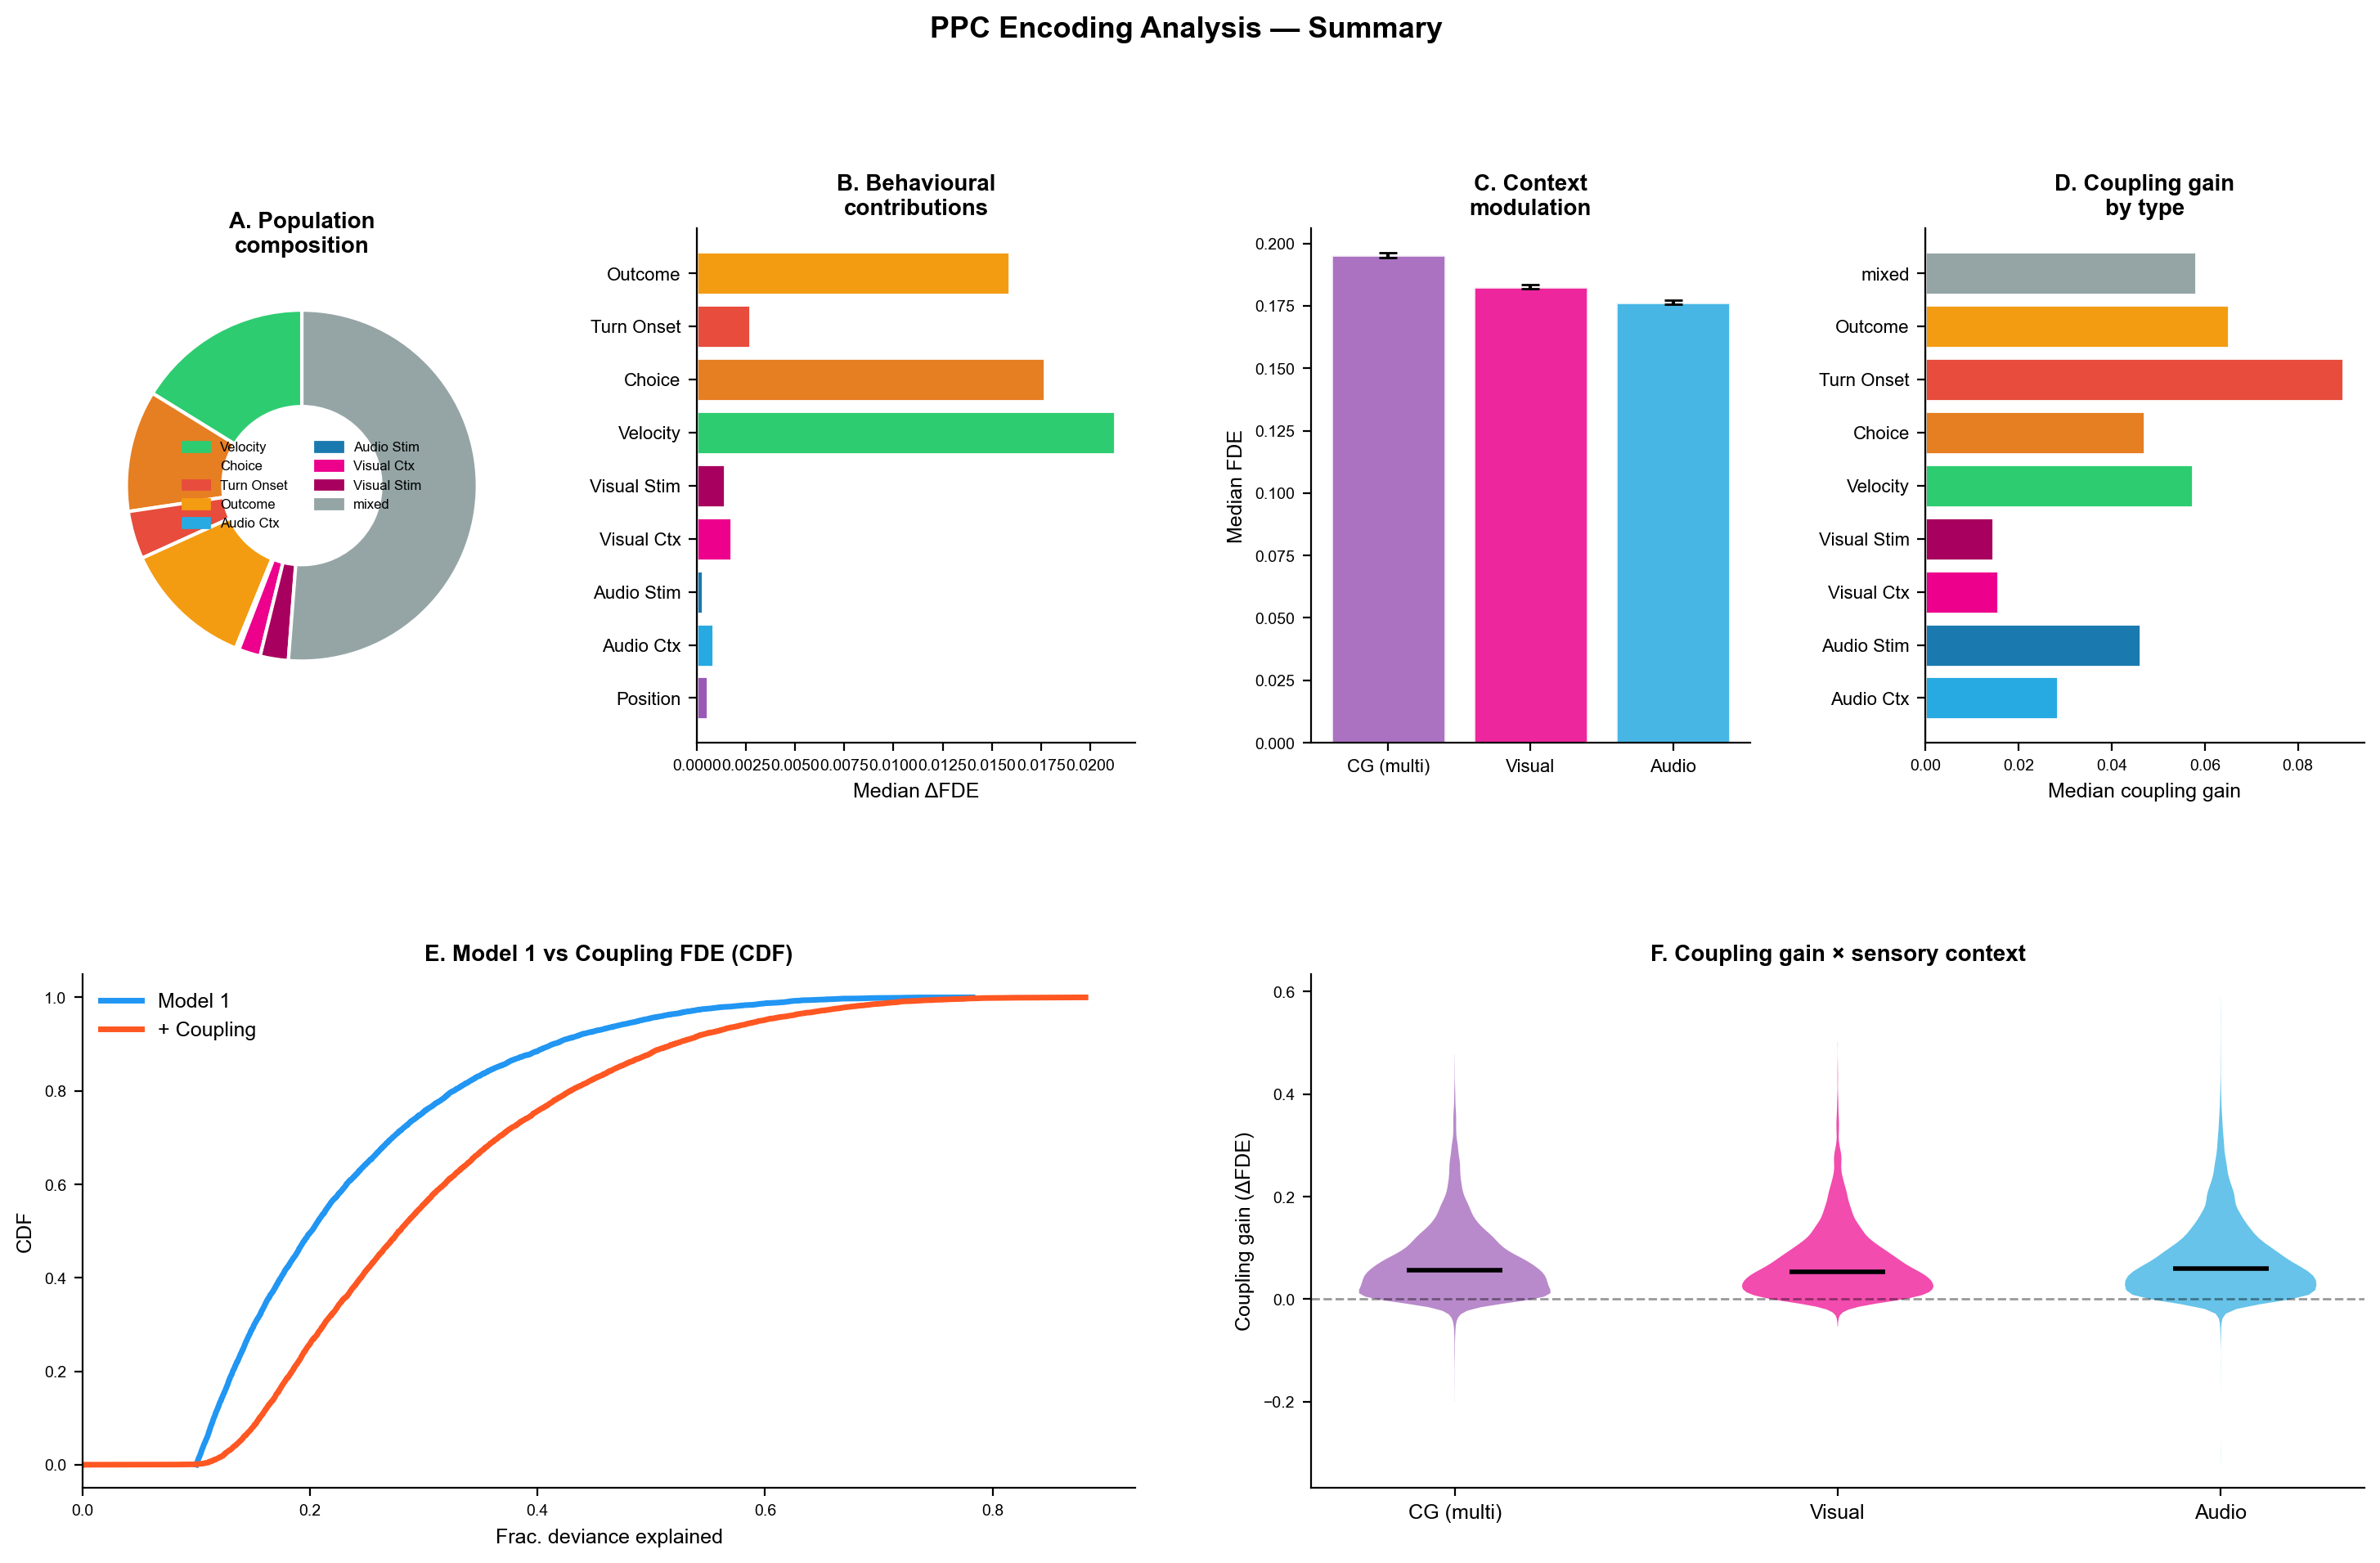

Summary figure saved → ppc_summary_figure.pdf


In [ ]:
# ── 5c. Publication summary figure ────────────────────────────────────────────
fig = plt.figure(figsize=(18, 10))
gs  = gridspec.GridSpec(2, 4, figure=fig, hspace=0.45, wspace=0.4)

# Panel A: Population composition donut
ax_a = fig.add_subplot(gs[0, 0])
counts = df_resp['neuron_class'].value_counts()
present_s = [c for c in class_order if c in counts.index]
vals_s    = [counts.get(c,0) for c in present_s]
cols_s    = [CLASS_COLORS.get(c,'gray') for c in present_s]
ax_a.pie(vals_s, colors=cols_s, startangle=90,
         wedgeprops=dict(width=0.55, edgecolor='white', linewidth=1.5))
ax_a.set_title('A. Population\ncomposition', fontsize=10, fontweight='bold')
patches = [mpatches.Patch(color=CLASS_COLORS.get(c,'gray'), label=GROUP_LABELS.get(c,c)) for c in present_s]
ax_a.legend(handles=patches, fontsize=6, loc='center', frameon=False, ncol=2)

# Panel B: Lesion contributions bar
ax_b = fig.add_subplot(gs[0, 1])
g_list2 = [g for g in M1_GROUPS if f'delta_fd_{g}' in df_resp.columns]
meds_b  = [df_resp[f'delta_fd_{g}'].median() for g in g_list2]
ax_b.barh(range(len(g_list2)), meds_b, color=[GROUP_COLORS.get(g,'gray') for g in g_list2], edgecolor='white')
ax_b.set_yticks(range(len(g_list2)))
ax_b.set_yticklabels([GROUP_LABELS.get(g,g) for g in g_list2], fontsize=8)
ax_b.set_xlabel('Median ΔFDE', fontsize=9)
ax_b.set_title('B. Behavioural\ncontributions', fontsize=10, fontweight='bold')
ax_b.axvline(0, color='k', lw=0.8)

# Panel C: Context modulation (FDE per context, all responsive)
ax_c = fig.add_subplot(gs[0, 2])
meds_ctx = [df_resp[c].median() for c in ctx_fd_cols]
sems_ctx = [df_resp[c].sem() for c in ctx_fd_cols]
ax_c.bar(range(3), meds_ctx, color=ctx_colors, edgecolor='white', alpha=0.85)
ax_c.errorbar(range(3), meds_ctx, yerr=sems_ctx, fmt='none', color='black', capsize=4, lw=1.5)
ax_c.set_xticks(range(3)); ax_c.set_xticklabels(ctx_labels, fontsize=8)
ax_c.set_ylabel('Median FDE', fontsize=9)
ax_c.set_title('C. Context\nmodulation', fontsize=10, fontweight='bold')

# Panel D: Coupling gain by type
ax_d = fig.add_subplot(gs[0, 3])
if 'coup_gain' in df_both.columns:
    gain_by_type = [df_both[(df_both['neuron_class']==c) & df_both['is_responsive']]['coup_gain'].median()
                    for c in cls_present]
    ax_d.barh(range(len(cls_present)), gain_by_type,
              color=[CLASS_COLORS.get(c,'gray') for c in cls_present], edgecolor='white')
    ax_d.set_yticks(range(len(cls_present)))
    ax_d.set_yticklabels([GROUP_LABELS.get(c,c) for c in cls_present], fontsize=8)
    ax_d.set_xlabel('Median coupling gain', fontsize=9)
    ax_d.set_title('D. Coupling gain\nby type', fontsize=10, fontweight='bold')
    ax_d.axvline(0, color='k', lw=0.8)

# Panel E: Coupling gain CDF
ax_e = fig.add_subplot(gs[1, 0:2])
for fde, lbl, col in [(fde_m1[resp_mask_both],'Model 1','#2196F3'),
                      (fde_coup[resp_mask_both],'+ Coupling','#FF5722')]:
    x = np.sort(fde); y = np.linspace(0,1,len(x))
    ax_e.plot(x, y, color=col, lw=2.5, label=lbl)
ax_e.set_xlabel('Frac. deviance explained', fontsize=9); ax_e.set_ylabel('CDF', fontsize=9)
ax_e.legend(fontsize=9, frameon=False); ax_e.set_xlim(0, None)
ax_e.set_title('E. Model 1 vs Coupling FDE (CDF)', fontsize=10, fontweight='bold')

# Panel F: Coupling × context
ax_f = fig.add_subplot(gs[1, 2:4])
if gain_per_ctx:
    ctx_keys2 = list(gain_per_ctx.keys())
    vp_f = ax_f.violinplot([gain_per_ctx[k][resp_mask_both] for k in ctx_keys2],
                            positions=range(len(ctx_keys2)), showmedians=True, showextrema=False)
    for pc, k in zip(vp_f['bodies'], ctx_keys2):
        pc.set_facecolor(CTX_COLORS_STR[k]); pc.set_alpha(0.7)
    vp_f['cmedians'].set_color('black'); vp_f['cmedians'].set_linewidth(2)
    ax_f.axhline(0, color='k', lw=1, ls='--', alpha=0.4)
    ax_f.set_xticks(range(len(ctx_keys2)))
    ax_f.set_xticklabels([ctx_lbl_map.get(k,k) for k in ctx_keys2], fontsize=9)
    ax_f.set_ylabel('Coupling gain (ΔFDE)', fontsize=9)
    ax_f.set_title('F. Coupling gain × sensory context', fontsize=10, fontweight='bold')

fig.suptitle('PPC Encoding Analysis — Summary', fontsize=13, fontweight='bold', y=1.01)
plt.savefig(os.path.join(GLM_DIR, 'ppc_summary_figure.pdf'), bbox_inches='tight', dpi=200)
plt.show()
print('Summary figure saved → ppc_summary_figure.pdf')